In [1]:
!curl -Is https://pypi.org | head -1

HTTP/2 200 


In [2]:
!pip install -q "transformers==4.46.3" "accelerate>=0.34" "datasets" "seqeval"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
litellm 1.93.2 requires tokenizers<1.0,>=0.21.0, but you have tokenizers 0.20.3 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
import transformers, huggingface_hub
print("transformers      :", transformers.__version__)   # harus 4.46.3
print("huggingface_hub   :", huggingface_hub.__version__)

import inspect
from transformers import TrainingArguments, Trainer
ta = set(inspect.signature(TrainingArguments.__init__).parameters)
tr = set(inspect.signature(Trainer.__init__).parameters)
print("warmup_ratio      :", "OK" if "warmup_ratio" in ta else "TIDAK ADA")
print("processing_class  :", "OK" if "processing_class" in tr else "TIDAK ADA")

transformers      : 4.46.3
huggingface_hub   : 0.36.2


I0000 00:00:1794228526.676537      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


warmup_ratio      : OK
processing_class  : OK


In [4]:
!pip config list
!python --version
!pip install transformers

global.disable-pip-version-check='True'
global.log='/var/log/pip.log'
global.root-user-action='ignore'
list.format='columns'
Python 3.13.16


# Framework Ekstraksi Keterampilan Berbahasa Indonesia Berbasis NER (IndoBERT)
### Pipeline Komputasi End-to-End — Dzaky Muhammad Zidane (L0122048)

Notebook ini mengimplementasikan seluruh tahapan komputasi pada **Bab III** proposal, mulai dari
data beranotasi (gold) hingga analisis & visualisasi, mengikuti **Gambar 3.1**:

1. **Pemuatan & Pemeriksaan Kualitas Data** — verifikasi span, deduplikasi, laporan misalignment
2. **Konversi ke IOB2** — tokenisasi + pelabelan BIO pada tingkat token
3. **Pembagian Data** — train / validation / test
4. **Pengayaan Atribut Keterampilan (Layer 2)** — `skill_type`, `skill_domain`, `skill_function`, `transferability`, `importance`, `proficiency` (lexicon lookup & rule-based)
5. **Baseline** — dictionary / keyword matching
6. **Fine-Tuning IndoBERT** — token classification, IOB2, class weighting
7. **Evaluasi (seqeval)** — micro/macro/per-label + **analisis kesalahan**
8. **Penyimpanan ke SQLite**
9. **Analisis & Visualisasi** — top skills, co-occurrence, skill by job/location
10. **Ekspor untuk Dashboard (Streamlit)**

> **Cara pakai di Google Colab:** unggah file `ALL_batches_gold_annotations.json` (hasil adjudikasi),
> atur `CONFIG` di Sel 1, lalu jalankan berurutan. Notebook dirancang **modular & extensible** —
> menambah batch data baru cukup menaruh file JSON dengan struktur sama lalu menjalankan ulang.

---

### Versi **v8** — Learning Rate Awal (3e-5) + Seed Terkunci + 40 Epoch

Learning rate **1,5e-5** sudah diuji dan hasilnya lebih rendah dari **3e-5**
(konfigurasi awal). Notebook ini kembali ke `LR = 3e-5`, dan menerapkan dua
perbaikan berdasarkan temuan sebelumnya:

| # | Perubahan | Alasan |
|---|---|---|
| 1 | `LR` dikembalikan ke `3e-5` | terbukti lebih baik dari 1,5e-5 pada pengujian |
| 2 | Seed dikunci **sebelum model dibuat** | di v5 asli, `torch.manual_seed()` dipanggil SETELAH `AutoModelForTokenClassification.from_pretrained()` — bobot lapisan klasifikasi (`classifier.weight/bias`, diinisialisasi acak) sempat tidak terkunci seed-nya |
| 3 | `EPOCHS` 20 → **40** + early stopping | F1 validasi v5 masih menanjak di epoch 20 (0,7437), model belum plateau |

**Yang TIDAK diubah** dari v5 asli: skema 14 entitas, `USE_CLASS_WEIGHTS=True`,
`MAX_LEN=256`, chunking 180 token, decoding argmax (bukan Viterbi), normalisasi
skill (dictionary lama). Notebook ini murni menguji efek epoch tambahan dengan
LR yang sudah terbukti terbaik, tanpa variabel lain yang ikut berubah.

> **Tentang bug seed di v5.** Sel training lama menjalankan:
> ```python
> model = AutoModelForTokenClassification.from_pretrained(...)   # baris ini dulu
> args  = TrainingArguments(..., seed=CONFIG.SEED)               # baru di sini seed disebut
> ```
> `Trainer` memang memanggil `set_seed()` secara internal, tapi model sudah
> terlanjur dibuat dengan bobot klasifikasi acak yang **tidak terkunci**.
> Akibatnya, dua run dengan `seed=42` yang sama tetap bisa menghasilkan angka
> yang sedikit berbeda. Perbaikan v8: `set_seed_all()` dipanggil eksplisit
> **sebelum** baris `from_pretrained(...)`.

---

### Versi **v9** — Domain TOOL Terpisah + Perluasan Lexicon (di atas v8)

Dibangun di atas v8 (LR 3e-5, seed terkunci, 40 epoch — tidak diubah). Dua
perubahan baru, keduanya di bagian **Pengayaan Atribut Layer 2** (sel 17–18),
**tidak menyentuh** bagian training sama sekali.

**1. Domain baru "TOOL".** Sebelumnya label `TOOL` (mis. Excel, AutoCAD,
Photoshop) ikut diklasifikasikan ke domain seperti IT/Data, Engineering,
Creative/Media, dst. Sesuai arahan pembimbing, sekarang **semua** entitas
berlabel TOOL diberi `skill_domain = "TOOL"` — polanya sama seperti
SOFT_SKILL yang sudah lebih dulu selalu masuk `"General"`.

Yang perlu diperhatikan: `transferability` (`LOW`/`MEDIUM`/`HIGH`) **tetap
dihitung dari domain ASLI** sebelum dipaksa jadi "TOOL" — bukan ikut memakai
label "TOOL" sebagai acuan. Kalau tidak dipisah, semua TOOL akan otomatis
jatuh ke `LOW` karena kondisi lama (`domain in ("General","Business/Management")
-> MEDIUM`) tidak akan pernah cocok lagi. Jadi `microsoft excel` tetap
`MEDIUM` seperti sebelumnya, `autocad` tetap `LOW` — hanya kolom
`skill_domain`-nya yang berubah jadi `"TOOL"`.

**2. Perluasan & perbaikan lexicon domain.** Tiga kasus salah klasifikasi
yang dilaporkan, semuanya diverifikasi dengan menjalankan skor
lexicon/fuzzy secara langsung (bukan tebakan):

| Istilah | Skor fuzzy tertinggi sebelumnya | Ambang (88) | Domain lama (embedding) | Domain benar |
|---|---|---|---|---|
| `media sosial` | 68,8 ("social media content") | gagal | Education | Creative/Media |
| `handling complain` | 60,6 ("content planning") | gagal | Engineering | Business/Management |
| `monitoring` (berdiri sendiri) | 84,2 ("mentoring") | gagal | Engineering | tergantung konteks |

Ketiganya gagal di tahap lexicon **dan** fuzzy (skor di bawah ambang 88),
sehingga jatuh ke tahap embedding — tahap yang keputusannya tidak bisa
dilacak ke kata kunci mana pun. Perbaikan dilakukan di dua lapis:

- **Kompleks/tidak ambigu** (`media sosial`, `handling complain`, dst.) →
  ditambahkan langsung sebagai keyword di `DOMAIN_LEXICON`, sehingga
  keputusannya kembali bisa dilacak ke satu kata kunci spesifik.
- **Istilah generik pendek yang genuinely ambigu** (`monitoring`,
  `koordinasi`, `evaluasi`, `handling`, `pengawasan` tanpa embel-embel
  lain) → memakai **konteks kalimat di sekitarnya** (60 karakter sebelum
  dan sesudah span) untuk memilih domain lewat lexicon/fuzzy yang sama,
  BUKAN lewat embedding. `monitoring stok gudang` akan menangkap kata
  "gudang" di konteksnya → Business/Management. `monitoring mesin
  produksi` akan menangkap "mesin" → Engineering. Ini juga sekaligus
  memperbaiki variabel `ctx` yang di v5 asli sudah dihitung tapi **tidak
  pernah dipakai**.

---

### Versi **v11** — Normalisasi Nama Job Title

Menambahkan satu tahap baru: menyatukan judul jabatan yang sebenarnya sama
tapi tertulis berbeda -- beda kapitalisasi (`HOST LIVE` / `Host Live` /
`host live`) atau beda urutan kata (`Staff Accounting` / `Accounting Staff`).
Tidak ada perubahan lain dari file yang diunggah (domain TOOL, lexicon, LR,
seed -- semuanya tetap).

**Pendekatan:** kunci pengelompokan adalah **himpunan kata dalam judul,
diabaikan urutan & kapitalnya**. Jadi `"Staff Accounting"` dan
`"Accounting Staff"` sama-sama punya kata {accounting, staff} -> satu
kelompok. Ini pendekatan umum (bukan daftar pasangan manual), sehingga
otomatis menangani kasus lain yang mungkin belum Anda sadari -- diuji
langsung pada 3.171 judul unik di database Anda:

| | Sebelum | Sesudah |
|---|---|---|
| Judul unik | 3.171 | **2.830** |
| Grup yang tergabung | - | 230 |

**Yang SENGAJA tidak digabung** (untuk keamanan makna): judul dengan jumlah
kata BERBEDA tetap terpisah, jadi `"Software Engineer"` tidak akan tertelan
oleh `"Software Engineer (Backend)"` -- karena "Backend" adalah kata baru
yang mengubah makna, bukan sekadar variasi format. Sebanyak 230 kelompok
penggabungan sudah diperiksa manual satu per satu (lihat riwayat obrolan);
tidak ditemukan penggabungan yang mencampur peran yang berbeda makna.

**Hasil disimpan sebagai:**
- Kolom `jobs.title` diganti isinya dengan versi KANONIK (dashboard TIDAK
  perlu diedit -- semua query `GROUP BY title` otomatis mendapat manfaatnya)
- Kolom baru `jobs.title_raw` menyimpan judul ASLI sebelum dinormalisasi
  (transparansi/audit)
- Tabel baru `job_title_aliases` mencatat setiap varian mentah -> kanonik
  beserta frekuensinya (provenance, bisa ditelusuri saat sidang)
- File `outputs/qa_peta_judul.csv` -- daftar SEMUA pemetaan untuk Anda
  periksa dan perluas sendiri (pola sama seperti `qa_peta_normalisasi.csv`
  untuk skill)


## 0 · Setup & Instalasi
Jalankan sekali di awal. Di Colab, `transformers`, `torch`, `seqeval` diinstal otomatis.

In [5]:
# Instalasi dependensi — SKIP paksa pin ke 4.46.3 karena environment ini
# (Python 3.12) tidak bisa build versi lama itu. Sebagai gantinya, pakai
# versi transformers yang sudah terinstall di environment, dan validasi
# secara fungsional (bukan cek angka versi) bahwa API yang dibutuhkan
# (warmup_ratio, processing_class) tetap tersedia.
import sys, subprocess, os, inspect

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # WAJIB sebelum CUDA dipakai

def _pip_one(pkg):
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", pkg],
        capture_output=True, text=True
    )
    status = "OK" if result.returncode == 0 else "GAGAL"
    print(f"[{status}] {pkg}")
    if result.returncode != 0:
        # tampilkan beberapa baris terakhir dari stderr biar tahu penyebabnya
        tail = "\n".join(result.stderr.strip().splitlines()[-15:])
        print(tail)
    return result.returncode == 0

# Install satu-satu, transformers TIDAK di-pin lagi (pakai yang sudah terinstall)
pkgs = ["accelerate>=0.34", "datasets", "seqeval",
        "torch", "scikit-learn", "pandas", "matplotlib", "seaborn", "plotly"]

failed = []
for pkg in pkgs:
    ok = _pip_one(pkg)
    if not ok:
        failed.append(pkg)

if failed:
    print(f"\n⚠️  Package gagal install: {failed}")
    print("Cek dulu apakah sudah ter-install versi lain dengan: !pip show <nama_package>")
else:
    print("\n✅ Semua package berhasil / sudah tersedia.")

try:
    import tqdm, tqdm.notebook
    tqdm.notebook.tqdm = tqdm.std.tqdm
    tqdm.notebook.tqdm_notebook = tqdm.std.tqdm
except Exception:
    pass

import datasets, transformers
datasets.disable_progress_bars()
transformers.utils.logging.set_verbosity_error()

from transformers import TrainingArguments, Trainer
ta_params = inspect.signature(TrainingArguments.__init__).parameters
tr_params = inspect.signature(Trainer.__init__).parameters

assert "warmup_ratio" in ta_params, (
    f"transformers {transformers.__version__}: TrainingArguments tidak punya 'warmup_ratio'. "
    "Versi ini tidak kompatibel dengan notebook.")
assert "processing_class" in tr_params, (
    f"transformers {transformers.__version__}: Trainer tidak punya 'processing_class'. "
    "Versi ini tidak kompatibel dengan notebook.")

print(f"transformers {transformers.__version__} siap (warmup_ratio & processing_class tersedia). Progress bar mode teks.")

[OK] accelerate>=0.34
[OK] datasets
[OK] seqeval
[OK] torch
[OK] scikit-learn
[OK] pandas
[OK] matplotlib
[OK] seaborn
[OK] plotly

✅ Semua package berhasil / sudah tersedia.
transformers 4.46.3 siap (warmup_ratio & processing_class tersedia). Progress bar mode teks.


In [6]:
def _pip_one(pkg, no_build_isolation=False):
    cmd = [sys.executable, "-m", "pip", "install", "-q"]
    if no_build_isolation:
        cmd.append("--no-build-isolation")
    cmd.append(pkg)
    result = subprocess.run(cmd, capture_output=True, text=True)
    status = "OK" if result.returncode == 0 else "GAGAL"
    print(f"[{status}] {pkg}")
    if result.returncode != 0:
        tail = "\n".join(result.stderr.strip().splitlines()[-15:])
        print(tail)
    return result.returncode == 0

pkgs = ["accelerate>=0.34", "datasets", "torch",
        "scikit-learn", "pandas", "matplotlib", "seaborn", "plotly"]

failed = []
for pkg in pkgs:
    if not _pip_one(pkg):
        failed.append(pkg)

# seqeval butuh flag khusus karena setup.py lawasnya perlu numpy saat build
if not _pip_one("seqeval", no_build_isolation=True):
    failed.append("seqeval")

if failed:
    print(f"\n⚠️  Package gagal install: {failed}")
else:
    print("\n✅ Semua package berhasil / sudah tersedia.")

[OK] accelerate>=0.34
[OK] datasets
[OK] torch
[OK] scikit-learn
[OK] pandas
[OK] matplotlib
[OK] seaborn
[OK] plotly
[OK] seqeval

✅ Semua package berhasil / sudah tersedia.


In [7]:
!pip install -U pip setuptools wheel

  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 38.3 MB/s  0:00:00
Using cached setuptools-84.2.1-py3-none-any.whl (876 kB)
  Attempting uninstall: setuptools
    Found existing installation: setuptools 81.0.0
    Uninstalling setuptools-81.0.0:
      Successfully uninstalled setuptools-81.0.0 0/2 [setuptools]
  Attempting uninstall: pip━━━━━━━━━━━━━━━━━━━━━ 0/2 [setuptools]
    Found existing installation: pip 26.2.2━ 0/2 [setuptools]
    Uninstalling pip-26.2.2:━━━━━━━━━━━━━━━━ 0/2 [setuptools]
      Successfully uninstalled pip-26.2.2m━━━━━━━━━━━━━━━━━━━ 1/2 [pip]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pip]1/2 [pip]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cu130 requires setuptools<82, but you have setuptools 84.2.1 which is incompatible.


In [8]:
!pip uninstall -y seqeval
!pip install "seqeval @ git+https://github.com/chakki-works/seqeval.git@v1.2.2"

Found existing installation: seqeval 1.2.2
Uninstalling seqeval-1.2.2:
  Successfully uninstalled seqeval-1.2.2
  Cloning https://github.com/chakki-works/seqeval.git (to revision v1.2.2) to /tmp/pip-install-6u0dsuwr/seqeval_e7529d9ec46848e5b1cb07d0462fc9f6
  Running command git clone --filter=blob:none --quiet https://github.com/chakki-works/seqeval.git /tmp/pip-install-6u0dsuwr/seqeval_e7529d9ec46848e5b1cb07d0462fc9f6
  Running command git checkout -q 354c576ca2b3cf3c71d8bc80d4e91fccf3c9a047
  Resolved https://github.com/chakki-works/seqeval.git to commit 354c576ca2b3cf3c71d8bc80d4e91fccf3c9a047
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16250 sha256=9d1e88b008a50a244b19620446578f76e5a6a4d7b5128cdb71f8df2235b6bd4a
  Stored in directory: /tmp/pip-ephem-wheel-cache-1xnwegzq/wheels/

In [9]:
!pip show seqeval

Name: seqeval
Version: 1.2.2
Summary: Testing framework for sequence labeling
Home-page: https://github.com/chakki-works/seqeval
Author: Hironsan
Author-email: hiroki.nakayama.py@gmail.com
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: numpy, scikit-learn
Required-by: 


In [10]:
from importlib.metadata import version
print(version("seqeval"))

1.2.2


In [11]:
import os, re, json, sqlite3, random, warnings, math
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)


# ===========================================================================
# (v8) PENGUNCIAN SEED MENYELURUH — DIPANGGIL SEBELUM MODEL DIBUAT
# ---------------------------------------------------------------------------
# Bug di v5: torch.manual_seed() belum pernah dipanggil saat
# AutoModelForTokenClassification.from_pretrained() membuat bobot lapisan
# klasifikasi baru (classifier.weight/bias -- lihat pesan "newly initialized"
# saat model dimuat). Akibatnya inisialisasi bobot itu TIDAK terkunci seed,
# meski CONFIG.SEED sudah didefinisikan.
#
# Fungsi ini mengunci SEMUA sumber acak -- python, numpy, torch, cudnn, cuBLAS
# -- dan HARUS dipanggil tepat sebelum baris `from_pretrained(...)`.
# ===========================================================================
def set_seed_all(seed: int, deterministic: bool = True, verbose: bool = True):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        if deterministic:
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
            torch.use_deterministic_algorithms(True, warn_only=True)
    except ImportError:
        pass
    if verbose:
        print(f"[seed] terkunci pada {seed} (deterministic={deterministic})")


set_seed_all(42, deterministic=True)
print("Import dasar OK")


[seed] terkunci pada 42 (deterministic=True)
Import dasar OK


## 1 · Konfigurasi Terpusat
Semua parameter penting ada di satu tempat agar mudah dikembangkan. Ubah di sini saja.

In [12]:
class CONFIG:
    # --- Path ---
    GOLD_JSON   = "ALL_batches_gold_annotations.json"
    OUTPUT_DIR  = "outputs"
    DB_PATH     = "outputs/ner_jobposting.sqlite"
    TEXT_FIELD  = "description"

    # --- Skema 14 entitas (Tabel 3.1) — TIDAK diubah ---
    ENTITY_LABELS = [
        "JOB_TITLE","COMPANY","LOCATION","EDUCATION_LEVEL","DEGREE_FIELD",
        "EXPERIENCE_YEARS","RESPONSIBILITY","SKILL","SOFT_SKILL","TOOL",
        "PROGRAMMING_LANGUAGE","INDUSTRY","SALARY","EMPLOYMENT_TYPE",
    ]
    SKILL_LABELS = ["SKILL","SOFT_SKILL","TOOL","PROGRAMMING_LANGUAGE"]

    # --- Model (v5 asli, tidak diubah) ---
    MODEL_NAME  = "indolem/indobert-base-uncased"
    MAX_LEN     = 256

    # ==================== v8: dikembalikan ke nilai awal ====================
    LR           = 3e-5        # terbukti lebih baik daripada 1.5e-5
    LR_SCHEDULER = "linear"
    WARMUP_RATIO = 0.1
    # =========================================================================

    # ==================== v8: epoch ditambah + early stopping ====================
    EPOCHS      = 40           # v5: 20 -- F1 val masih menanjak di epoch 20 (0.7437)
    EARLY_STOP  = 9            # patience -- aman menaikkan epoch tanpa overfit
    # ===============================================================================

    BATCH_SIZE  = 16
    WEIGHT_DECAY= 0.01

    # --- Seed (v8: dikunci penuh, lihat set_seed_all di sel 3) ---
    SEED          = 42
    SEEDS_TAHAP_A = [42, 42, 42]         # reproducibility: seed SAMA 3x
    SEEDS_TAHAP_B = [42, 1337, 2024]     # stabilitas: seed BERBEDA 3x
    DETERMINISTIC = True

    # --- Sisa konfigurasi v5 asli — TIDAK diubah ---
    # (v18) ABLASI: jalankan DUA KALI -- True lalu False -- dan bandingkan.
    # Alasan menguji: precision (0,665) konsisten di bawah recall (0,736) sejak
    # v5, pola khas over-prediction akibat bobot inverse-frequency. Dugaan ini
    # BELUM PERNAH diuji dalam kondisi tanpa kebocoran data, jadi jangan
    # diasumsikan -- buktikan. Bila ternyata True tidak lebih buruk, laporkan
    # apa adanya; hipotesis yang gugur tetap temuan yang sah.
    USE_CLASS_WEIGHTS = False

    # (v18) Dekode berkendala IOB2 (Viterbi). argmax per-token membolehkan
    # urutan ILEGAL seperti O -> I-SKILL atau B-TOOL -> I-SKILL, yang merusak
    # batas span. Analisis kesalahan menunjukkan boundary_error (2.589 kasus)
    # jauh melampaui wrong_label (341) -- model tahu JENIS entitasnya, tapi
    # salah menentukan BATASNYA. Viterbi menjamin urutan IOB2 yang valid.
    CONSTRAINED_DECODING = True
    SOFT_CLASS_WEIGHTS= True
    TEST_SIZE   = 0.15
    VAL_SIZE    = 0.15

os.makedirs(CONFIG.OUTPUT_DIR, exist_ok=True)

IOB_LABELS = ["O"] + [f"{p}-{e}" for e in CONFIG.ENTITY_LABELS for p in ("B","I")]
LABEL2ID = {l:i for i,l in enumerate(IOB_LABELS)}
ID2LABEL = {i:l for l,i in LABEL2ID.items()}

print(f"Jumlah entitas: {len(CONFIG.ENTITY_LABELS)} | label IOB2: {len(IOB_LABELS)}")
print(f"\n--- Konfigurasi v8 ---")
print(f"  learning rate : {CONFIG.LR:.2e}  (dikonfirmasi lebih baik dari 1.5e-5)")
print(f"  scheduler     : {CONFIG.LR_SCHEDULER} + warmup {CONFIG.WARMUP_RATIO:.0%}")
print(f"  epoch maks    : {CONFIG.EPOCHS}  (v5: 20) | early stop patience {CONFIG.EARLY_STOP}")
print(f"  seed utama    : {CONFIG.SEED}  (terkunci sebelum model dibuat)")
print(f"  class weights : {CONFIG.USE_CLASS_WEIGHTS}  (sama seperti v5)")


Jumlah entitas: 14 | label IOB2: 29

--- Konfigurasi v8 ---
  learning rate : 3.00e-05  (dikonfirmasi lebih baik dari 1.5e-5)
  scheduler     : linear + warmup 10%
  epoch maks    : 40  (v5: 20) | early stop patience 9
  seed utama    : 42  (terkunci sebelum model dibuat)
  class weights : False  (sama seperti v5)


## 2 · Pemuatan & Pemeriksaan Kualitas Data (III.3)
Memuat gold JSON, memverifikasi keselarasan span terhadap teks, memperbaiki misalignment ringan
(mencari ulang posisi teks), menghapus duplikat, dan melaporkan statistik.

In [13]:
import os, json, glob
from collections import Counter

# 1. Tampilkan dulu apa saja yang ter-attach lewat "Add Data"
print("Isi /kaggle/input/:")
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(" -", os.path.join(root, f))

# 2. Cari otomatis file JSON gold annotation
candidates = glob.glob("/kaggle/input/**/*gold*annotations*.json", recursive=True)
if not candidates:
    # fallback: cari file .json apa saja kalau nama tidak persis cocok
    candidates = glob.glob("/kaggle/input/**/*.json", recursive=True)

if not candidates:
    raise FileNotFoundError(
        "Tidak ada file JSON ditemukan di /kaggle/input/. "
        "Pastikan Anda sudah klik 'Add Data' > 'Upload' dan dataset-nya sudah ter-attach ke notebook ini, "
        "lalu Run cell ini lagi."
    )

gold_path = candidates[0]
CONFIG.GOLD_JSON = gold_path
print(f"\nMemuat file: {gold_path}")

with open(gold_path, "r", encoding="utf-8") as f:
    gold_data = json.load(f)

print("Berhasil dimuat. Jumlah entri:", len(gold_data))


# 3. Verifikasi & perbaikan span, dedup (III.3) — fungsi ini sebelumnya hilang
#    setelah loader diganti versi Kaggle, sehingga DOCS tidak pernah dibangun.
def clean_document(doc, text_field=CONFIG.TEXT_FIELD):
    """Verifikasi & perbaiki span; buang yang tak valid / label di luar skema; dedup."""
    text = (doc.get("data", {}) or {}).get(text_field, "") or ""
    fixed, stats = [], Counter()
    seen = set()
    for ga in doc.get("gold_annotations", []):
        lab = ga.get("label")
        if lab not in CONFIG.ENTITY_LABELS:
            stats["label_luar_skema"] += 1; continue
        s, e, t = ga.get("start"), ga.get("end"), ga.get("text", "")
        if not text or s is None or e is None:
            stats["tanpa_offset"] += 1; continue
        if text[s:e] != t:                       # misalignment -> cari ulang
            pos = text.find(t)
            if pos >= 0:
                s, e = pos, pos + len(t); stats["diperbaiki"] += 1
            else:
                stats["gagal_align"] += 1; continue
        key = (s, e, lab)
        if key in seen:
            stats["duplikat"] += 1; continue
        seen.add(key)
        fixed.append({"start": s, "end": e, "text": text[s:e], "label": lab})
        stats["valid"] += 1
    return text, fixed, stats


def build_dataset(gold):
    docs, agg = [], Counter()
    for doc in gold:
        text, spans, st = clean_document(doc)
        agg.update(st)
        if not text:  # lewati dokumen tanpa teks
            continue
        docs.append({
            # (v16) PERBAIKAN BUG ID BERTABRAKAN.
            # Sebelumnya: doc.get("id") or doc.get("url"). Nomor `id` di file
            # gold dimulai ULANG di setiap batch (1, 2, 3, ...), sehingga
            # lowongan BERBEDA dari batch berbeda memiliki id yang SAMA --
            # mis. id=1 dipakai oleh 4 lowongan berbeda (Helper Driver /
            # Produksi Harian / Account Executive / Store Staff), masing-masing
            # dengan URL berbeda. Karena `id` selalu terisi, cabang `or
            # doc.get("url")` tidak pernah tereksekusi.
            #
            # AKIBATNYA: train_test_split bekerja pada daftar id yang memuat
            # duplikat, lalu set() membuat satu id yang sama masuk ke DUA split
            # sekaligus. Terukur 127 id bocor (72 train-test, 43 train-val,
            # 12 val-test) -- chunk dari lowongan yang sama muncul di train DAN
            # test, sehingga metrik evaluasi menjadi optimistis secara keliru.
            #
            # URL dipakai sebagai kunci utama karena benar-benar unik; batch+id
            # dipakai sebagai cadangan bila URL kosong.
            "id": doc.get("url") or f"{doc.get('batch','')}::{doc.get('id','')}",
            "url": doc.get("url"),
            "batch": doc.get("batch", ""),
            "title": (doc.get("data", {}) or {}).get("title", ""),
            "meta": doc.get("data", {}),
            "text": text,
            "spans": spans,
        })
    return docs, agg


DOCS, qc = build_dataset(gold_data)
print(f"\nDokumen dimuat: {len(DOCS)}")

# (v16) Verifikasi keunikan id -- gagalkan LOUD bila masih bertabrakan,
# karena id yang tidak unik menyebabkan kebocoran train/test di Bagian 4.
_id_dup = len(DOCS) - len({d["id"] for d in DOCS})
print(f"Pemeriksaan id: {len({d['id'] for d in DOCS}):,} unik dari {len(DOCS):,} dokumen"
      + (f"  !! {_id_dup} BERTABRAKAN" if _id_dup else "  (OK, semua unik)"))
assert _id_dup == 0, (
    f"{_id_dup} dokumen memiliki id bertabrakan. Ini akan menyebabkan kebocoran "
    "data antar-split. Periksa kembali kunci id di build_dataset().")
print("Ringkasan pemeriksaan kualitas span:")
for k, v in qc.most_common():
    print(f"  {k}: {v:,}")

lab_dist = Counter(s["label"] for d in DOCS for s in d["spans"])
print("\nDistribusi entitas (span):")
for l in CONFIG.ENTITY_LABELS:
    print(f"  {l:<22} {lab_dist.get(l, 0):>6,}")

print("\nDistribusi batch:", dict(Counter(d["batch"] for d in DOCS)))

Isi /kaggle/input/:
 - /kaggle/input/datasets/dzakyzidan/jobclassification/ALL_batches_gold_annotations (3).json
 - /kaggle/input/datasets/dzakyzidan/jobclassification/kbji_referensi_jabatan.csv
 - /kaggle/input/datasets/dzakyzidan/jobclassification/splits (2).json
 - /kaggle/input/datasets/dzakyzidan/jobclassification/splits.csv

Memuat file: /kaggle/input/datasets/dzakyzidan/jobclassification/ALL_batches_gold_annotations (3).json
Berhasil dimuat. Jumlah entri: 5121

Dokumen dimuat: 5121
Pemeriksaan id: 5,121 unik dari 5,121 dokumen  (OK, semua unik)
Ringkasan pemeriksaan kualitas span:
  valid: 95,791
  gagal_align: 284
  diperbaiki: 4
  duplikat: 2

Distribusi entitas (span):
  JOB_TITLE               3,908
  COMPANY                 1,799
  LOCATION                3,301
  EDUCATION_LEVEL         4,668
  DEGREE_FIELD            3,502
  EXPERIENCE_YEARS        2,972
  RESPONSIBILITY         27,822
  SKILL                  16,031
  SOFT_SKILL             19,267
  TOOL                  

## 3 · Tokenisasi & Konversi IOB2 (III.3)
Tokenisasi berbasis offset (mempertahankan huruf kapital & batas kata sesuai proposal), lalu
pelabelan **IOB2**: `B-` awal entitas, `I-` lanjutan, `O` bukan entitas. Overlap span ditangani
dengan prioritas span yang muncul lebih awal & lebih panjang.

In [14]:
TOKEN_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)

def tokenize_offsets(text):
    return [(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]

def spans_to_iob(text, spans):
    toks = tokenize_offsets(text)
    tags = ["O"]*len(toks)
    occupied = [False]*len(toks)
    for sp in sorted(spans, key=lambda s:(s["start"], -(s["end"]-s["start"]))):
        s,e,lab = sp["start"], sp["end"], sp["label"]
        idxs = [i for i,(t,ts,te) in enumerate(toks) if ts < e and te > s and not occupied[i]]
        if not idxs: continue
        for j,i in enumerate(idxs):
            tags[i] = ("B-" if j==0 else "I-")+lab
            occupied[i] = True
    return [t[0] for t in toks], tags, toks

# Bangun representasi token-level untuk semua dokumen
for d in DOCS:
    tokens, tags, offs = spans_to_iob(d["text"], d["spans"])
    d["tokens"], d["ner_tags"], d["token_offsets"] = tokens, tags, offs

# Verifikasi & statistik
n_tok = sum(len(d["tokens"]) for d in DOCS)
o_share = sum(t=="O" for d in DOCS for t in d["ner_tags"]) / max(n_tok,1)
print(f"Total token: {n_tok:,} | proporsi label O: {o_share*100:.1f}%")

# Contoh IOB2
ex = DOCS[0]
print("\nContoh IOB2 (12 token pertama):")
for tok,tag in list(zip(ex["tokens"], ex["ner_tags"]))[:12]:
    print(f"  {tok:<18} {tag}")

Total token: 766,569 | proporsi label O: 48.9%

Contoh IOB2 (12 token pertama):
  1                  O
  .                  O
  Membantu           B-RESPONSIBILITY
  proses             I-RESPONSIBILITY
  loading            I-RESPONSIBILITY
  &                  I-RESPONSIBILITY
  unloading          I-RESPONSIBILITY
  Mengangkat         B-RESPONSIBILITY
  ,                  I-RESPONSIBILITY
  menyusun           I-RESPONSIBILITY
  ,                  I-RESPONSIBILITY
  dan                I-RESPONSIBILITY


### 3b · Segmentasi Kalimat (opsional, untuk input model)
Deskripsi lowongan bisa panjang. Untuk fine-tuning, dokumen dipecah menjadi potongan agar tidak
melebihi `MAX_LEN`. Di sini digunakan segmentasi sederhana berbasis baris/kalimat sambil menjaga
integritas entitas (tidak memotong di tengah entitas).

In [15]:
def chunk_document(tokens, tags, max_tokens=180):
    """Pecah menjadi potongan <= max_tokens, hindari memotong di tengah entitas (I-)."""
    chunks, cur_t, cur_l = [], [], []
    for tok, tag in zip(tokens, tags):
        cur_t.append(tok); cur_l.append(tag)
        if len(cur_t) >= max_tokens and tag == "O":
            chunks.append((cur_t, cur_l)); cur_t, cur_l = [], []
    if cur_t: chunks.append((cur_t, cur_l))
    return chunks

SENTENCES = []   # unit pelatihan: {doc_id, tokens, tags}
for d in DOCS:
    for ct, cl in chunk_document(d["tokens"], d["ner_tags"], max_tokens=180):
        if ct: SENTENCES.append({"doc_id": d["id"], "tokens": ct, "ner_tags": cl})
print(f"Jumlah unit (chunk) untuk pelatihan: {len(SENTENCES):,}")
print(f"Rata-rata panjang token/chunk: {np.mean([len(s['tokens']) for s in SENTENCES]):.1f}")

Jumlah unit (chunk) untuk pelatihan: 6,804
Rata-rata panjang token/chunk: 112.7


## 4 · Pembagian Data Train / Validation / Test
Pembagian dilakukan **pada tingkat dokumen** (bukan chunk) agar tidak ada kebocoran antar-split.

In [16]:
from sklearn.model_selection import train_test_split

doc_ids = [d["id"] for d in DOCS]
train_ids, test_ids = train_test_split(doc_ids, test_size=CONFIG.TEST_SIZE, random_state=CONFIG.SEED)
train_ids, val_ids  = train_test_split(train_ids, test_size=CONFIG.VAL_SIZE, random_state=CONFIG.SEED)
train_ids, val_ids, test_ids = set(train_ids), set(val_ids), set(test_ids)

# (v16) Verifikasi TIDAK ADA kebocoran antar-split.
# Bila id dokumen tidak unik, satu id yang sama bisa masuk ke DUA split
# sekaligus setelah set(), sehingga chunk dari lowongan yang sama muncul di
# train DAN test -- metrik evaluasi menjadi optimistis secara keliru.
_leak = (len(train_ids & test_ids), len(train_ids & val_ids), len(val_ids & test_ids))
print(f"Pemeriksaan kebocoran -> train^test={_leak[0]} | train^val={_leak[1]} | val^test={_leak[2]}")
assert sum(_leak) == 0, (
    f"KEBOCORAN DATA: {sum(_leak)} dokumen muncul di lebih dari satu split. "
    "Metrik evaluasi tidak akan valid. Periksa keunikan id di Bagian 2.")

def subset(split_ids):
    return [s for s in SENTENCES if s["doc_id"] in split_ids]
train_data, val_data, test_data = subset(train_ids), subset(val_ids), subset(test_ids)
print(f"Dokumen  -> train {len(train_ids)} | val {len(val_ids)} | test {len(test_ids)}")
print(f"Chunk    -> train {len(train_data)} | val {len(val_data)} | test {len(test_data)}")

Pemeriksaan kebocoran -> train^test=0 | train^val=0 | val^test=0
Dokumen  -> train 3699 | val 653 | test 769
Chunk    -> train 4919 | val 879 | test 1006


## 5 · Pengayaan Atribut Keterampilan — Layer 2 Bertingkat (III.5)

Deteksi taksonomi otomatis **bertingkat (cascade)** agar presisi tinggi sekaligus recall luas:

1. **Lexicon lookup** — cocokkan kata/frasa utuh dengan kamus per kategori (presisi tinggi, cepat).
2. **Fuzzy match** — bila lolos lexicon, cocokkan mendekati (token-set ratio) untuk menangkap variasi ejaan/urutan kata ("analisa data" ≈ "analisis data").
3. **Embedding similarity (IndoBERT mean-pooled)** — bila masih gagal, hitung kemiripan semantik terhadap kalimat prototipe tiap kategori; ambil yang tertinggi bila ≥ ambang. Menangkap sinonim & istilah baru di luar kamus.
4. **Default** — bila semua gagal, beri nilai netral (General/UNKNOWN) tanpa menebak paksa.

Faset yang diklasifikasi otomatis: `skill_domain` & `skill_function` (bertingkat). `skill_type` dari label
entitas, `transferability` dari aturan, `importance` & `proficiency` dari trigger words konteks.

In [17]:
!pip install -q rapidfuzz seqeval

In [18]:
from rapidfuzz import fuzz

_STOP = set("dan atau yang untuk dengan pada di ke dari dalam serta secara agar".split())
def _norm(t):
    t = re.sub(r"[^\w\s]", " ", t.lower().strip())
    return " ".join(w for w in t.split() if w not in _STOP)

class IndoBERTEncoder:
    """Encoder mean-pooled dari IndoBERT (konsisten dgn model utama). Lazy-load."""
    def __init__(self, model_name=CONFIG.MODEL_NAME, max_len=32, device=None):
        import torch
        from transformers import AutoTokenizer, AutoModel
        self.torch = torch
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.tok = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModel.from_pretrained(model_name).to(self.device).eval()
        self.max_len = max_len
    def encode(self, texts):
        import numpy as np
        with self.torch.no_grad():
            enc = self.tok(list(texts), padding=True, truncation=True,
                           max_length=self.max_len, return_tensors="pt").to(self.device)
            out = self.model(**enc).last_hidden_state          # (B,T,d)
            mask = enc["attention_mask"].unsqueeze(-1).float()
            emb = (out*mask).sum(1) / mask.sum(1).clamp(min=1e-9)   # mean pooling
            emb = self.torch.nn.functional.normalize(emb, dim=-1)
            return emb.cpu().numpy()

class TaxonomyTagger:
    """Klasifikasi faset bertingkat: lexicon -> fuzzy -> embedding -> default."""
    def __init__(self, lexicon, prototypes, encoder=None,
                 fuzzy_thresh=88, emb_thresh=0.55, default="General"):
        self.lexicon = {c:[_norm(k) for k in kws] for c,kws in lexicon.items()}
        self.prototypes, self.encoder = prototypes, encoder
        self.fuzzy_thresh, self.emb_thresh, self.default = fuzzy_thresh, emb_thresh, default
        self._proto_emb = None
        if encoder is not None:
            self._cats = list(prototypes.keys())
            self._proto_emb = encoder.encode([prototypes[c] for c in self._cats])
    def _lex(self, tn):
        toks = set(tn.split())
        for cat, kws in self.lexicon.items():
            for k in kws:
                if not k: continue
                kw = k.split()
                if (len(kw)==1 and kw[0] in toks) or (len(kw)>1 and k in tn):
                    return cat
        return None
    def _fuzzy(self, tn):
        best_c, best = None, 0
        for cat, kws in self.lexicon.items():
            for k in kws:
                if not k: continue
                sc = fuzz.token_set_ratio(tn, k)
                if sc > best: best, best_c = sc, cat
        return (best_c, best/100) if best >= self.fuzzy_thresh else (None, best/100)
    def _emb(self, text):
        if self.encoder is None: return (None, 0.0)
        v = self.encoder.encode([text])[0]
        sims = self._proto_emb @ v
        j = int(np.argmax(sims))
        return (self._cats[j], float(sims[j])) if sims[j] >= self.emb_thresh else (None, float(sims[j]))
    def classify(self, text):
        tn = _norm(text)
        c = self._lex(tn)
        if c: return c, "lexicon", 1.0
        c, sc = self._fuzzy(tn)
        if c: return c, "fuzzy", sc
        c, sc = self._emb(text)
        if c: return c, "embedding", sc
        return self.default, "default", 0.0

print("Kelas IndoBERTEncoder & TaxonomyTagger siap.")

Kelas IndoBERTEncoder & TaxonomyTagger siap.


In [19]:
# --- Lexicon domain & function (diperkaya, spesifik) ---
# Kategori TIDAK ditambah; hanya keyword yang diperkaya. Urutan dict = prioritas saat cocok.
DOMAIN_LEXICON = {
    "IT/Data": ["python","java","javascript","php","sql","mysql","html","css","c++","golang","kotlin",
                "tableau","power bi","powerbi","looker","docker","kubernetes","aws","azure","gcp","git","github",
                "machine learning","data science","data analyst","analisis data","analisa data","pengolahan data",
                "pengelolaan data","input data","data entry","database","basis data","api","rest api","backend",
                "frontend","fullstack","react","vue","angular","laravel","node","django","flask","devops",
                "jaringan","network","troubleshooting","it support","sistem informasi","pemrograman","coding",
                "web development","mobile development","pivot table","vlookup","spreadsheet","google sheets",
                "data mining","etl","big data","cloud","linux","cyber security","qa testing",
                "excel","microsoft excel","ms excel","microsoft office","google workspace"],
    "Accounting/Finance": ["akuntansi","accounting","pajak","perpajakan","tax","audit","auditing","keuangan",
                "finance","payroll","invoice","faktur","budgeting","anggaran","laporan keuangan","pembukuan",
                "bookkeeping","cash flow","arus kas","jurnal","neraca","rekonsiliasi","piutang","hutang",
                "accurate","zahir","spt","ppn","pph","cost control","financial","penganggaran"],
    "Creative/Media": ["desain","design","desain grafis","graphic design","photoshop","illustrator","coreldraw",
                "indesign","premiere","after effect","video","videografi","editing","editing video","video editing",
                "konten","content","content creator","copywriting","canva","figma","capcut","fotografi","foto",
                "kamera","storytelling","live streaming","siaran langsung","podcast","animasi","ilustrasi",
                "layout","branding","visual","kreatif","strategi konten","content planning","social media content",
                "ugc","reels","tiktok","instagram","youtube",
                # (v9) varian Bahasa Indonesia -- sebelumnya "media sosial" jatuh ke
                # embedding dan salah terklasifikasi sebagai Education (fuzzy hanya 68.8,
                # di bawah ambang 88)
                "media sosial","sosial media","sosmed","medsos","akun media sosial",
                "platform media sosial","pengelolaan media sosial","konten media sosial",
                "facebook","twitter","linkedin"],
    "Business/Management": ["manajemen","management","marketing","pemasaran","digital marketing","sales","penjualan",
                "salesman","negosiasi","business development","bizdev","project management","manajemen proyek",
                "strategi","strategi pemasaran","strategi bisnis","retail","ritel","merchandising","purchasing",
                "procurement","pengadaan","supply chain","logistik","rekrutmen","recruitment","hrd","sdm",
                "customer service","layanan pelanggan","pelayanan pelanggan","cs","upselling","cross selling",
                "follow up","promosi","telemarketing","telesales","account management","key account","b2b","b2c",
                "marketplace","e-commerce","shopee","tokopedia","lazada","tiktok shop","operasional","kasir",
                "stock opname","gudang","pergudangan","inventory","inventaris","warehouse","logistik","ekspedisi",
                "leadership","kepemimpinan","supervisor","koordinasi tim","kewirausahaan","entrepreneurship",
                # (v9) sebelumnya jatuh ke embedding dan salah masuk Engineering
                # (fuzzy tertinggi hanya 60.6, "content planning")
                "handling complain","handling complaint","penanganan keluhan","menangani komplain",
                "menangani keluhan","komplain pelanggan","keluhan pelanggan",
                "handling customer complaint","penanganan komplain",
                # istilah monitoring yang SPESIFIK ke konteks bisnis (bukan kata "monitoring"
                # sendirian -- itu ditangani via konteks kalimat, lihat domain_for di sel 18)
                "monitoring penjualan","monitoring stok","monitoring stock","monitoring kinerja",
                "pemantauan penjualan","pemantauan stok","controlling operasional"],
    "Engineering": ["mesin","permesinan","listrik","kelistrikan","elektrikal","elektronik","mekanik","mekanikal",
                "instalasi","maintenance","perawatan","welding","pengelasan","fabrikasi","autocad","solidworks",
                "gambar kerja","gambar teknik","drafting","teknik sipil","konstruksi","plumbing","hvac","pneumatik",
                "hidrolik","plc","scada","kalibrasi","mesin produksi","cnc","teknik industri","manufaktur",
                "quality control","qc","quality assurance","kontrol kualitas","k3","hse","safety",
                # (v9) kompleks monitoring yang SPESIFIK ke konteks teknik
                "monitoring mesin","monitoring produksi","monitoring peralatan",
                "pemantauan mesin","pemantauan produksi"],
    "Healthcare": ["kesehatan","medis","medical","perawat","keperawatan","farmasi","apoteker","apotek","klinis",
                "klinik","dokter","bidan","gizi","nutrisi","str","surat tanda registrasi","rekam medis","radiologi",
                "laboratorium","fisioterapi","asuhan keperawatan","first aid","p3k"],
    "Education": ["mengajar","pengajaran","pendidikan","kurikulum","pelatihan","training","mentoring","tutor",
                "guru","dosen","pedagogi","modul ajar","bimbingan","les","edukasi","fasilitator"],
    "Research": ["riset","research","penelitian","survei","kuesioner","analisis pasar","market research",
                "riset pasar","studi kelayakan","data collection","pengumpulan data"],
    # Domain khusus makanan/produksi -> General (tak ada kategori manufaktur/pangan)
}
FUNCTION_LEXICON = {
    "ANALYSIS": ["analisis","analisa","analytics","analytical","evaluasi","assessment","pengolahan data",
                 "interpretasi data","data analysis","monitoring","forecasting","peramalan","pivot table","vlookup"],
    "RESEARCH": ["riset","research","penelitian","survei","kuesioner","studi","eksperimen","observasi"],
    "COMMUNICATION": ["komunikasi","communication","presentasi","presentation","negosiasi","koordinasi",
                      "public speaking","bahasa inggris","berbahasa inggris","bahasa asing","storytelling",
                      "korespondensi","liaison","relasi","networking"],
    "CREATION": ["desain","design","konten","content","copywriting","video","editing","fotografi","kreatif",
                 "produksi konten","live streaming","ilustrasi","animasi","penulisan","writing"],
    "DESIGN": ["desain grafis","graphic design","ui","ux","ui/ux","gambar kerja","gambar teknik","drafting",
               "autocad","layout","visual design","product design"],
    "MANAGEMENT": ["manajemen","management","mengelola","pengelolaan","supervisi","supervising","planning",
                   "perencanaan","project management","koordinasi","leadership","kepemimpinan","rekrutmen",
                   "purchasing","procurement","strategi","pengadaan","penjadwalan","budgeting"],
    "REPORTING": ["laporan","reporting","dokumentasi","documentation","pembukuan","laporan keuangan","pencatatan",
                  "administrasi","filing","arsip","data entry","input data"],
    "CUSTOMER_SERVICE": ["customer","pelanggan","layanan pelanggan","pelayanan","service","complaint","keluhan",
                         "cs","customer service","upselling","cross selling","follow up","telemarketing","penjualan",
                         "sales","kasir","promosi"],
    "TECHNICAL_IMPLEMENTATION": ["instalasi","maintenance","perawatan","troubleshooting","deployment","konfigurasi",
                                 "development","coding","pemrograman","packing","pengepakan","operasi mesin",
                                 "produksi","perakitan","instalment","setup"],
    "COMPLIANCE": ["haccp","gmp","food safety","keamanan pangan","k3","hse","safety","sop","quality control",
                   "qc","quality assurance","iso","audit","compliance","standar","regulasi","halal","str"],
    "TEACHING": ["mengajar","pengajaran","pelatihan","training","mentoring","tutor","bimbingan","edukasi","fasilitasi"],
}
# --- Prototipe kalimat per kategori (untuk embedding similarity) ---
DOMAIN_PROTOTYPES = {
    "IT/Data":"pemrograman perangkat lunak analisis data basis data sistem informasi jaringan komputer teknologi",
    "Accounting/Finance":"akuntansi keuangan perpajakan audit pembukuan laporan keuangan anggaran",
    "Creative/Media":"desain grafis pembuatan konten editing video fotografi copywriting media sosial kreatif",
    "Business/Management":"manajemen bisnis pemasaran penjualan layanan pelanggan strategi negosiasi operasional",
    "Engineering":"teknik mesin kelistrikan instalasi perawatan mekanikal manufaktur kontrol kualitas",
    "Healthcare":"kesehatan medis keperawatan farmasi pelayanan klinis",
    "Education":"pendidikan pengajaran kurikulum pelatihan mentoring",
    "Research":"riset penelitian survei analisis pasar pengumpulan data",
    "General":"keterampilan umum administrasi operasional kantor",
}
FUNCTION_PROTOTYPES = {
    "ANALYSIS":"menganalisis data melakukan evaluasi interpretasi","RESEARCH":"melakukan riset penelitian survei",
    "COMMUNICATION":"berkomunikasi presentasi negosiasi koordinasi","CREATION":"membuat konten desain kreatif produksi",
    "DESIGN":"merancang desain grafis gambar teknik visual","MANAGEMENT":"mengelola mengatur memimpin supervisi perencanaan",
    "REPORTING":"menyusun laporan dokumentasi pencatatan administrasi","CUSTOMER_SERVICE":"melayani pelanggan menangani keluhan penjualan",
    "TECHNICAL_IMPLEMENTATION":"instalasi konfigurasi pengembangan teknis implementasi produksi",
    "COMPLIANCE":"memastikan kepatuhan standar keamanan mutu","TEACHING":"mengajar melatih membimbing",
}

# Encoder: aktifkan bila ingin Level-3 (butuh IndoBERT). False = lexicon+fuzzy saja (lebih presisi).
ENABLE_EMBEDDING = True
_encoder = None
if ENABLE_EMBEDDING:
    try:
        _encoder = IndoBERTEncoder()
        print("Encoder IndoBERT aktif — Level 3 (embedding) menyala.")
    except Exception as e:
        print(f"Encoder tidak tersedia ({type(e).__name__}), fallback ke lexicon+fuzzy saja.")
        _encoder = None

domain_tagger   = TaxonomyTagger(DOMAIN_LEXICON, DOMAIN_PROTOTYPES, encoder=_encoder,
                                 emb_thresh=0.58, default="General")
function_tagger = TaxonomyTagger(FUNCTION_LEXICON, FUNCTION_PROTOTYPES, encoder=_encoder,
                                 emb_thresh=0.52, default="TECHNICAL_IMPLEMENTATION")
print("Tagger domain & function siap (lexicon diperkaya).")

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

Encoder IndoBERT aktif — Level 3 (embedding) menyala.
Tagger domain & function siap (lexicon diperkaya).


In [20]:
SKILL_TYPE_MAP = {"SOFT_SKILL":"SOFT_SKILL","TOOL":"TOOL","PROGRAMMING_LANGUAGE":"PROGRAMMING_LANGUAGE"}
IMPORTANCE_TRIGGERS = {"REQUIRED":["wajib","harus","minimal","diperlukan","dibutuhkan","must","required"],
                       "PREFERRED":["diutamakan","nilai plus","lebih disukai","preferred","plus","diprioritaskan"]}
PROFICIENCY_TRIGGERS = {"BASIC":["dasar","basic","pemula","fundamental"],
                        "INTERMEDIATE":["menengah","intermediate","cukup"],
                        "ADVANCED":["mahir","ahli","advanced","expert","menguasai","proficient"]}
def _trigger(ctx, table, default="UNKNOWN"):
    for lvl, ws in table.items():
        if any(w in ctx for w in ws): return lvl
    return default

def transferability_of(label, domain):
    """(v9) TIDAK DIUBAH dari v5/v8. Menerima domain ASLI (SEBELUM label TOOL
    dipaksa jadi skill_domain="TOOL"), sehingga aturan MEDIUM untuk TOOL yang
    domain aslinya General/Business tetap berlaku persis seperti sebelumnya."""
    if label=="SOFT_SKILL": return "HIGH"          # soft skill selalu mudah dipindah
    if label=="PROGRAMMING_LANGUAGE": return "LOW" # spesifik teknis
    if label=="TOOL" and domain in ("General","Business/Management"): return "MEDIUM"
    return "LOW"

# ===========================================================================
# (v9) Istilah generik pendek yang tidak bisa ditentukan domainnya dari
# teks span itu sendiri -- perlu konteks kalimat di sekitarnya. Sebelumnya
# istilah ini jatuh ke tahap EMBEDDING (tidak bisa dilacak ke kata kunci
# mana pun) dan sering salah, mis. "monitoring" (berdiri sendiri) -> Engineering
# padahal bisa saja "monitoring stok" (Business) atau "monitoring mesin"
# (Engineering) tergantung kalimatnya.
# ===========================================================================
_AMBIGUOUS_TERMS = {"monitoring", "controlling", "koordinasi", "evaluasi",
                    "handling", "planning", "pengawasan", "pemantauan"}

# ATURAN DOMAIN per jenis label (sesuai instruksi):
#  - SOFT_SKILL           -> selalu "General" (keterampilan transversal)
#  - PROGRAMMING_LANGUAGE -> selalu "IT/Data"
#  - TOOL                 -> domain ASLI dihitung di sini (untuk transferability),
#                            TAPI skill_domain yang DISIMPAN dipaksa jadi "TOOL"
#                            terpisah di enrich_document() (lihat di bawah)
#  - SKILL                -> lexicon -> [konteks bila istilah ambigu] -> fuzzy -> embedding
def domain_for(label, text, context_fwd=None, context_bwd=None):
    if label == "SOFT_SKILL":           return "General", "rule_soft"
    if label == "PROGRAMMING_LANGUAGE": return "IT/Data", "rule_prog"

    tn = _norm(text)
    # (v9) Untuk istilah generik pendek, coba LEXICON/FUZZY pada kata-kata
    # SESUDAH span terlebih dahulu (pola bahasa Indonesia pada teks lowongan
    # umumnya menaruh pengubah/objek SETELAH istilah kerja, mis. "monitoring
    # STOK GUDANG", "monitoring MESIN PRODUKSI"). Konteks SEBELUM span baru
    # dipakai sebagai fallback kedua, dan HANYA jika konteks sesudah gagal --
    # karena konteks sebelum lebih rawan memuat entitas lain yang tidak
    # relevan (mis. "...menguasai MICROSOFT EXCEL dan melakukan monitoring
    # stok..." -- "excel" bisa salah tertangkap kalau kedua arah digabung
    # dalam satu jendela lebar sekaligus, sehingga keduanya dipisah dan
    # jendelanya dibuat lebih sempit daripada window importance/proficiency).
    if tn in _AMBIGUOUS_TERMS:
        for ctx in (context_fwd, context_bwd):
            if not ctx: continue
            cn = _norm(ctx)
            cat = domain_tagger._lex(cn)
            if cat: return cat, "lexicon_context"
            cat, sc = domain_tagger._fuzzy(cn)
            if cat: return cat, "fuzzy_context"
        # kedua arah konteks tidak membantu -> lanjut ke alur normal di bawah

    dom, method, _ = domain_tagger.classify(text)   # SKILL, TOOL -> domain asli
    return dom, method


_method_stats = Counter()
def enrich_document(doc, window=60, window_ambiguous=30):
    text, out = doc["text"], []
    for sp in doc["spans"]:
        label = sp["label"]
        if label not in CONFIG.SKILL_LABELS: continue
        s, e = sp["start"], sp["end"]
        ctx = text[max(0,s-window): e+window].lower()               # untuk importance/proficiency
        ctx_fwd = text[e: e+window_ambiguous].lower()                # untuk disambiguasi domain (v9)
        ctx_bwd = text[max(0,s-window_ambiguous): s].lower()

        # (v9) domain ASLI dulu (dipakai transferability_of)
        dom, dmethod = domain_for(label, sp["text"], context_fwd=ctx_fwd, context_bwd=ctx_bwd)
        fun, _, _    = function_tagger.classify(sp["text"])
        transf       = transferability_of(label, dom)

        # (v9) BARU SEKARANG skill_domain dipaksa "TOOL" untuk label TOOL --
        # setelah transferability_of() selesai memakai domain asli
        skill_domain_final = "TOOL" if label == "TOOL" else dom
        if label == "TOOL":
            dmethod = dmethod + "+rule_tool"

        _method_stats[dmethod] += 1
        out.append({**sp,
            "skill_type": SKILL_TYPE_MAP.get(label, "TECHNICAL_SKILL"),
            "skill_domain": skill_domain_final, "skill_function": fun,
            "transferability": transf,
            "importance": _trigger(ctx, IMPORTANCE_TRIGGERS),
            "proficiency": _trigger(ctx, PROFICIENCY_TRIGGERS)})
    return out

for d in DOCS: d["enriched_skills"] = enrich_document(d)

all_en = [s for d in DOCS for s in d["enriched_skills"]]
print(f"Total keterampilan diperkaya: {len(all_en):,}")
print("Metode deteksi skill_domain:", dict(_method_stats.most_common()))
for faset in ["skill_type","skill_domain","skill_function","transferability","importance","proficiency"]:
    print(f"\n{faset}:", dict(Counter(s[faset] for s in all_en).most_common(9)))

# --- (v9) Verifikasi cepat: semua TOOL harus domain "TOOL", transferability tetap bervariasi ---
tool_dom = Counter(s["skill_domain"] for s in all_en if s["label"] == "TOOL")
tool_tr  = Counter(s["transferability"] for s in all_en if s["label"] == "TOOL")
print("\n--- Verifikasi domain TOOL ---")
print("skill_domain untuk label TOOL (harus semuanya 'TOOL'):", dict(tool_dom))
print("transferability untuk label TOOL (harus bervariasi, TIDAK semuanya LOW):", dict(tool_tr))
assert set(tool_dom.keys()) == {"TOOL"}, "Masih ada TOOL yang domainnya bukan 'TOOL'!"
assert len(tool_tr) > 1, "Transferability TOOL semuanya sama -- kemungkinan domain asli tidak terpakai!"
print("OK - domain TOOL terpisah, transferability tetap mengikuti aturan lama.")


Total keterampilan diperkaya: 44,400
Metode deteksi skill_domain: {'rule_soft': 19267, 'lexicon': 6701, 'embedding': 4675, 'default': 4322, 'lexicon+rule_tool': 4256, 'default+rule_tool': 2955, 'embedding+rule_tool': 1539, 'fuzzy': 322, 'rule_prog': 191, 'fuzzy+rule_tool': 161, 'lexicon_context': 11}

skill_type: {'SOFT_SKILL': 19267, 'TECHNICAL_SKILL': 16031, 'TOOL': 8911, 'PROGRAMMING_LANGUAGE': 191}

skill_domain: {'General': 24967, 'TOOL': 8911, 'Business/Management': 3330, 'Creative/Media': 1632, 'IT/Data': 1465, 'Education': 1430, 'Engineering': 1359, 'Accounting/Finance': 869, 'Research': 279}

skill_function: {'TECHNICAL_IMPLEMENTATION': 10183, 'COMPLIANCE': 8382, 'CUSTOMER_SERVICE': 7724, 'MANAGEMENT': 4431, 'COMMUNICATION': 3310, 'ANALYSIS': 3225, 'CREATION': 2788, 'TEACHING': 1905, 'REPORTING': 1050}

transferability: {'LOW': 21184, 'HIGH': 19267, 'MEDIUM': 3949}

importance: {'UNKNOWN': 37236, 'REQUIRED': 4394, 'PREFERRED': 2770}

proficiency: {'UNKNOWN': 36799, 'ADVANCED':

## 5b · Klasifikasi Taksonomi Skill: Cognitive / Socioemotional / Manual (Escudero et al., 2025)

Setiap keterampilan (`SKILL`, `TOOL`, `SOFT_SKILL`, `PROGRAMMING_LANGUAGE`) diklasifikasikan
ulang ke taksonomi **Escudero et al. (2025)** Tabel 1: **3 kategori luas** (*Cognitive Skills*,
*Socioemotional Skills*, *Manual Skills*) dan **14 subkategori** (mis. *Cognitive skills (narrow
sense)*, *Computer (general) skills*, *Software (specific) skills and technical support*, dst).

Menggunakan **arsitektur `TaxonomyTagger` yang sama persis** dengan yang dipakai untuk
`skill_domain`/`skill_function` di atas (lexicon → fuzzy → embedding IndoBERT → default), supaya
konsisten satu pipeline dan tidak menambah dependensi baru. Kata kunci lexicon didominasi Bahasa
Indonesia (istilah umum di lowongan kerja lokal), dengan istilah Inggris/serapan tetap
dipertahankan.

In [21]:
# --- Lexicon taksonomi Escudero et al. (2025), 14 subkategori ---
# Kunci dict = subkategori (persis penamaan Tabel 1 paper). Kata kunci Bahasa
# Indonesia MENDOMINASI karena data lowongan ini berbahasa Indonesia; istilah
# Inggris/serapan teknis tetap dipertahankan sebagai match tambahan.
ESCUDERO_LEXICON = {
    "Cognitive skills (narrow sense)": [
        "problem solving", "research", "analytical", "critical thinking", "math",
        "statistics", "mathematics", "adaptability", "planning", "data analysis",
        "data engineering", "data modelling", "data visualization", "data mining",
        "data science", "predictive analytics", "predictive models", "analyse",
        "design", "evaluate", "interpreting", "sketch", "calculation", "bookkeeping",
        "measurement", "information processing", "decision making", "generation of ideas",
        "memory",
        "pemecahan masalah", "penyelesaian masalah", "berpikir analitis", "analitis",
        "berpikir kritis", "berpikir logis", "logika", "penalaran", "riset", "penelitian",
        "analisis data", "analisis", "menganalisis", "statistika", "statistik",
        "matematika", "berhitung", "kemampuan numerik", "adaptasi", "kemampuan adaptasi",
        "perencanaan", "merencanakan", "evaluasi", "mengevaluasi", "menafsirkan",
        "interpretasi data", "visualisasi data", "penambangan data", "ilmu data",
        "analisis prediktif", "model prediktif", "perhitungan", "menghitung",
        "pembukuan", "koreksi", "mengoreksi", "pengukuran", "mengukur",
        "pemrosesan informasi", "pengambilan keputusan", "mengambil keputusan",
        "menghasilkan ide", "ide kreatif", "daya ingat", "ingatan", "ketelitian",
        "teliti dalam analisis", "detail analisis", "kemampuan berpikir",
        "problem solving skill", "kemampuan analisa", "kemampuan riset",
        "riset pasar", "market research", "studi kelayakan", "audit internal",
        "pengolahan data", "olah data", "insight", "wawasan data",
    ],
    "Computer (general) skills": [
        "computer", "spreadsheets", "common software", "excel", "powerpoint",
        "computer literacy", "internet skills", "word", "outlook", "office",
        "windows", "microsoft office", "google sheets", "google docs",
        "komputer", "mengoperasikan komputer", "pengoperasian komputer",
        "literasi komputer", "microsoft excel", "microsoft word", "microsoft powerpoint",
        "ms excel", "ms word", "ms powerpoint", "ms office", "spreadsheet",
        "aplikasi perkantoran", "aplikasi office", "google spreadsheet",
        "mengetik", "typing", "administrasi komputer", "input data komputer",
        "menguasai komputer", "familiar komputer", "google drive", "google workspace",
        "email", "surat elektronik", "internet", "browsing", "pencarian internet",
    ],
    "Software (specific) skills and technical support": [
        "programming language", "specialized software", "java", "sql", "python",
        "javascript", "computer installation", "computer repair", "computer maintenance",
        "computer troubleshooting", "web development", "site design", "html", "css",
        "php", "c++", "c#", "golang", "ruby", "software development",
        "bahasa pemrograman", "pemrograman", "coding", "membuat kode", "developer",
        "pengembang perangkat lunak", "pengembang aplikasi", "pengembang web",
        "pengembangan web", "pengembangan aplikasi", "pengembangan perangkat lunak",
        "perangkat lunak khusus", "aplikasi khusus", "instalasi komputer",
        "perbaikan komputer", "servis komputer", "pemeliharaan komputer",
        "perawatan komputer", "troubleshooting komputer", "desain situs web",
        "desain website", "pembuatan website", "front end", "back end", "fullstack",
        "basis data", "database", "manajemen database", "administrasi database",
        "framework", "git", "github", "version control", "api", "restful api",
        "aplikasi mobile", "pengembangan aplikasi mobile", "android developer",
        "ios developer", "flutter", "react", "node js", "laravel", "django",
        "cloud computing", "komputasi awan", "aws", "azure", "google cloud",
        "administrasi jaringan", "network administrator", "IT support",
        "dukungan teknis", "help desk", "teknisi IT", "teknisi jaringan",
        "sistem operasi", "linux", "server", "administrasi server", "devops",
        "quality assurance", "software tester", "penguji perangkat lunak",
        "cyber security", "keamanan siber", "keamanan jaringan",
    ],
    "Machine Learning and Artificial Intelligence": [
        "artificial intelligence", "machine learning", "decision trees", "apache hadoop",
        "bayesian networks", "automation tools", "neural networks",
        "support vector machines", "svm", "supervised learning", "tensorflow",
        "mapreduce", "splunk", "convolutional neural network", "cnn", "cluster analysis",
        "deep learning", "nlp", "computer vision",
        "kecerdasan buatan", "pembelajaran mesin", "model machine learning",
        "pembelajaran mendalam", "jaringan saraf tiruan", "pemrosesan bahasa alami",
        "visi komputer", "ilmuwan data", "data scientist", "algoritma",
        "big data", "data besar", "chatbot", "otomatisasi", "automasi",
        "robotic process automation", "rpa", "analitik prediktif", "model prediksi",
        "sistem cerdas", "generative ai",
    ],
    "Financial skills": [
        "budgeting", "accounting", "finance", "cost",
        "akuntansi", "keuangan", "pembukuan", "perpajakan", "pajak", "audit",
        "anggaran", "penganggaran", "biaya", "laporan keuangan", "neraca",
        "arus kas", "cash flow", "investasi", "perbankan", "kredit", "asuransi",
        "aktuaria", "analisis keuangan", "penggajian", "payroll", "treasury",
        "kasir", "cash management", "rekonsiliasi", "rekonsiliasi bank",
        "faktur", "invoice", "tagihan", "piutang", "hutang", "jurnal akuntansi",
        "cost accounting", "akuntansi biaya", "manajemen keuangan", "financial planning",
        "perencanaan keuangan", "pajak penghasilan", "ppn", "pph",
    ],
    "Writing skills": [
        "writing", "editing", "reports", "proposals",
        "menulis", "penulisan", "menyunting", "penyuntingan", "editing naskah",
        "copywriting", "penulisan konten", "konten kreatif", "artikel",
        "penulisan artikel", "proposal", "penyusunan proposal", "laporan",
        "penyusunan laporan", "jurnalistik", "penulisan berita", "blog",
        "penulisan blog", "naskah", "script writing", "penulisan naskah",
        "technical writing", "penulisan teknis", "dokumentasi", "korespondensi",
        "surat menyurat", "penulisan kreatif", "storytelling",
    ],
    "Project management skills": [
        "project management",
        "manajemen proyek", "perencanaan proyek", "pengelolaan proyek",
        "monitoring proyek", "evaluasi proyek", "koordinasi proyek",
        "agile", "scrum", "kanban", "gantt chart", "milestone proyek",
        "timeline proyek", "project coordinator", "manajer proyek",
        "pengawasan proyek", "kontrol proyek", "jadwal proyek",
    ],
    "Character skills (conscientiousness, emotional stability and openness to experience)": [
        "organized", "detail oriented", "multitasking", "time management",
        "meeting deadlines", "energetic", "self-starter", "initiative", "self-motivated",
        "competent", "achieving", "hardworking", "reliable", "punctual",
        "resistant to stress", "creative", "independent",
        "teliti", "ketelitian", "disiplin", "tanggung jawab", "bertanggung jawab",
        "jujur", "kejujuran", "integritas", "inisiatif", "berinisiatif", "proaktif",
        "kreatif", "kreativitas", "mandiri", "kemandirian", "ulet", "gigih",
        "pantang menyerah", "manajemen waktu", "mengatur waktu", "tepat waktu",
        "memenuhi tenggat waktu", "deadline", "multitasking", "mengerjakan banyak tugas",
        "tahan tekanan", "tahan banting", "tahan stres", "semangat", "energik",
        "rajin", "kerja keras", "terorganisir", "cermat",
        "adaptif", "fleksibel", "berorientasi hasil", "berorientasi target",
        "target oriented", "etos kerja", "motivasi tinggi", "bertanggungjawab",
        "amanah", "loyal", "loyalitas", "sabar", "kesabaran", "percaya diri",
        "confident", "bekerja di bawah tekanan", "cepat belajar", "fast learner",
        "mampu bekerja mandiri", "bekerja secara mandiri",
    ],
    "Social skills (including agreeableness and extraversion)": [
        "communication", "teamwork", "collaboration", "negotiation", "presentation",
        "team", "persuasion", "listening", "flexibility", "empathy", "assertiveness",
        "advice", "teaching", "interact with others", "verbal abilities",
        "komunikasi", "berkomunikasi", "komunikasi verbal", "komunikasi tertulis",
        "komunikatif", "kerja sama", "kerjasama", "kerja tim", "kerja sama tim",
        "kolaborasi", "berkolaborasi", "negosiasi", "bernegosiasi", "presentasi",
        "melakukan presentasi", "mendengarkan", "kemampuan mendengar", "empati",
        "asertif", "persuasi", "membujuk", "meyakinkan", "mengajar", "melatih",
        "interpersonal", "hubungan interpersonal", "public speaking", "berbicara di depan umum",
        "networking", "membangun relasi", "relasi", "sosialisasi", "ramah",
        "bergaul", "mudah bergaul", "keterampilan komunikasi", "diplomasi",
        "kemampuan bernegosiasi", "team player", "membangun jaringan",
    ],
    "People management skills": [
        "supervisory", "leadership", "management", "mentoring", "staff",
        "staff supervision", "staff development", "performance management",
        "personnel management",
        "kepemimpinan", "memimpin", "supervisi", "mengawasi", "pengawasan",
        "mentoring", "membimbing", "bimbingan", "pengembangan staf",
        "pengembangan karyawan", "manajemen kinerja", "manajemen sdm",
        "sumber daya manusia", "hrd", "human resources", "pelatihan karyawan",
        "coaching", "delegasi", "mendelegasikan", "mengelola tim", "manajemen tim",
        "memotivasi tim", "membina tim", "kepala tim", "team leader", "supervisor",
        "manajer operasional", "rekrutmen", "recruitment", "pengembangan sdm",
    ],
    "Customer service skills": [
        "customer", "sales", "client", "patient", "persuading", "selling",
        "advertise", "sell", "buy", "purchase", "customer service",
        "pelayanan pelanggan", "layanan pelanggan", "penjualan", "menjual",
        "pemasaran", "marketing", "customer relation", "hubungan pelanggan",
        "penawaran", "promosi", "telemarketing", "retail", "kasir penjualan", "pramuniaga",
        "front liner", "customer care", "keluhan pelanggan",
        "cs", "pelanggan", "klien", "menangani keluhan", "handling komplain",
        "sales representative", "sales executive", "account executive",
        "business development", "pengembangan bisnis", "sales marketing",
        "digital marketing", "pemasaran digital", "social media marketing",
    ],
    "Finger-dexterity skills": [
        "picking", "sorting", "repetitive assembly", "mixing ingredients",
        "baking ingredients", "sewing", "decorative trimming",
        "operating tabulating machines", "packing", "repetitive movements",
        "menjahit", "jahit", "merakit", "perakitan", "memasang", "pemasangan",
        "mengemas", "pengemasan", "packing", "sortir", "menyortir", "memilah",
        "mencampur", "meracik", "menata", "penataan", "mengukir", "memotong",
        "memotong presisi", "menganyam", "merajut", "operator mesin jahit",
        "menjahit pakaian", "produksi kerajinan", "membuat kerajinan",
        "meracik bahan", "assembling",
    ],
    "Hand-foot-eye coordination skills": [
        "attending cattle", "attending other animals", "driving", "piloting airplanes",
        "pruning", "treating ornamental and shade trees", "gymnastic feats", "sports",
        "accommodate", "renovate", "repair", "restore", "serving", "cleaning",
        "reaction on time", "fine manipulations",
        "mengemudi", "menyetir", "mengoperasikan kendaraan", "sopir", "supir",
        "driver", "pengemudi", "sim a", "sim b", "memperbaiki", "perbaikan",
        "servis", "reparasi", "perawatan mesin", "perawatan kendaraan",
        "membersihkan", "kebersihan", "cleaning service", "merawat tanaman",
        "memangkas", "berkebun", "mengangkut", "pengangkutan", "mekanik",
        "tukang", "instalasi", "pemasangan alat", "operator alat berat",
        "mengoperasikan alat berat", "operator forklift", "kurir", "pengiriman",
        "delivery", "antar barang", "montir", "teknisi lapangan", "tukang bangunan",
        "tukang las", "pengelasan", "welding", "tukang listrik", "instalasi listrik",
        "plumbing", "tukang ledeng", "juru masak", "chef",
    ],
    "Physical skills": [
        "resistance", "walking and running", "carrying heavy loads", "stamina",
        "stamina", "tenaga fisik", "kekuatan fisik", "mengangkat beban",
        "angkat beban", "angkat berat", "berjalan", "berdiri lama",
        "ketahanan fisik", "kebugaran fisik", "tenaga kerja fisik", "buruh",
        "buruh kasar", "angkut barang", "kerja fisik", "sehat jasmani",
        "fisik kuat", "daya tahan tubuh", "aktivitas fisik",
    ],
}

ESCUDERO_SUB_TO_BROAD = {
    "Cognitive skills (narrow sense)": "Cognitive Skills",
    "Computer (general) skills": "Cognitive Skills",
    "Software (specific) skills and technical support": "Cognitive Skills",
    "Machine Learning and Artificial Intelligence": "Cognitive Skills",
    "Financial skills": "Cognitive Skills",
    "Writing skills": "Cognitive Skills",
    "Project management skills": "Cognitive Skills",
    "Character skills (conscientiousness, emotional stability and openness to experience)": "Socioemotional Skills",
    "Social skills (including agreeableness and extraversion)": "Socioemotional Skills",
    "People management skills": "Socioemotional Skills",
    "Customer service skills": "Socioemotional Skills",
    "Finger-dexterity skills": "Manual Skills",
    "Hand-foot-eye coordination skills": "Manual Skills",
    "Physical skills": "Manual Skills",
}

ESCUDERO_PROTOTYPES = {
    "Cognitive skills (narrow sense)": "berpikir analitis pemecahan masalah riset penelitian analisis data statistik pengambilan keputusan perencanaan evaluasi",
    "Computer (general) skills": "mengoperasikan komputer microsoft office excel word powerpoint aplikasi perkantoran spreadsheet",
    "Software (specific) skills and technical support": "pemrograman bahasa pemrograman pengembangan perangkat lunak website aplikasi basis data instalasi perbaikan komputer dukungan teknis",
    "Machine Learning and Artificial Intelligence": "kecerdasan buatan pembelajaran mesin ilmu data algoritma big data jaringan saraf tiruan model prediktif",
    "Financial skills": "akuntansi keuangan pembukuan perpajakan audit anggaran laporan keuangan penggajian",
    "Writing skills": "menulis penyuntingan penulisan konten artikel laporan proposal jurnalistik",
    "Project management skills": "manajemen proyek perencanaan proyek koordinasi proyek agile scrum jadwal proyek",
    "Character skills (conscientiousness, emotional stability and openness to experience)": "disiplin tanggung jawab teliti inisiatif manajemen waktu tahan tekanan kerja keras terorganisir mandiri",
    "Social skills (including agreeableness and extraversion)": "komunikasi kerja sama tim kolaborasi negosiasi presentasi mendengarkan empati hubungan interpersonal",
    "People management skills": "kepemimpinan supervisi mengelola tim mentoring pengembangan staf manajemen sumber daya manusia",
    "Customer service skills": "pelayanan pelanggan penjualan pemasaran hubungan pelanggan menangani keluhan customer service",
    "Finger-dexterity skills": "menjahit merakit mengemas menyortir memilah operator mesin produksi kerajinan tangan",
    "Hand-foot-eye coordination skills": "mengemudi menyetir memperbaiki servis perawatan mesin membersihkan mekanik operator alat berat",
    "Physical skills": "stamina kekuatan fisik mengangkat beban ketahanan fisik kerja fisik buruh",
}

n_kw = sum(len(v) for v in ESCUDERO_LEXICON.values())
print(f"ESCUDERO_LEXICON siap: {len(ESCUDERO_LEXICON)} subkategori, {n_kw} entri kata kunci total.")

# ===========================================================================
# (v21) TAMBAHAN KATA KUNCI ESCUDERO
# ---------------------------------------------------------------------------
# TEMPEL BLOK INI DI AKHIR SEL 29, tepat SETELAH definisi ESCUDERO_LEXICON
# (dan setelah ESCUDERO_SUB_TO_BROAD), SEBELUM sel 30 dijalankan.
#
# ASAL KATA KUNCI: diturunkan dari 6.560 skill yang pada run sebelumnya jatuh
# ke fallback `rule_domain`, diurutkan berdasarkan frekuensi penyebutan --
# bukan daftar tebakan. Tujuannya memindahkan keputusan dari aturan domain
# (kasar) ke kata kunci eksplisit (dapat ditelusuri).
#
# DAMPAK TERUKUR pada data run terakhir:
#   metode lexicon     : 4.372 -> 5.364 skill unik  (+992)
#   metode rule_domain : 6.560 -> 5.648 skill unik  (-912)
#   Manual Skills      :  4,5% ->  6,0% penyebutan
#   penyebutan terdampak: 2.773
#
# Perbaikan spesifik yang tercakup:
#   mengendarai motor/mobil (218+162+37x) : Cognitive -> Hand-foot-eye (Manual)
#   koordinasi (98x)                      : Project management -> Social skills
#   koordinasi yang baik (31x)            : Character -> Social skills
#   stock opname (77x)                    : People management -> Project management
#   quality control (25x)                 : Finger-dexterity -> Cognitive
# ===========================================================================
ESCUDERO_TAMBAHAN_V21 = {
    # ---------------- MANUAL SKILLS ----------------
    "Hand-foot-eye coordination skills": [
        # berkendara -- penyumbang terbesar (mengendarai motor 218+37, mobil 162)
        "mengendarai", "mengemudi", "menyetir", "berkendara", "sopir", "supir",
        "driver", "kurir", "rider", "ojek", "berkendaraan",
        # jasa makanan & minuman
        "memasak", "juru masak", "barista", "latte art", "meracik",
        "menyajikan", "penyajian", "hospitality", "manajemen restoran",
        # kebersihan & sanitasi
        "membersihkan", "kebersihan", "menyapu", "mengepel", "sanitasi",
        "hygiene", "higiene",
        # perawatan & perbaikan fisik
        "preventive maintenance", "corrective maintenance",
        "pemeliharaan peralatan", "operasional mesin", "mesin produksi",
        "kelistrikan", "sistem kelistrikan", "electrical", "wiring diagram",
        "finishing", "instalasi listrik",
    ],
    "Finger-dexterity skills": [
        "packaging", "pengemasan", "merakit", "perakitan", "menjahit",
        "produksi konten fisik", "proses produksi", "manajemen produksi",
        "lean manufacturing", "skincare",
    ],
    "Physical skills": [
        "bongkar muat", "bongkar muat barang", "mengangkat", "angkat barang",
        "keselamatan kerja", "prosedur keselamatan kerja", "food safety",
        "keamanan pangan", "halal",
    ],

    # ---------------- COGNITIVE SKILLS ----------------
    "Computer (general) skills": [
        "data entry", "menginput data", "input data", "pivot table",
        "vlookup", "hlookup", "mengelola data", "pengelolaan data",
        "pencatatan transaksi", "petty cash",
    ],
    "Software (specific) skills and technical support": [
        "debugging", "konfigurasi", "hardware", "e-commerce",
        "motion graphics", "data-driven",
    ],
    "Cognitive skills (narrow sense)": [
        # desain & teknik gambar
        "desain grafis", "gambar kerja", "gambar teknik", "membaca gambar kerja",
        "layout", "tipografi", "warna", "angle", "lighting",
        "fotografi", "videografi", "video", "shooting",
        # kualitas & standar
        "quality control", "kontrol kualitas", "standar kualitas",
        "kualitas produk", "sistem manajemen mutu",
        # analisis & perencanaan
        "forecasting", "analisa pasar", "tren pasar", "tren digital",
        "perilaku konsumen", "manajemen risiko", "strategi bisnis",
        "pengembangan produk", "product knowledge", "penjadwalan",
        "mengatur jadwal",
    ],
    "Writing skills": [
        "pembuatan konten", "membuat konten", "content creation", "produksi konten",
        "konten digital", "strategi konten", "content plan", "content strategy",
        "pengarsipan", "pengarsipan dokumen", "mengelola dokumen",
        "pengelolaan dokumen", "surat jalan", "pelaporan", "perizinan",
    ],
    "Financial skills": [
        "collection", "penerimaan",
    ],

    # ---------------- SOCIOEMOTIONAL SKILLS ----------------
    "Social skills (including agreeableness and extraversion)": [
        # perbaikan bug yang sudah teridentifikasi
        "koordinasi", "berkoordinasi", "mengkoordinasi", "koordinir",
        # bahasa
        "bahasa mandarin", "mandarin", "berbahasa mandarin", "english",
        "training", "pelatihan",
    ],
    "Customer service skills": [
        "upselling", "follow up", "canvassing", "menawarkan produk",
        "telesales", "call center", "outbound call", "closing",
        "standar pelayanan", "live streaming", "branding",
        "brand activation", "campaign", "manajemen media sosial",
        "tren media sosial",
    ],
    "People management skills": [
        "operasional toko", "manajerial", "menguasai area",
    ],
    # ---------------- gudang/logistik -> Cognitive (administratif) ----------
    "Project management skills": [
        "stock opname", "stok opname", "manajemen stok", "mengelola stok",
        "inventory", "inventory control", "manajemen gudang",
        "pengelolaan gudang", "administrasi gudang", "pergudangan", "gudang",
        "logistik", "logistik distribusi", "supply chain", "penyimpanan",
        "purchasing", "procurement", "pengadaan",
    ],
}


# --- Gabungkan ke ESCUDERO_LEXICON yang sudah ada ---
_n_before = sum(len(v) for v in ESCUDERO_LEXICON.values())
for _sub, _kws in ESCUDERO_TAMBAHAN_V21.items():
    if _sub not in ESCUDERO_LEXICON:
        raise KeyError(f"Subkategori '{_sub}' tidak ada di ESCUDERO_LEXICON -- "
                       "periksa ejaannya agar persis sama.")
    ESCUDERO_LEXICON[_sub] = list(dict.fromkeys(ESCUDERO_LEXICON[_sub] + _kws))
_n_after = sum(len(v) for v in ESCUDERO_LEXICON.values())

print(f"ESCUDERO_LEXICON: {_n_before} -> {_n_after} kata kunci "
      f"(+{_n_after - _n_before} tambahan v21)")


ESCUDERO_LEXICON siap: 14 subkategori, 681 entri kata kunci total.
ESCUDERO_LEXICON: 681 -> 829 kata kunci (+148 tambahan v21)


In [22]:
# =============================================================================
# GANTI SELURUH ISI SEL 30 DENGAN KODE INI  (versi v20)
# (sel 29 yang berisi ESCUDERO_LEXICON TIDAK perlu diubah)
# =============================================================================
# MASALAH pada versi sebelumnya:
#   Metode deteksi: {'lexicon': 21704, 'embedding': 12736, 'default': 7586, 'fuzzy': 2374}
#   Tahap `embedding` (29%) memakai kemiripan vektor IndoBERT dan menghasilkan
#   klasifikasi yang tidak dapat dipertahankan:
#       rabbitmq / vm instance / tanstack table -> "People management skills"
#       select / shell (PROGRAMMING_LANGUAGE)   -> "Socioemotional Skills"
#       passionate / berkoordinasi (SOFT_SKILL) -> "Manual Skills"
#   Tahap `default` (17%) memaksa semua sisanya jadi "Cognitive (narrow sense)".
#
# ALASAN PERBAIKAN: Escudero et al. (2025) SENDIRI memakai metode kata kunci,
# bukan embedding. Tabel 1 makalah memuat daftar "Keywords/Expressions" per
# subkategori, dengan catatan: "the words used to categorize them are mutually
# exclusive. This allows for a unique identification of skills categories."
# Memakai embedding tidak setia pada metode sumber yang dikutip.
#
# PERUBAHAN: embedding DIMATIKAN. Sisa yang tidak tertangkap lexicon/fuzzy
# dipetakan lewat aturan DETERMINISTIK dari label NER + skill_domain -- keduanya
# sudah tervalidasi (label dari model NER dengan F1 terukur, domain dari
# lexicon Layer 2). Setiap keputusan menyimpan pemicunya agar bisa diaudit.
# =============================================================================

# --- Tagger TANPA encoder -> tahap embedding otomatis tidak pernah aktif ---
escudero_tagger = TaxonomyTagger(ESCUDERO_LEXICON, ESCUDERO_PROTOTYPES,
                                 encoder=None, default=None)
print("Tagger Escudero siap (lexicon + fuzzy; embedding DIMATIKAN).")

# --- Aturan fallback: label NER -> subkategori ---
ESC_FALLBACK_LABEL = {
    "SOFT_SKILL": "Character skills (conscientiousness, emotional stability and openness to experience)",
    "PROGRAMMING_LANGUAGE": "Software (specific) skills and technical support",
}
# --- Aturan fallback: skill_domain -> subkategori ---
ESC_FALLBACK_DOMAIN = {
    "IT/Data":             "Computer (general) skills",
    "Accounting/Finance":  "Financial skills",
    "Research":            "Cognitive skills (narrow sense)",
    "Education":           "Social skills (including agreeableness and extraversion)",
    "Business/Management": "People management skills",
    "Healthcare":          "Hand-foot-eye coordination skills",
    "Engineering":         "Finger-dexterity skills",
    "Creative/Media":      "Cognitive skills (narrow sense)",
    "General":             "Cognitive skills (narrow sense)",
}

# --- (v20) Penghalusan aturan TOOL -------------------------------------------
# Aturan lama memetakan SEMUA label TOOL -> "Computer (general) skills".
# Itu satu aturan yang menyumbang 8.273 penyebutan (18,6% dari seluruh data),
# padahal isinya campur tiga jenis berbeda:
#     microsoft excel / word / komputer  -> benar (Computer general)
#     photoshop / autocad / sap / mysql  -> Software (specific), bukan general
#     mesin produksi / motor / kamera    -> MANUAL, bukan Cognitive sama sekali
# Akibatnya Manual Skills tertekan ke 4,5% (embedding lama 12,3%) dan
# Computer (general) menggelembung ke 20,5%.
TOOL_MANUAL_KW = [
    "mesin", "motor", "mobil", "truk", "forklift", "kendaraan", "alat berat",
    "crane", "kamera", "camera", "oven", "kompor", "blender", "mixer",
    "timbangan", "gerinda", "bor", "obeng", "palu", "gergaji", "las", "apar",
    "alat pelindung", "apd", "sepeda", "excavator", "traktor", "genset",
    "kompresor", "jahit", "setrika", "cctv", "printer", "scanner",
    "alat medis", "stetoskop",
]
TOOL_SOFTWARE_KW = [
    "photoshop", "illustrator", "coreldraw", "autocad", "sketchup", "figma",
    "canva", "capcut", "premiere", "after effect", "indesign", "revit",
    "solidworks", "sap", "erp", "crm", "accurate", "zahir", "myob", "oracle",
    "mysql", "postgre", "sql", "python", "java", "php", "javascript", "git",
    "docker", "linux", "tableau", "power bi", "looker", "spss", "stata",
    "matlab", "jira", "trello", "asana", "odoo", "wordpress", "shopify",
    "magento", "laravel", "react", "android studio", "visual studio",
    "postman", "adobe",
]

def _tool_subcategory(nama):
    """TOOL dipilah jadi tiga, bukan diseragamkan ke Computer (general)."""
    n = " " + re.sub(r"[^a-z0-9 ]", " ", str(nama).lower()) + " "
    for k in TOOL_MANUAL_KW:
        if " " + k in n:
            return "Hand-foot-eye coordination skills", f"tool_manual:{k}"
    for k in TOOL_SOFTWARE_KW:
        if " " + k in n:
            return "Software (specific) skills and technical support", f"tool_software:{k}"
    return "Computer (general) skills", "tool_general"


_escudero_method_stats = Counter()
for s in all_en:
    sub, method, score = escudero_tagger.classify(s["text"])
    pemicu = s["text"]

    if sub is None:                                   # lexicon & fuzzy gagal
        if s["label"] in ESC_FALLBACK_LABEL:
            sub, method, score = ESC_FALLBACK_LABEL[s["label"]], "rule_label", 1.0
            pemicu = s["label"]
        elif s["label"] == "TOOL":                    # (v20) TOOL dipilah 3 jenis
            sub, pemicu = _tool_subcategory(s["text"])
            method, score = "rule_tool", 1.0
        elif s.get("skill_domain") in ESC_FALLBACK_DOMAIN:
            sub, method, score = ESC_FALLBACK_DOMAIN[s["skill_domain"]], "rule_domain", 1.0
            pemicu = s["skill_domain"]
        else:
            sub, method, score = "Cognitive skills (narrow sense)", "default", 0.0
            pemicu = None

    s["escudero_subcategory"] = sub
    s["escudero_broad_category"] = ESCUDERO_SUB_TO_BROAD[sub]
    s["escudero_method"] = method
    s["escudero_confidence"] = round(float(score), 3)
    s["escudero_pemicu"] = pemicu
    _escudero_method_stats[method] += 1

print(f"\nTotal keterampilan diklasifikasikan: {len(all_en):,}")
print("Metode deteksi:", dict(_escudero_method_stats.most_common()))
_n_emb = _escudero_method_stats.get("embedding", 0)
assert _n_emb == 0, f"Masih ada {_n_emb} hasil dari embedding -- encoder belum dimatikan."
print("  -> embedding: 0 (dimatikan, sesuai metode kata kunci Escudero et al.)")

print("\nDistribusi kategori luas:")
for k, v in Counter(s["escudero_broad_category"] for s in all_en).most_common():
    print(f"  {v:7,} ({v/len(all_en):6.1%})  {k}")

print("\nDistribusi subkategori:")
for sub, n in Counter(s["escudero_subcategory"] for s in all_en).most_common():
    print(f"  {n:7,} ({n/len(all_en):6.1%})  {sub}")

# --- Spot-check dengan PEMICU, agar bisa diaudit ---
import random
random.seed(42)
print("\n--- Spot-check (12 acak, dengan pemicunya) ---")
for s in random.sample(all_en, min(12, len(all_en))):
    print(f"  [{s['label']:20s}] {s['text'][:32]:34s} -> {s['escudero_subcategory'][:40]:42s} "
          f"({s['escudero_method']}: {s['escudero_pemicu']})")

# --- QA: ekspor untuk diperiksa & diperluas manual ---
_esc_df = (pd.DataFrame([{
        "skill": s["text"], "label": s["label"], "domain": s.get("skill_domain"),
        "escudero_broad": s["escudero_broad_category"],
        "escudero_sub": s["escudero_subcategory"],
        "metode": s["escudero_method"], "pemicu": s["escudero_pemicu"],
    } for s in all_en])
    .drop_duplicates(subset=["skill"]).reset_index(drop=True))
_esc_df.to_csv(f"{CONFIG.OUTPUT_DIR}/qa_taksonomi_escudero.csv", index=False)
print(f"\nQA: {len(_esc_df):,} skill unik -> outputs/qa_taksonomi_escudero.csv")
print("     Periksa baris dengan metode 'default' atau 'rule_domain';")
print("     tambahkan kata kuncinya ke ESCUDERO_LEXICON (sel 29) bila meleset.")

Tagger Escudero siap (lexicon + fuzzy; embedding DIMATIKAN).

Total keterampilan diklasifikasikan: 44,400
Metode deteksi: {'lexicon': 24429, 'rule_domain': 7179, 'rule_tool': 5320, 'rule_label': 4918, 'fuzzy': 2554}
  -> embedding: 0 (dimatikan, sesuai metode kata kunci Escudero et al.)

Distribusi kategori luas:
   22,619 ( 50.9%)  Socioemotional Skills
   19,206 ( 43.3%)  Cognitive Skills
    2,575 (  5.8%)  Manual Skills

Distribusi subkategori:
   12,345 ( 27.8%)  Character skills (conscientiousness, emotional stability and openness to experience)
    7,304 ( 16.5%)  Computer (general) skills
    7,044 ( 15.9%)  Cognitive skills (narrow sense)
    6,518 ( 14.7%)  Social skills (including agreeableness and extraversion)
    2,419 (  5.4%)  Software (specific) skills and technical support
    2,203 (  5.0%)  Customer service skills
    1,553 (  3.5%)  People management skills
    1,455 (  3.3%)  Hand-foot-eye coordination skills
      986 (  2.2%)  Finger-dexterity skills
      915 (

## 6 · Baseline: Dictionary / Keyword Matching (III.7)
Baseline minimum sesuai proposal: bangun kamus keterampilan dari data **train**, lalu tandai
kemunculannya di **test** dengan pencocokan frasa (greedy, terpanjang lebih dulu). Ini menjadi
pembanding bawah untuk IndoBERT.

In [23]:
def build_gazetteer(train_split_ids):
    """Kamus label -> set frasa (lowercase), dari dokumen train."""
    gaz = defaultdict(Counter)
    for d in DOCS:
        if d["id"] not in train_split_ids: continue
        for sp in d["spans"]:
            gaz[sp["label"]][sp["text"].lower().strip()] += 1
    # buang frasa yang sangat jarang (noise) & terlalu pendek
    clean = {}
    for lab, c in gaz.items():
        clean[lab] = set(p for p,n in c.items() if len(p) >= 2)
    return clean

GAZ = build_gazetteer(train_ids)
print("Ukuran kamus per label:", {k:len(v) for k,v in sorted(GAZ.items())})

def dictionary_tag(tokens, offsets, text):
    """Tandai token dgn IOB2 via pencocokan frasa kamus (greedy terpanjang)."""
    tags = ["O"]*len(tokens)
    # kumpulkan semua frasa terurut dari terpanjang
    phrases = sorted({(p,lab) for lab,ps in GAZ.items() for p in ps},
                     key=lambda x:-len(x[0]))
    low = text.lower()
    used = [False]*len(tokens)
    for phrase, lab in phrases:
        start = 0
        while True:
            pos = low.find(phrase, start)
            if pos < 0: break
            s, e = pos, pos+len(phrase)
            idxs = [i for i,(t,ts,te) in enumerate(offsets) if ts < e and te > s]
            start = pos+1
            if not idxs or any(used[i] for i in idxs): continue
            for j,i in enumerate(idxs):
                tags[i] = ("B-" if j==0 else "I-")+lab; used[i]=True
    return tags

# Prediksi baseline pada test
def predict_baseline(split_ids):
    y_true, y_pred = [], []
    for d in DOCS:
        if d["id"] not in split_ids: continue
        pred = dictionary_tag(d["tokens"], d["token_offsets"], d["text"])
        y_true.append(d["ner_tags"]); y_pred.append(pred)
    return y_true, y_pred

from seqeval.metrics import classification_report as seq_report, f1_score as seq_f1
bt, bp = predict_baseline(test_ids)
print(f"\n=== Baseline (Dictionary Matching) — entity-level F1: {seq_f1(bt,bp):.4f} ===")
print(seq_report(bt, bp, digits=3))

Ukuran kamus per label: {'COMPANY': 953, 'DEGREE_FIELD': 461, 'EDUCATION_LEVEL': 135, 'EMPLOYMENT_TYPE': 58, 'EXPERIENCE_YEARS': 152, 'INDUSTRY': 918, 'JOB_TITLE': 1406, 'LOCATION': 1069, 'PROGRAMMING_LANGUAGE': 39, 'RESPONSIBILITY': 19315, 'SALARY': 122, 'SKILL': 6646, 'SOFT_SKILL': 2390, 'TOOL': 1723}

=== Baseline (Dictionary Matching) — entity-level F1: 0.1158 ===
                      precision    recall  f1-score   support

             COMPANY      0.033     0.115     0.051       252
        DEGREE_FIELD      0.143     0.439     0.216       535
     EDUCATION_LEVEL      0.356     0.345     0.350       708
     EMPLOYMENT_TYPE      0.082     0.727     0.148        55
    EXPERIENCE_YEARS      0.125     0.193     0.152       440
            INDUSTRY      0.008     0.178     0.015       376
           JOB_TITLE      0.080     0.458     0.136       592
            LOCATION      0.385     0.548     0.452       460
PROGRAMMING_LANGUAGE      0.041     0.650     0.077        20
      RE

## 7 · Fine-Tuning IndoBERT untuk NER (III.8)
Token classification dengan tokenizer subword IndoBERT, penyelarasan label ke subkata pertama,
dan **class weighting** pada Cross-Entropy untuk menangani dominasi label `O` (~90%).

> Butuh runtime **GPU** (Colab: Runtime → Change runtime type → GPU).

In [24]:
import torch
from torch import nn
from transformers import (AutoTokenizer, AutoModelForTokenClassification,
                          TrainingArguments, Trainer, DataCollatorForTokenClassification,
                          EarlyStoppingCallback)
from datasets import Dataset

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained(CONFIG.MODEL_NAME)

def align_labels(example):
    enc = tokenizer(example["tokens"], truncation=True, is_split_into_words=True,
                    max_length=CONFIG.MAX_LEN)
    word_ids = enc.word_ids()
    labels, prev = [], None
    for wid in word_ids:
        if wid is None:
            labels.append(-100)
        elif wid != prev:
            labels.append(LABEL2ID[example["ner_tags"][wid]])
        else:
            labels.append(-100)   # hanya subkata pertama yang dilabeli
        prev = wid
    enc["labels"] = labels
    return enc

def to_hf(split):
    ds = Dataset.from_list([{"tokens":s["tokens"], "ner_tags":s["ner_tags"]} for s in split])
    return ds.map(align_labels, remove_columns=ds.column_names)

train_ds, val_ds, test_ds = to_hf(train_data), to_hf(val_data), to_hf(test_data)
print("Contoh terkonversi:", {k: train_ds[0][k][:8] for k in train_ds[0]})

Device: cuda
Contoh terkonversi: {'input_ids': [3, 21, 18, 3114, 2373, 5151, 14932, 10], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1], 'labels': [-100, 0, 0, 13, 14, 14, -100, 14]}


In [25]:
# Class weights (inversi frekuensi, dinormalisasi) untuk menangani ketidakseimbangan
def compute_class_weights():
    cnt = Counter()
    for s in train_data:
        for t in s["ner_tags"]: cnt[LABEL2ID[t]] += 1
    total = sum(cnt.values()); K = len(IOB_LABELS)
    w = torch.ones(K)
    for i in range(K):
        w[i] = total / (K * cnt.get(i,1))
    w = w / w.mean()
    # Pembobotan lebih lembut (akar) untuk mengurangi over-prediksi / spurious entity.
    # Set CONFIG.SOFT_CLASS_WEIGHTS = False untuk pembobotan penuh.
    if getattr(CONFIG, "SOFT_CLASS_WEIGHTS", True):
        w = w.sqrt(); w = w / w.mean()
    return w.to(device)

class_weights = compute_class_weights() if CONFIG.USE_CLASS_WEIGHTS else None

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kw):
        labels = inputs.pop("labels")
        out = model(**inputs)
        # (v10) Trainer bisa membungkus model dengan nn.DataParallel kalau
        # >1 GPU terdeteksi. Objek DataParallel tidak punya atribut `.config`
        # langsung -> harus diakses lewat `.module.config`. Cek keduanya di sini
        # supaya aman terlepas dari environment (1 GPU / multi-GPU).
        base_model = model.module if hasattr(model, "module") else model
        num_labels = base_model.config.num_labels
        loss = nn.CrossEntropyLoss(weight=class_weights, ignore_index=-100)(
            out.logits.view(-1, num_labels), labels.view(-1))
        return (loss, out) if return_outputs else loss

[seed] terkunci pada 42 (deterministic=True)
Terdeteksi 2 GPU -> membatasi ke 1 GPU untuk menghindari DataParallel wrapping.
KONFIGURASI RUN
  learning rate   : 3.00e-05
  scheduler       : SchedulerType.LINEAR + warmup 10%
  epoch maksimum  : 40  (early stop patience 9)
  seed            : 42  (data_seed=42)
  class weights   : False

{'loss': 3.0968, 'grad_norm': 12.18332290649414, 'learning_rate': 2.435064935064935e-06, 'epoch': 0.3246753246753247}
{'loss': 1.5903, 'grad_norm': 2.7973523139953613, 'learning_rate': 4.87012987012987e-06, 'epoch': 0.6493506493506493}
{'loss': 1.0574, 'grad_norm': 2.085211753845215, 'learning_rate': 7.305194805194805e-06, 'epoch': 0.974025974025974}
{'eval_loss': 0.770596981048584, 'eval_precision': 0.32920400632577757, 'eval_recall': 0.21862419044284964, 'eval_f1': 0.26275376038708326, 'eval_runtime': 7.8255, 'eval_samples_per_second': 112.325, 'eval_steps_per_second': 3.578, 'epoch': 1.0}
{'loss': 0.6817, 'grad_norm': 2.511152744293213, 'learning_rate

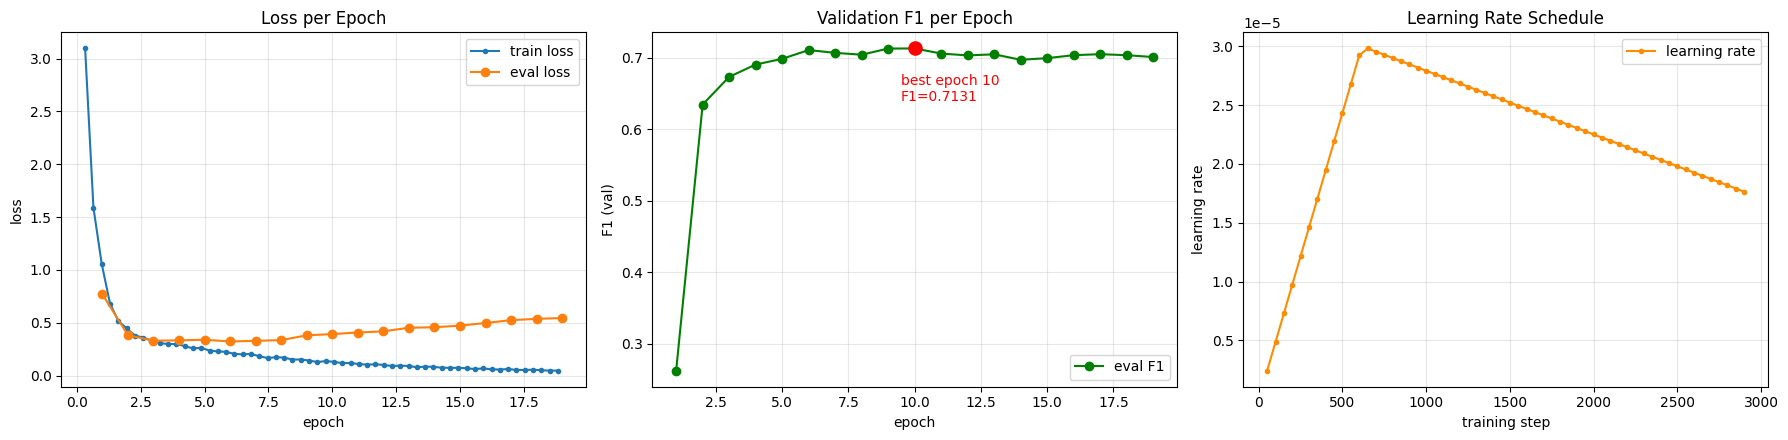


Ringkasan per epoch (model terbaik dipilih via load_best_model_at_end):


,epoch,eval_loss,eval_f1,eval_precision,eval_recall
0,1.0,0.7706,0.2628,0.3292,0.2186
1,2.0,0.3825,0.6347,0.6065,0.6657
2,3.0,0.3304,0.6734,0.6405,0.7100
3,4.0,0.3337,0.6906,0.6549,0.7304
4,5.0,0.3394,0.6986,0.6624,0.7391
5,6.0,0.3231,0.7108,0.6800,0.7446
6,7.0,0.3291,0.7070,0.6803,0.7359
7,8.0,0.3360,0.7044,0.6706,0.7417
8,9.0,0.3813,0.7130,0.6883,0.7395
9,10.0,0.3930,0.7131,0.6935,0.7339


In [26]:
from seqeval.metrics import precision_score, recall_score

def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=2)
    true_lab, pred_lab = [], []
    for pr, la in zip(preds, p.label_ids):
        tl = [ID2LABEL[l] for (pp,l) in zip(pr,la) if l != -100]
        pl = [ID2LABEL[pp] for (pp,l) in zip(pr,la) if l != -100]
        true_lab.append(tl); pred_lab.append(pl)
    return {"precision": precision_score(true_lab,pred_lab),
            "recall": recall_score(true_lab,pred_lab),
            "f1": seq_f1(true_lab,pred_lab)}


# ===========================================================================
# (v8) PERBAIKAN BUG SEED
# ---------------------------------------------------------------------------
# Di v5 asli, urutannya adalah:
#     model = AutoModelForTokenClassification.from_pretrained(...)   <- bobot
#                                                                        classifier
#                                                                        acak DI SINI
#     args  = TrainingArguments(..., seed=CONFIG.SEED)                <- seed baru
#                                                                        disebut di sini
# Trainer memang memanggil set_seed() secara internal, tapi model SUDAH
# terlanjur dibuat dengan bobot classifier.weight/classifier.bias yang acak
# dan tidak terkunci seed.
#
# Perbaikan: set_seed_all() dipanggil EKSPLISIT sebelum from_pretrained().
# ===========================================================================
set_seed_all(CONFIG.SEED, deterministic=CONFIG.DETERMINISTIC)

# ===========================================================================
# (v9) PERBAIKAN: cegah Trainer membungkus model dengan nn.DataParallel
# ---------------------------------------------------------------------------
# Kalau environment mendeteksi >1 GPU, HF Trainer otomatis membungkus model
# dengan torch.nn.DataParallel. Objek hasil bungkusan itu tidak punya atribut
# `.config` langsung (harus lewat `.module.config`), sehingga compute_loss
# custom di WeightedTrainer error: "'DataParallel' object has no attribute
# 'config'". Cara paling aman & sederhana: paksa hanya 1 GPU yang terlihat
# SEBELUM model dibuat, supaya Trainer tidak pernah membungkusnya.
# ===========================================================================
import torch
if torch.cuda.device_count() > 1:
    print(f"Terdeteksi {torch.cuda.device_count()} GPU -> membatasi ke 1 GPU "
          f"untuk menghindari DataParallel wrapping.")
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"

model = AutoModelForTokenClassification.from_pretrained(
    CONFIG.MODEL_NAME, num_labels=len(IOB_LABELS), id2label=ID2LABEL, label2id=LABEL2ID)

args = TrainingArguments(
    output_dir=f"{CONFIG.OUTPUT_DIR}/indobert-ner",
    learning_rate=CONFIG.LR,                      # 3e-5 (v5 asli, terbukti terbaik)
    lr_scheduler_type=CONFIG.LR_SCHEDULER,
    warmup_ratio=CONFIG.WARMUP_RATIO,
    per_device_train_batch_size=CONFIG.BATCH_SIZE,
    per_device_eval_batch_size=CONFIG.BATCH_SIZE,
    num_train_epochs=CONFIG.EPOCHS,                # 40 (v5: 20)
    weight_decay=CONFIG.WEIGHT_DECAY,
    eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True,
    metric_for_best_model="f1", greater_is_better=True,
    seed=CONFIG.SEED, data_seed=CONFIG.SEED,       # keduanya eksplisit
    save_total_limit=2,
    logging_steps=50, report_to="none",
    disable_tqdm=True,     # progress bar teks -> tidak ada error widget
)

collator = DataCollatorForTokenClassification(tokenizer)
TrainerCls = WeightedTrainer if CONFIG.USE_CLASS_WEIGHTS else Trainer
trainer = TrainerCls(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                     processing_class=tokenizer, data_collator=collator,
                     compute_metrics=compute_metrics,
                     # (v8) early stopping: aman menaikkan epoch ke 40
                     callbacks=[EarlyStoppingCallback(early_stopping_patience=CONFIG.EARLY_STOP)])

print("=" * 62)
print("KONFIGURASI RUN")
print("=" * 62)
print(f"  learning rate   : {args.learning_rate:.2e}")
print(f"  scheduler       : {args.lr_scheduler_type} + warmup {args.warmup_ratio:.0%}")
print(f"  epoch maksimum  : {args.num_train_epochs}  (early stop patience {CONFIG.EARLY_STOP})")
print(f"  seed            : {args.seed}  (data_seed={args.data_seed})")
print(f"  class weights   : {CONFIG.USE_CLASS_WEIGHTS}")
print("=" * 62 + "\n")

trainer.train()
trainer.save_model(f"{CONFIG.OUTPUT_DIR}/indobert-ner-best")
print("Pelatihan selesai & model tersimpan.")

# --- Grafik loss, F1, & learning rate per epoch ---
import matplotlib.pyplot as plt
hist = trainer.state.log_history
tr_loss = [(h["epoch"], h["loss"]) for h in hist if "loss" in h and "eval_loss" not in h]
ev = [(h["epoch"], h.get("eval_loss"), h.get("eval_f1")) for h in hist if "eval_loss" in h]
lr_hist = [(h.get("epoch"), h.get("step"), h["learning_rate"]) for h in hist if "learning_rate" in h]

if lr_hist:
    print(f"Learning rate puncak tercatat : {max(lr for _,_,lr in lr_hist):.2e}")
    print(f"Learning rate akhir tercatat  : {lr_hist[-1][2]:.2e}")

fig, ax = plt.subplots(1, 3, figsize=(18,4.5))
if tr_loss:
    ax[0].plot([e for e,_ in tr_loss],[l for _,l in tr_loss], label="train loss", marker=".")
if ev:
    ax[0].plot([e for e,_,_ in ev],[l for _,l,_ in ev], label="eval loss", marker="o")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].set_title("Loss per Epoch")
ax[0].legend(); ax[0].grid(alpha=.3)

if ev:
    eps=[e for e,_,_ in ev]; f1s=[f for _,_,f in ev]
    ax[1].plot(eps, f1s, color="green", marker="o", label="eval F1")
    best_i=int(np.argmax(f1s))
    ax[1].scatter([eps[best_i]],[f1s[best_i]], color="red", zorder=5, s=90)
    ax[1].annotate(f"best epoch {eps[best_i]:.0f}\nF1={f1s[best_i]:.4f}",
                   (eps[best_i], f1s[best_i]), textcoords="offset points", xytext=(-10,-38), color="red")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("F1 (val)"); ax[1].set_title("Validation F1 per Epoch")
    ax[1].grid(alpha=.3); ax[1].legend()

    print("\n" + "="*62)
    if best_i >= len(f1s) - 2:
        print("!! F1 TERBAIK ADA DI EPOCH TERAKHIR -> MASIH BELUM PLATEAU.")
        print("   Pertimbangkan menaikkan CONFIG.EPOCHS lebih lanjut.")
    else:
        print(f"OK - F1 plateau di epoch {eps[best_i]:.0f} "
              f"({len(f1s)-1-best_i} epoch tanpa perbaikan sesudahnya).")
        print(f"   Early stopping bekerja sebagaimana mestinya.")
    print("="*62)

if lr_hist:
    ax[2].plot([s for _,s,_ in lr_hist], [lr for _,_,lr in lr_hist], color="darkorange",
               marker=".", label="learning rate")
    ax[2].set_xlabel("training step"); ax[2].set_ylabel("learning rate")
    ax[2].set_title("Learning Rate Schedule"); ax[2].grid(alpha=.3); ax[2].legend()
    ax[2].ticklabel_format(axis="y", style="sci", scilimits=(0,0))
plt.tight_layout()
plt.savefig(f"{CONFIG.OUTPUT_DIR}/training_curves_v8.png", dpi=150)
plt.show()

hist_df = pd.DataFrame([{"epoch":h.get("epoch"), "eval_loss":h.get("eval_loss"),
                         "eval_f1":h.get("eval_f1"), "eval_precision":h.get("eval_precision"),
                         "eval_recall":h.get("eval_recall")} for h in hist if "eval_loss" in h])
hist_df.to_csv(f"{CONFIG.OUTPUT_DIR}/training_history_v8.csv", index=False)
print("\nRingkasan per epoch (model terbaik dipilih via load_best_model_at_end):")
display(hist_df.round(4))

## 8 · Evaluasi & Analisis Kesalahan (III.9)
Evaluasi entity-level dengan seqeval (micro, macro, per-label) lalu **analisis kesalahan**:
`boundary error`, `wrong label`, `missed entity`, `spurious entity`, serta fokus pada kebingungan
SKILL / TOOL / PROGRAMMING_LANGUAGE.

In [27]:
# ===========================================================================
# (v18) DEKODE BERKENDALA IOB2 (VITERBI)
# ---------------------------------------------------------------------------
# argmax memilih label terbaik per token secara TERPISAH, sehingga urutan yang
# tidak mungkin secara IOB2 bisa lolos:
#     O        -> I-SKILL     (lanjutan tanpa awalan)
#     B-TOOL   -> I-SKILL     (lanjutan beda jenis entitas)
# Urutan cacat seperti ini langsung merusak batas span. Viterbi mencari
# urutan label dengan skor total tertinggi DI ANTARA urutan yang valid saja.
# ===========================================================================
def build_transition_mask():
    """M[i,j] = 0 bila transisi label i -> j sah, -inf bila ilegal."""
    K = len(IOB_LABELS)
    M = np.zeros((K, K), dtype=np.float64)
    for i, li in enumerate(IOB_LABELS):
        for j, lj in enumerate(IOB_LABELS):
            if lj.startswith("I-"):
                ent = lj[2:]
                if li not in (f"B-{ent}", f"I-{ent}"):
                    M[i, j] = -np.inf
    return M

TRANS_MASK = build_transition_mask()
_start_mask = np.array([-np.inf if l.startswith("I-") else 0.0 for l in IOB_LABELS])

def viterbi_decode(logits, mask):
    """logits: (T, K) untuk token valid saja. Mengembalikan list id label."""
    T, K = logits.shape
    logp = logits - logits.max(axis=1, keepdims=True)
    logp = logp - np.log(np.exp(logp).sum(axis=1, keepdims=True))
    dp = logp[0] + _start_mask
    bp = np.zeros((T, K), dtype=np.int32)
    for t in range(1, T):
        scores = dp[:, None] + mask + logp[t][None, :]
        bp[t] = np.argmax(scores, axis=0)
        dp = scores[bp[t], np.arange(K)]
    path = [int(np.argmax(dp))]
    for t in range(T - 1, 0, -1):
        path.append(int(bp[t, path[-1]]))
    return path[::-1]


# --- Prediksi test set ---
pred_out = trainer.predict(test_ds)

y_true, y_pred, y_pred_argmax = [], [], []
for lg, la in zip(pred_out.predictions, pred_out.label_ids):
    keep = la != -100
    if keep.sum() == 0:
        continue
    lg_v = lg[keep]
    ids_arg = np.argmax(lg_v, axis=1).tolist()
    ids = viterbi_decode(lg_v, TRANS_MASK) if CONFIG.CONSTRAINED_DECODING else ids_arg
    y_true.append([ID2LABEL[l] for l in la[keep]])
    y_pred.append([ID2LABEL[i] for i in ids])
    y_pred_argmax.append([ID2LABEL[i] for i in ids_arg])

mode = "Viterbi berkendala" if CONFIG.CONSTRAINED_DECODING else "argmax"
print(f"Mode dekode: {mode}\n")

# Perbandingan langsung argmax vs Viterbi -- untuk tabel ablasi di skripsi
if CONFIG.CONSTRAINED_DECODING:
    f1_arg = seq_f1(y_true, y_pred_argmax)
    f1_vit = seq_f1(y_true, y_pred)
    n_ilegal = sum(1 for seq in y_pred_argmax for a, b in zip(["O"] + seq, seq)
                   if b.startswith("I-") and a not in (f"B-{b[2:]}", f"I-{b[2:]}"))
    print(f"  argmax  : F1 = {f1_arg:.4f}   (urutan IOB2 ilegal: {n_ilegal:,} token)")
    print(f"  Viterbi : F1 = {f1_vit:.4f}   (urutan ilegal dijamin 0)")
    print(f"  selisih : {f1_vit - f1_arg:+.4f}\n")

print(f"=== IndoBERT — entity-level F1 STRICT (micro): {seq_f1(y_true,y_pred):.4f} ===")
print(seq_report(y_true, y_pred, digits=3))


# ===========================================================================
# (v18) EVALUASI PARTIAL MATCH (label sama + span bertumpang tindih)
# ---------------------------------------------------------------------------
# Justifikasi: analisis sensitivitas IAA pada penelitian ini menunjukkan
# rata-rata Cohen's Kappa naik dari ~0,69 ke ~0,755 ketika toleransi kecocokan
# batas dilonggarkan -- artinya ANOTATOR MANUSIA SENDIRI tidak sepakat soal
# batas span. Menuntut kecocokan batas sempurna pada gold yang batasnya berisik
# tidak proporsional. STRICT tetap metrik utama; PARTIAL dilaporkan sebagai
# pendamping, mengikuti praktik MUC-5 / SemEval.
# ===========================================================================
def spans_of(tags):
    ents, cur = [], None
    for i, t in enumerate(tags):
        if t.startswith("B-"):
            if cur: ents.append(tuple(cur))
            cur = [t[2:], i, i]
        elif t.startswith("I-") and cur and cur[0] == t[2:]:
            cur[2] = i
        else:
            if cur: ents.append(tuple(cur)); cur = None
    if cur: ents.append(tuple(cur))
    return ents

def partial_match_report(y_true, y_pred, labels=None):
    tp, fp, fn = Counter(), Counter(), Counter()
    for gt, pt in zip(y_true, y_pred):
        ge, pe = spans_of(gt), spans_of(pt)
        used_g, used_p, cand = set(), set(), []
        for gi, (gl, gs, gee) in enumerate(ge):
            for pi, (pl, ps, pee) in enumerate(pe):
                if gl != pl: continue
                ov = min(gee, pee) - max(gs, ps) + 1
                if ov > 0: cand.append((ov, gi, pi, gl))
        for ov, gi, pi, lab in sorted(cand, reverse=True):
            if gi in used_g or pi in used_p: continue
            used_g.add(gi); used_p.add(pi); tp[lab] += 1
        for gi, (gl, _, _) in enumerate(ge):
            if gi not in used_g: fn[gl] += 1
        for pi, (pl, _, _) in enumerate(pe):
            if pi not in used_p: fp[pl] += 1
    labs = labels or sorted(set(tp) | set(fp) | set(fn))
    rows = []
    for l in labs:
        p = tp[l]/(tp[l]+fp[l]) if tp[l]+fp[l] else 0.0
        r = tp[l]/(tp[l]+fn[l]) if tp[l]+fn[l] else 0.0
        f = 2*p*r/(p+r) if p+r else 0.0
        rows.append({"label": l, "precision": p, "recall": r, "f1": f,
                     "support": tp[l]+fn[l]})
    TP, FP, FN = sum(tp.values()), sum(fp.values()), sum(fn.values())
    P = TP/(TP+FP) if TP+FP else 0.0
    R = TP/(TP+FN) if TP+FN else 0.0
    F = 2*P*R/(P+R) if P+R else 0.0
    rows.append({"label": "micro avg", "precision": P, "recall": R, "f1": F,
                 "support": TP+FN})
    return pd.DataFrame(rows), F

pm_df, pm_f1 = partial_match_report(y_true, y_pred)
print(f"\n=== IndoBERT — entity-level F1 PARTIAL (micro): {pm_f1:.4f} ===")
display(pm_df.round(3))


# --- Evaluasi KHUSUS entitas keterampilan (III.9) ---
def filter_skill_only(seqs):
    return [[t if (t == "O" or t.split("-")[-1] in CONFIG.SKILL_LABELS) else "O"
             for t in seq] for seq in seqs]

ys_t, ys_p = filter_skill_only(y_true), filter_skill_only(y_pred)
sk_df, sk_pm = partial_match_report(ys_t, ys_p, labels=CONFIG.SKILL_LABELS)
print("\n=== Evaluasi KHUSUS entitas keterampilan ===")
print(f"F1 skill-only STRICT  (micro): {seq_f1(ys_t, ys_p):.4f}")
print(f"F1 skill-only PARTIAL (micro): {sk_pm:.4f}")
print(seq_report(ys_t, ys_p, digits=3))

# ===========================================================================
# (v19) TOKEN-LEVEL ACCURACY
# ---------------------------------------------------------------------------
# CATATAN PENTING: accuracy pada NER dihitung PER TOKEN, sedangkan
# Precision/Recall/F1 di atas dihitung PER ENTITAS. Keduanya TIDAK sebanding.
# Karena ~49% token berlabel 'O', model yang menebak semua token sebagai 'O'
# sudah memperoleh accuracy ~0,49 tanpa mengenali satu entitas pun. Karena itu
# accuracy jarang dilaporkan pada penelitian NER; disertakan di sini hanya
# untuk melengkapi tabel, dengan baseline trivial sebagai pembanding.
# ===========================================================================
from seqeval.metrics import accuracy_score as seq_acc

acc_all   = seq_acc(y_true, y_pred)
acc_skill = seq_acc(ys_t, ys_p)

_n_tok = sum(len(s) for s in y_true)
_n_o   = sum(1 for s in y_true for t in s if t == "O")
_baseline_o = _n_o / _n_tok

print("\n=== Token-level accuracy ===")
print(f"  Semua entitas            : {acc_all:.4f}")
print(f"  Keterampilan saja        : {acc_skill:.4f}")
print(f"  Baseline trivial (all-O) : {_baseline_o:.4f}   <- ambang bawah")
print(f"  Selisih thd baseline     : {acc_all - _baseline_o:+.4f}")
print(f"  Total token dievaluasi   : {_n_tok:,}")

# --- Tabel ringkas untuk bab Hasil ---
_ringkas = pd.DataFrame([
    {"skema": "Semua entitas",     "strict_f1": seq_f1(y_true, y_pred), "partial_f1": pm_f1},
    {"skema": "Keterampilan saja", "strict_f1": seq_f1(ys_t, ys_p),     "partial_f1": sk_pm},
])
_ringkas["class_weights"] = CONFIG.USE_CLASS_WEIGHTS
_ringkas["decoding"] = mode
_ringkas.to_csv(f"{CONFIG.OUTPUT_DIR}/eval_summary_cw{int(CONFIG.USE_CLASS_WEIGHTS)}.csv", index=False)
print("\nRingkasan (untuk tabel skripsi):")
display(_ringkas.round(4))
print(f"\nDisimpan ke outputs/eval_summary_cw{int(CONFIG.USE_CLASS_WEIGHTS)}.csv")
print("-> Jalankan ulang dengan USE_CLASS_WEIGHTS=False, lalu bandingkan kedua berkas.")


Mode dekode: Viterbi berkendala

  argmax  : F1 = 0.7116   (urutan IOB2 ilegal: 754 token)
  Viterbi : F1 = 0.7271   (urutan ilegal dijamin 0)
  selisih : +0.0155

=== IndoBERT — entity-level F1 STRICT (micro): 0.7271 ===
                      precision    recall  f1-score   support

             COMPANY      0.738     0.683     0.709       252
        DEGREE_FIELD      0.895     0.925     0.910       535
     EDUCATION_LEVEL      0.832     0.819     0.826       708
     EMPLOYMENT_TYPE      0.638     0.673     0.655        55
    EXPERIENCE_YEARS      0.949     0.964     0.956       440
            INDUSTRY      0.637     0.588     0.611       376
           JOB_TITLE      0.683     0.694     0.688       592
            LOCATION      0.731     0.802     0.765       460
PROGRAMMING_LANGUAGE      0.536     0.750     0.625        20
      RESPONSIBILITY      0.683     0.708     0.695      4028
              SALARY      0.467     0.519     0.491        27
               SKILL      0.543  

,label,precision,recall,f1,support
0,COMPANY,0.837,0.774,0.804,252
1,DEGREE_FIELD,0.922,0.953,0.938,535
2,EDUCATION_LEVEL,0.925,0.911,0.918,708
3,EMPLOYMENT_TYPE,0.655,0.691,0.673,55
4,EXPERIENCE_YEARS,0.975,0.991,0.983,440
5,INDUSTRY,0.729,0.673,0.700,376
6,JOB_TITLE,0.757,0.770,0.764,592
7,LOCATION,0.848,0.930,0.887,460
8,PROGRAMMING_LANGUAGE,0.607,0.850,0.708,20
9,RESPONSIBILITY,0.892,0.925,0.908,4027



=== Evaluasi KHUSUS entitas keterampilan ===
F1 skill-only STRICT  (micro): 0.7141
F1 skill-only PARTIAL (micro): 0.8209
                      precision    recall  f1-score   support

PROGRAMMING_LANGUAGE      0.536     0.750     0.625        20
               SKILL      0.543     0.618     0.578      1933
          SOFT_SKILL      0.765     0.810     0.787      2804
                TOOL      0.814     0.758     0.785      1072

           micro avg      0.693     0.736     0.714      5829
           macro avg      0.664     0.734     0.694      5829
        weighted avg      0.700     0.736     0.717      5829


=== Token-level accuracy ===
  Semua entitas            : 0.8967
  Keterampilan saja        : 0.9549
  Baseline trivial (all-O) : 0.4892   <- ambang bawah
  Selisih thd baseline     : +0.4074
  Total token dievaluasi   : 113,771

Ringkasan (untuk tabel skripsi):


,skema,strict_f1,partial_f1,class_weights,decoding
0,Semua entitas,0.7271,0.8578,False,Viterbi berkendala
1,Keterampilan saja,0.7141,0.8209,False,Viterbi berkendala



Disimpan ke outputs/eval_summary_cw0.csv
-> Jalankan ulang dengan USE_CLASS_WEIGHTS=False, lalu bandingkan kedua berkas.


In [28]:
# Ekstraksi entitas (span) dari urutan IOB untuk analisis kesalahan
def extract_entities(tags):
    ents, cur = [], None
    for i,t in enumerate(tags):
        if t.startswith("B-"):
            if cur: ents.append(cur)
            cur = [t[2:], i, i]
        elif t.startswith("I-") and cur and cur[0]==t[2:]:
            cur[2] = i
        else:
            if cur: ents.append(cur); cur=None
    if cur: ents.append(cur)
    return [tuple(e) for e in ents]   # (label, start, end)

err = Counter()
confusion = Counter()   # (gold_label, pred_label) untuk span dgn boundary sama
for gt, pt in zip(y_true, y_pred):
    ge, pe = extract_entities(gt), extract_entities(pt)
    gset = {(s,e):lab for lab,s,e in ge}
    pset = {(s,e):lab for lab,s,e in pe}
    gspans, pspans = set(gset), set(pset)
    # exact match
    for span in gspans & pspans:
        if gset[span]==pset[span]: err["correct"] += 1
        else:
            err["wrong_label"] += 1
            confusion[(gset[span], pset[span])] += 1
    # missed (gold ada, tak ada prediksi exact)
    for span in gspans - pspans:
        # cek boundary error: ada prediksi yg overlap
        overlap = any(not (pe_e < span[0] or pe_s > span[1]) for _,pe_s,pe_e in pe)
        err["boundary_error" if overlap else "missed_entity"] += 1
    # spurious (prediksi ada, gold tak ada exact & tak overlap)
    for span in pspans - gspans:
        overlap = any(not (ge_e < span[0] or ge_s > span[1]) for _,ge_s,ge_e in ge)
        if not overlap: err["spurious_entity"] += 1

print("Analisis kesalahan (entity-level):")
for k,v in err.most_common(): print(f"  {k}: {v:,}")
print("\nTop kebingungan label (gold -> pred):")
for (g,p),c in confusion.most_common(10): print(f"  {g} -> {p}: {c}")

# Fokus SKILL/TOOL/PROGRAMMING_LANGUAGE
stp = {("SKILL","TOOL"),("TOOL","SKILL"),("SKILL","PROGRAMMING_LANGUAGE"),
       ("PROGRAMMING_LANGUAGE","SKILL"),("TOOL","PROGRAMMING_LANGUAGE"),
       ("PROGRAMMING_LANGUAGE","TOOL")}
n_stp = sum(confusion[k] for k in stp)
print(f"\nKebingungan SKILL/TOOL/PROG_LANG: {n_stp} kasus")

Analisis kesalahan (entity-level):
  correct: 9,867
  boundary_error: 2,430
  spurious_entity: 1,208
  missed_entity: 649
  wrong_label: 355

Top kebingungan label (gold -> pred):
  TOOL -> SKILL: 60
  JOB_TITLE -> SKILL: 40
  SKILL -> SOFT_SKILL: 35
  SKILL -> JOB_TITLE: 31
  INDUSTRY -> SKILL: 30
  SKILL -> RESPONSIBILITY: 27
  RESPONSIBILITY -> SKILL: 24
  SKILL -> TOOL: 23
  SOFT_SKILL -> SKILL: 17
  SKILL -> INDUSTRY: 11

Kebingungan SKILL/TOOL/PROG_LANG: 88 kasus


### 8b · Normalisasi Nama Keterampilan
Menyatukan varian penulisan skill yang bermakna sama sebelum agregasi/penyimpanan:
`excel = ms excel = microsoft excel` → **microsoft excel**; `SIM C` → **mengendarai motor**,
`SIM A` → **mengendarai mobil**, `SIM B` → **mengendarai truk**; `teamwork = kerjasama tim` →
**kerja sama tim**; dst. Catatan: `microsoft office` / `microsoft word` **tetap terpisah** dari excel.

In [29]:
import re
def _clean(t):
    t=t.lower().strip(); t=re.sub(r"\s+"," ",t); t=re.sub(r"[.,;:/]+$","",t).strip()
    return t
# variant -> canonical (varian permukaan & sinonim makna)
SKILL_CANONICAL = {
    # Excel (semua varian -> microsoft excel)
    "excel":"microsoft excel","ms excel":"microsoft excel","ms. excel":"microsoft excel",
    "ms.excel":"microsoft excel","excell":"microsoft excel","microsoft office excel":"microsoft excel",
    "ms office excel":"microsoft excel","rumus excel":"microsoft excel","excel dasar":"microsoft excel",
    "excel advanced":"microsoft excel","excel lanjutan":"microsoft excel","rumus dasar excel":"microsoft excel",
    "microsoft excel":"microsoft excel",
    # Word
    "word":"microsoft word","ms word":"microsoft word","ms. word":"microsoft word","ms.word":"microsoft word",
    "microsoft words":"microsoft word","words":"microsoft word","microsoft office word":"microsoft word",
    "microsoft word":"microsoft word",
    # PowerPoint
    "powerpoint":"microsoft powerpoint","power point":"microsoft powerpoint","ppt":"microsoft powerpoint",
    "ms power point":"microsoft powerpoint","ms. power point":"microsoft powerpoint",
    "ms. powerpoint":"microsoft powerpoint","power poin":"microsoft powerpoint","microsoft powerpoint":"microsoft powerpoint",
    # Office (TERPISAH dari excel/word)
    "microsoft office":"microsoft office","ms office":"microsoft office","ms. office":"microsoft office",
    "ms.office":"microsoft office","msoffice":"microsoft office","office":"microsoft office",
    "microsof office":"microsoft office","msc. office":"microsoft office",
    # Power BI
    "power bi":"power bi","powerbi":"power bi",
    # SIM / mengemudi (normalisasi makna)
    "sim c":"mengendarai motor","sim (c)":"mengendarai motor","sim aktif c":"mengendarai motor",
    "sim a":"mengendarai mobil",
    "sim b":"mengendarai truk","sim b1":"mengendarai truk","sim b2":"mengendarai truk",
    "sim b1 umum":"mengendarai truk","sim bi umum":"mengendarai truk",
    "motor":"mengendarai motor","sepeda motor":"mengendarai motor","mengendara motor":"mengendarai motor",
    "mengendarai sepeda motor":"mengendarai motor","mengendarai kendaraan motor":"mengendarai motor",
    "mengendarai motor":"mengendarai motor",
    "mobil":"mengendarai mobil","menyetir mobil":"mengendarai mobil","mengendari mobil":"mengendarai mobil",
    "megendarai mobil":"mengendarai mobil","mengendarai mobil":"mengendarai mobil","membawa mobil":"mengendarai mobil",
    "truk":"mengendarai truk","mengemudi truk":"mengendarai truk",
    # Sinonim soft/skill umum
    "komunikasi":"komunikasi","kemampuan komunikasi":"komunikasi","komunikasi yang baik":"komunikasi",
    "komunikasi efektif":"komunikasi","skill komunikasi":"komunikasi","kemampuan komunikasi yang baik":"komunikasi",
    "kerja sama tim":"kerja sama tim","kerjasama tim":"kerja sama tim","kerja tim":"kerja sama tim",
    "teamwork":"kerja sama tim","team work":"kerja sama tim","bekerja dalam tim":"kerja sama tim",
    "tim":"kerja sama tim","kerja secara tim":"kerja sama tim","bekerja sama dalam tim":"kerja sama tim",
    "microsoft word dan excel":"microsoft office",
    "analisa data":"analisis data","analisis data":"analisis data","data analysis":"analisis data",
    "digital marketing":"digital marketing","pemasaran digital":"digital marketing",
    "social media":"social media","sosial media":"social media","media sosial":"social media",
}
def normalize_skill(text):
    t=_clean(text)
    if t in SKILL_CANONICAL: return SKILL_CANONICAL[t]
    # fallback: expand "ms"/"ms." -> "microsoft", coba lagi
    t2=re.sub(r"\bms\.?\b","microsoft",t); t2=re.sub(r"\s+"," ",t2).strip()
    if t2 in SKILL_CANONICAL: return SKILL_CANONICAL[t2]
    return t


# Cek dampak normalisasi pada data
_before = len(set(s["text"].lower().strip() for d in DOCS for s in d.get("enriched_skills",[])))
_after  = len(set(normalize_skill(s["text"]) for d in DOCS for s in d.get("enriched_skills",[])))
print(f"Skill unik: sebelum {_before} -> sesudah normalisasi {_after}")
print("Contoh:", normalize_skill("ms. excel"), "|", normalize_skill("SIM C"), "|", normalize_skill("teamwork"))

Skill unik: sebelum 13520 -> sesudah normalisasi 13360
Contoh: microsoft excel | mengendarai motor | kerja sama tim


### 8c · Normalisasi Nama Job Title

Menyatukan judul jabatan yang sama tapi tertulis berbeda -- beda
kapitalisasi atau beda urutan kata. Kunci pengelompokan: himpunan kata
dalam judul (diabaikan urutan & kapital). Judul dengan jumlah kata
BERBEDA tetap dipisah (mis. "Software Engineer" vs "Software Engineer
(Backend)" tidak digabung, karena "Backend" mengubah makna).


In [30]:
# ===========================================================================
# (v11) NORMALISASI NAMA JOB TITLE
# ===========================================================================
from collections import defaultdict as _dd

# ---------- Stage 0: pembersihan permukaan ----------
def _clean_title(t):
    t = re.sub(r"\s+", " ", t.strip())
    t = re.sub(r"^[\-\u2013\u2014/,:;]+|[\-\u2013\u2014/,:;]+$", "", t).strip()
    return t

# ---------- Stage 1: perbaikan salah ketik gabungan kata (dari data nyata) ----------
TITLE_CONCAT_FIX = {
    "hostlive": "host live",
    "livestream": "live stream",
    "livestreaming": "live streaming",
}
def _fix_title_concat(t):
    return " ".join(TITLE_CONCAT_FIX.get(w.lower(), w) for w in t.split())

# ---------- Stage 2: title-case dengan daftar akronim & merek ----------
# (v11) Daftar diverifikasi terhadap token huruf besar yang benar-benar sering
# muncul di 3.171 judul unik pada database Anda -- bukan tebakan.
TITLE_ACRONYMS = {"it","hr","ga","cs","hse","k3","pic","qms","aspr","ppic","qc","qa",
                  "sdm","mice","seo","sem","crm","erp","ui","ux","b2b","b2c","sop",
                  "spg","rd","spv","kol","mt","hrga","hrd","cctv","ai","ac","ob","ar",
                  "qaqc","fb","pt","pos","k3l","bpjs","spbu","exim"}
TITLE_BRAND_CASE = {"tiktok": "TikTok", "whatsapp": "WhatsApp", "youtube": "YouTube",
                    "iphone": "iPhone", "ios": "iOS"}
_TITLE_TOKEN_RE = re.compile(r"^(\W*)(\w+)(\W*)$", re.UNICODE)

def _smart_title_case(t):
    out = []
    for w in t.split():
        m = _TITLE_TOKEN_RE.match(w)
        if not m:
            out.append(w); continue
        lead, core, trail = m.groups()
        lc = core.lower()
        if lc in TITLE_ACRONYMS:
            cased = core.upper()
        elif lc in TITLE_BRAND_CASE:
            cased = TITLE_BRAND_CASE[lc]
        elif core == "&":
            cased = "&"
        else:
            cased = core[:1].upper() + core[1:].lower()
        out.append(lead + cased + trail)
    return " ".join(out)

# ---------- Stage 2b: pembuangan SUFIKS LOKASI (v13) ----------
# Masalah: "Host Live (Malang)" dan "Waiters Malang" berdiri sendiri, terpisah
# dari "Host Live" / "Waiters", padahal lokasi bukan pembeda JENIS pekerjaan.
# Aturan Stage 3 (kunci token) tidak bisa menggabungkannya karena jumlah
# katanya berbeda -- dan aturan itu memang sengaja begitu, supaya
# "Software Engineer (Backend)" tidak tertelan "Software Engineer".
#
# Solusi: buang nama lokasi HANYA pada posisi struktural yang jelas, memakai
# gazetteer dari tabel `locations` pada data itu sendiri (bukan daftar tebakan).
_LOC_RAW = [m.get("location") for d in DOCS for m in [d["meta"]] if m.get("location")]

# Banyak nama lokasi Indonesia kebetulan kata benda umum. Kalau dibuang mentah,
# "Operator Kelapa Sawit" / "Staff Taman" / "Tutor Bahasa Indonesia" akan rusak.
TITLE_BLOCK_LOC = {
    "indonesia", "sawit", "taman", "batu", "teras", "kapas", "pare", "metro",
    "jati", "candi", "baki", "kuta", "pati", "panji", "turi", "tugu", "setu",
    "dau", "moga", "ibun", "babo", "deket", "suruh", "pace", "wates", "sooko",
    "kurun", "lalan", "gabus", "ampel", "baron", "ceper", "boja", "jenu",
    # (v13) kata umum yang ikut terbawa saat menurunkan token dari nama majemuk
    "kelapa", "karang", "gunung", "kembar", "pinang", "seribu", "kedung",
    "bojong", "balong", "halang", "pesisir", "rantau", "sindang", "bandar",
    "kapanewon", "kepulauan", "kijang", "merapi", "madang",
}
# Arah mata angin & kata administratif -- tidak pernah berdiri sebagai lokasi
_TITLE_LOC_DIRECTION = {"selatan", "utara", "barat", "timur", "pusat", "tengah",
                        "raya", "baru", "besar", "kota", "kab", "kabupaten"}

# Gazetteer dasar: nama lokasi utuh dari data
_gaz = {l.strip().lower() for l in _LOC_RAW if l.strip()}
# (v13) Turunkan juga kata inti dari nama majemuk: tabel `locations` hanya
# punya "Bandar Lampung"/"Lampung Selatan", padahal judul menulis
# "Host Live (Lampung)". Tanpa penurunan ini, "Lampung" tidak dikenali.
for _l in list(_gaz):
    _ws = _l.split()
    if len(_ws) > 1:
        for _w in _ws:
            if _w not in _TITLE_LOC_DIRECTION and len(_w) >= 6:
                _gaz.add(_w)

_TITLE_LOC_GAZ = sorted(
    {l for l in _gaz if l not in TITLE_BLOCK_LOC and len(l) >= 4},
    key=len, reverse=True)          # terpanjang dulu: "Jakarta Selatan" > "Jakarta"

# Penanda lokasi murni -- aman dibuang di posisi mana pun
TITLE_LOC_CONNECTOR = {
    "domisili", "area", "kota", "kab", "kabupaten", "penempatan", "khusus",
    "wilayah", "region", "di", "untuk", "utk", "based", "placement", "lokasi",
    "seluruh", "cab",
}
# Kata fasilitas -- HANYA boleh ikut terbuang di dalam kurung / setelah tanda
# pisah. Kalau tidak dibatasi, "Staff Outlet Tasikmalaya" terpotong jadi
# "Staff", padahal "Staff Outlet" adalah nama jabatan.
TITLE_LOC_FACILITY = {"cabang", "depo", "factory", "pabrik", "store", "outlet", "gudang"}

_TITLE_LOC_RE = (re.compile(r"\b(" + "|".join(re.escape(l) for l in _TITLE_LOC_GAZ) + r")\b",
                            re.IGNORECASE) if _TITLE_LOC_GAZ else None)


def _seg_is_location_only(seg, allow_facility=False):
    """True bila segmen HANYA berisi nama lokasi (+ kata penghubung)."""
    if _TITLE_LOC_RE is None:
        return False
    seg = seg.strip(" ()[]-\u2013\u2014,.:;/")
    if not seg or not _TITLE_LOC_RE.search(seg):
        return False
    sisa = re.findall(r"[a-zA-Z]+", _TITLE_LOC_RE.sub(" ", seg))
    boleh = TITLE_LOC_CONNECTOR | (TITLE_LOC_FACILITY if allow_facility else set())
    return all(w.lower() in boleh for w in sisa)


def _strip_title_location(title):
    t = title.strip()

    # (1) kurung di akhir: "Host Live (Malang)", "Admin (Domisili Bali)"
    changed = True
    while changed:
        changed = False
        m = re.search(r"\s*[\(\[]([^\(\)\[\]]*)[\)\]]\s*$", t)
        if m and _seg_is_location_only(m.group(1), allow_facility=True):
            t = t[:m.start()].strip(); changed = True

    # (2) setelah - / \u2013 / , di akhir: "Admin Logistik - Depo Yogyakarta"
    changed = True
    while changed:
        changed = False
        m = re.search(r"\s*[-\u2013\u2014,]\s*([^-\u2013\u2014,]+)$", t)
        if m and _seg_is_location_only(m.group(1), allow_facility=True):
            t = t[:m.start()].strip(); changed = True

    # (3) lokasi menempel di akhir: "Waiters Malang", "Store Leader Bandung"
    changed = True
    while changed:
        changed = False
        words = t.split()
        for take in (3, 2, 1):                    # frasa terpanjang dulu
            if len(words) <= take:                # jangan sampai judul kosong
                continue
            if _seg_is_location_only(" ".join(words[-take:]), allow_facility=False):
                sisa = words[:-take]
                if sisa and any(re.search(r"[a-zA-Z]", w) for w in sisa):
                    t = " ".join(sisa).strip(" -\u2013\u2014,"); changed = True
                    break

    # (4) bersihkan sisa penghubung menggantung ("Staff Gudang Cab." ->
    #     "Staff Gudang"). HANYA bila tahap 1-3 memang membuang sesuatu --
    #     tanpa syarat ini, "Supervisor Area" (jabatan sah tanpa lokasi)
    #     ikut terpotong jadi "Supervisor".
    if t != title.strip():
        words = t.split()
        while len(words) > 1 and re.sub(r"[^a-zA-Z]", "", words[-1]).lower() in TITLE_LOC_CONNECTOR:
            words = words[:-1]
        t = " ".join(words)

    return t.strip(" -\u2013\u2014,.") or title.strip()


# ---------- Stage 3: kunci token terurut (mengabaikan urutan & kapital) ----------
def _title_token_key(t):
    words = [w.lower() for w in re.findall(r"[a-zA-Z0-9]+", t)]
    return tuple(sorted(words))

# ================= jalankan pada seluruh judul di DOCS =================
_raw_titles = [d["title"] for d in DOCS]
_title_counts = Counter(_raw_titles)

_stage_clean  = {t: _clean_title(t) for t in _title_counts}
_stage_concat = {t: _fix_title_concat(_stage_clean[t]) for t in _title_counts}
_stage_cased  = {t: _smart_title_case(_stage_concat[t]) for t in _title_counts}
# (v13) buang sufiks lokasi SEBELUM pengelompokan token, supaya
# "Host Live (Malang)" lebih dulu jadi "Host Live" dan baru kemudian
# ikut tergabung dengan varian kapitalisasi lain di Stage 3.
_stage_loc    = {t: _strip_title_location(_stage_cased[t]) for t in _title_counts}

_title_groups = defaultdict(list)
for raw, n in _title_counts.items():
    key = _title_token_key(_stage_loc[raw])
    _title_groups[key].append((raw, _stage_loc[raw], n))

TITLE_CANONICAL_MAP = {}
_title_alias_rows = []
for key, members in _title_groups.items():
    if len(key) == 0:
        for raw, disp, n in members: TITLE_CANONICAL_MAP[raw] = disp
        continue
    disp_freq = Counter()
    for raw, disp, n in members: disp_freq[disp] += n
    canonical = disp_freq.most_common(1)[0][0]
    for raw, disp, n in members:
        TITLE_CANONICAL_MAP[raw] = canonical
        if raw != canonical:
            _title_alias_rows.append({"judul_kanonik": canonical, "judul_mentah": raw, "n": n})

def normalize_title(raw_title):
    return TITLE_CANONICAL_MAP.get(
        raw_title,
        _strip_title_location(_smart_title_case(_fix_title_concat(_clean_title(raw_title)))))

# --- Dampak normalisasi ---
_n_loc_stripped = sum(1 for t in _title_counts if _stage_loc[t] != _stage_cased[t])
print(f"(v13) Judul yang sufiks lokasinya dibuang: {_n_loc_stripped}")
_n_before = len(_title_counts)
_n_after  = len(set(TITLE_CANONICAL_MAP.values()))
_n_groups_merged = sum(1 for key, m in _title_groups.items() if len({r for r,_,_ in m}) > 1)
print(f"Judul jabatan unik: sebelum {_n_before:,} -> sesudah {_n_after:,}")
print(f"Jumlah kelompok yang tergabung (>1 varian mentah): {_n_groups_merged}")

# --- Ekspor QA untuk diperiksa & diperluas manual ---
title_alias_df = (pd.DataFrame(_title_alias_rows).drop_duplicates()
                    .sort_values(["judul_kanonik","n"], ascending=[True, False])
                    .reset_index(drop=True)) if _title_alias_rows else pd.DataFrame(
                        columns=["judul_kanonik","judul_mentah","n"])
title_alias_df.to_csv(f"{CONFIG.OUTPUT_DIR}/qa_peta_judul.csv", index=False)
print(f"\nQA: {len(title_alias_df):,} pemetaan varian disimpan ke outputs/qa_peta_judul.csv")
print("     -> periksa berkas ini; tambahkan koreksi ke TITLE_CONCAT_FIX/TITLE_ACRONYMS bila perlu.")

print("\n15 kelompok penggabungan terbesar:")
_top = (title_alias_df.groupby("judul_kanonik")["n"].sum()
        .sort_values(ascending=False).head(15))
display(_top.reset_index().rename(columns={"n":"total_lowongan"}))


(v13) Judul yang sufiks lokasinya dibuang: 373
Judul jabatan unik: sebelum 3,171 -> sesudah 2,709
Jumlah kelompok yang tergabung (>1 varian mentah): 274

QA: 1,258 pemetaan varian disimpan ke outputs/qa_peta_judul.csv
     -> periksa berkas ini; tambahkan koreksi ke TITLE_CONCAT_FIX/TITLE_ACRONYMS bila perlu.

15 kelompok penggabungan terbesar:


,judul_kanonik,total_lowongan
0,Admin Sales,20
1,Desk Collection,14
2,Admin,13
3,Content Creator,12
4,Purchasing Staff,12
5,Admin Gudang,11
6,Sales Executive,10
7,Host Live Streaming,10
8,Operator Produksi,10
9,Crew Store,10


### 8d · Klasifikasi Jabatan (Pekerjaan) ke Golongan Pokok KBJI 2014

Kolom `title` pada tabel `jobs` secara konsep adalah nama **Pekerjaan** (silakan Anda ubah sendiri
penamaan kolomnya sesuai kebutuhan skripsi). Di sini setiap judul pekerjaan diklasifikasikan ke
salah satu dari **9 Golongan Pokok KBJI 2014** (kode 1–9 — kode 0/TNI-POLRI **dikecualikan**, sesuai
arahan dosen, karena tidak relevan untuk data lowongan sipil Glints).

Metode: cascade **lexicon → fuzzy → k-NN embedding** (arsitektur sama dengan `TaxonomyTagger` di
atas), tapi untuk tahap embedding dicocokkan ke **2.155 nama jabatan riil** yang diekstrak dari
dokumen KBJI 2014 (bukan cuma ke 9 judul golongan pokok saja) — jauh lebih akurat karena tiap
golongan direpresentasikan oleh ratusan contoh nyata dengan gaya penulisan yang mirip lowongan
kerja sehari-hari.

**Input tambahan (OPSIONAL sejak v15):** `kbji_referensi_jabatan.csv` — sejak tahap embedding dihapus, berkas ini TIDAK lagi dibutuhkan untuk mengklasifikasi. Bila di-attach, dipakai untuk validasi silang (sel 8e); bila tidak, notebook tetap berjalan normal
("Add Data" > "Upload"), berisi kolom `kode_jabatan, golongan_pokok_kode, golongan_pokok_nama,
nama_jabatan`.

In [31]:
import glob as _glob

GOLONGAN_POKOK_NAMA = {
    1: "Manajer",
    2: "Profesional",
    3: "Teknisi dan Asisten Profesional",
    4: "Tenaga Tata Usaha",
    5: "Tenaga Usaha Jasa dan Tenaga Penjualan",
    6: "Pekerja Terampil Pertanian, Kehutanan dan Perikanan",
    7: "Pekerja Pengolahan, Kerajinan, dan Ybdi",
    8: "Operator dan Perakit Mesin",
    9: "Pekerja Kasar",
}

# ===========================================================================
# (v15) REFERENSI KBJI KINI OPSIONAL
# ---------------------------------------------------------------------------
# Sejak v14 tahap embedding k-NN dihapus, sehingga daftar 2.155 nama jabatan
# KBJI TIDAK LAGI dipakai untuk mengklasifikasi. Dulu sel ini menghentikan
# notebook (raise FileNotFoundError) bila CSV tidak ditemukan -- padahal
# berkasnya sudah tidak dibutuhkan untuk menghasilkan klasifikasi.
#
# CSV tetap dimuat BILA TERSEDIA, untuk dua keperluan:
#   1. Dokumentasi: membuktikan skema 9 golongan pokok berasal dari
#      KBJI 2014 (BPS), bukan kategori karangan sendiri.
#   2. Validasi silang di sel berikutnya: memeriksa apakah penetapan
#      lexicon masuk akal terhadap nama jabatan resmi.
# Bila tidak tersedia, notebook TETAP JALAN -- klasifikasi tidak terpengaruh.
# ===========================================================================
_kbji_candidates = _glob.glob("/kaggle/input/**/*kbji*referensi*jabatan*.csv", recursive=True)
if not _kbji_candidates:
    _kbji_candidates = _glob.glob("/kaggle/input/**/kbji*.csv", recursive=True)
if not _kbji_candidates:
    _kbji_candidates = _glob.glob("kbji*.csv")          # fallback direktori kerja

kbji_ref = None
if _kbji_candidates:
    KBJI_CSV_PATH = _kbji_candidates[0]
    kbji_ref = pd.read_csv(KBJI_CSV_PATH)
    # Golongan 0 (TNI/POLRI) dibuang: 201 entri yang tidak pernah menjadi
    # jawaban untuk lowongan kerja sipil.
    kbji_ref = kbji_ref[kbji_ref["golongan_pokok_kode"] != 0].reset_index(drop=True)
    print(f"Referensi KBJI dimuat dari: {KBJI_CSV_PATH}")
    print(f"  {len(kbji_ref):,} nama jabatan resmi (golongan 1-9) -- dipakai untuk VALIDASI saja")
else:
    print("Referensi KBJI (kbji_referensi_jabatan.csv) tidak ditemukan.")
    print("  Tidak masalah -- sejak v14 berkas ini TIDAK dibutuhkan untuk klasifikasi.")
    print("  Attach berkasnya bila ingin menjalankan validasi silang di sel berikutnya.")

# ===========================================================================
# (v14) LEXICON KBJI DIPERLUAS — 350 kata kunci (sebelumnya 96)
# ---------------------------------------------------------------------------
# ALASAN PERUBAHAN. Evaluasi hasil v13 menunjukkan tahap embedding IndoBERT
# TIDAK bekerja untuk tugas ini:
#   * median confidence 0,404 -> dengan top_k=5 artinya hanya 2 dari 5
#     tetangga yang sepakat; 125 kasus di 0,20 (kelima tetangga berbeda semua)
#   * distribusi hasil embedding berkorelasi 0,878 dengan KOMPOSISI BUKU
#     REFERENSI, sementara lexicon berkorelasi -0,138 -- artinya keputusan
#     embedding lebih ditentukan oleh berapa banyak entri tiap golongan di
#     buku KBJI, bukan oleh isi judul pekerjaannya
#   * penyebabnya: (a) IndoBERT tidak dilatih untuk kemiripan kalimat
#     (embedding mentah bersifat anisotropic), (b) referensi timpang
#     (Profesional 519 entri vs Tenaga Tata Usaha 91), (c) jurang kosakata --
#     buku KBJI 2014 memakai istilah formal ("Pengecat Barang Industri")
#     sedangkan lowongan memakai istilah modern ("Asset Inspector")
#
# Alternatif TF-IDF juga diuji dan tetap belum layak, sehingga masalahnya
# memang bukan pemilihan model.
#
# URUTAN GOLONGAN PENTING: dicek 1 -> 9, berhenti di kecocokan pertama.
# "Manager Produksi" memuat "manager" (gol 1) DAN "produksi" (gol 8);
# yang menang harus gol 1 karena tingkat jabatan mengalahkan bidang kerja.
# ===========================================================================
KBJI_LEXICON = {
    # ---- 1. MANAJER: kata jenjang kepemimpinan (dicek PALING AWAL) ----
    1: ["manajer", "manager", "direktur", "director", "kepala", "head of", "head",
        "general manager", "branch manager", "area manager", "regional manager",
        "store manager", "operation manager", "hrd manager", "finance manager",
        "marketing manager", "project manager", "product manager",
        "supervisor", "spv", "penyelia", "leader", "team leader", "koordinator",
        "coordinator", "pimpinan", "principal", "ceo", "coo", "cfo", "cto",
        "chief", "owner", "pemilik usaha", "ketua", "manajemen", "kabag",
        "kasie", "kasi", "foreman", "mandor", "superintendent", "asisten manajer"],

    # ---- 2. PROFESIONAL: butuh keahlian setara S1 ----
    2: ["dokter", "apoteker", "pharmacist", "psikolog", "pengacara", "notaris",
        "akuntan", "arsitek", "insinyur", "engineer", "dosen", "guru",
        "pengajar", "tutor", "trainer", "peneliti", "researcher", "ilmuwan",
        "scientist", "data scientist", "software engineer", "system analyst",
        "analyst", "analis", "konsultan", "consultant", "auditor", "audit",
        "aktuaris", "specialist", "spesialis", "designer", "desainer",
        "design", "desain", "developer", "programmer", "architect",
        "web developer", "ui designer", "ux designer", "content creator",
        "copywriter", "content writer", "penulis", "translator", "penerjemah",
        "bidan", "fisioterapi", "nutrisionis", "ahli gizi", "legal", "hukum",
        "pranata", "planner", "perencana", "actuary", "statistisi",
        "video editor", "editor", "artist", "advertiser", "agronomist",
        "psikiater", "dietitian", "ahli", "expert", "business development",
        "product development", "advisor", "penasihat"],

    # ---- 3. TEKNISI & ASISTEN PROFESIONAL: setara D3 ----
    3: ["teknisi", "technician", "asisten", "assistant", "officer", "laboran",
        "drafter", "surveyor", "inspector", "inspektur", "estimator",
        "paramedis", "asisten apoteker", "juru gambar", "it support",
        "admin sistem", "quality control", "quality assurance", "qc", "qa",
        "operator komputer", "perawat", "nurse", "analis laboratorium",
        "radiografer", "teknik", "technical", "maintenance", "mekanik",
        "mechanic", "montir", "safety officer", "hse", "k3",
        "supervisi lapangan", "checker", "pengawas", "recruiter", "rekrutmen",
        "agen", "agent", "representative", "relation", "partnership"],

    # ---- 4. TENAGA TATA USAHA: administrasi & pencatatan ----
    4: ["admin", "administrasi", "administration", "administrator",
        "tata usaha", "sekretaris", "secretary", "resepsionis", "receptionist",
        "input data", "data entry", "entry data", "arsiparis", "arsip",
        "clerk", "juru tulis", "kasir", "cashier", "casier", "teller",
        "payroll", "billing", "collection", "desk collection",
        "staff finance", "finance", "keuangan", "accounting", "account",
        "akuntansi", "pembukuan", "bookkeeper", "tax", "pajak",
        "staff hrd", "hrd", "human resource", "operator telepon",
        "call center", "customer support", "back office", "front office",
        "purchasing", "pembelian", "logistik", "inventory", "stock control",
        "general affair", "affair", "affairs"],

    # ---- 5. TENAGA USAHA JASA & PENJUALAN ----
    5: ["sales", "penjualan", "marketing", "pemasaran", "pramuniaga", "spg",
        "spb", "sales promotion", "promotor", "customer service", "cs",
        "customer", "satpam", "security", "waiter", "waitress", "pelayan",
        "pramusaji", "barista", "bartender", "chef", "koki", "juru masak",
        "cook", "kitchen", "hairdresser", "beautician", "terapis", "therapist",
        "stylist", "tour guide", "pemandu wisata", "host", "host live",
        "penjaga toko", "penjaga", "crew", "kru", "store crew", "outlet",
        "retail", "shopkeeper", "telemarketing", "frontliner",
        "sales executive", "sales counter", "merchandiser",
        "account executive", "beauty advisor", "kasir toko", "pramugari",
        "housekeeping", "room attendant", "server", "service", "jasa",
        "event", "delivery"],

    # ---- 6. PERTANIAN, KEHUTANAN & PERIKANAN ----
    6: ["petani", "nelayan", "peternak", "pekebun", "tukang kebun", "perikanan",
        "perkebunan", "pertanian", "budidaya", "peternakan", "plantation",
        "agronom", "panen", "kehutanan", "tambak", "hidroponik"],

    # ---- 7. PEKERJA PENGOLAHAN & KERAJINAN ----
    7: ["penjahit", "tukang las", "welder", "tukang kayu", "pengrajin",
        "tukang bangunan", "tukang cat", "tukang jahit", "pandai besi",
        "tukang batu", "pembuat roti", "baker", "pastry", "tukang cukur",
        "sablon", "percetakan", "printing", "instalasi", "installer",
        "reparasi", "servis", "tukang", "las", "bubut", "cnc programmer"],

    # ---- 8. OPERATOR & PERAKIT MESIN ----
    8: ["operator", "operator mesin", "operator produksi", "produksi",
        "supir", "driver", "pengemudi", "sopir", "perakit", "assembly",
        "operator forklift", "forklift", "operator alat berat", "masinis",
        "operator pabrik", "operator cnc", "kurir", "courier", "rider",
        "ekspedisi", "crane", "packing", "pengepakan", "warehouse operator"],

    # ---- 9. PEKERJA KASAR: tugas sederhana, tenaga fisik ----
    9: ["buruh", "cleaning service", "cleaner", "office boy", "office girl",
        "ob", "helper", "tenaga kebersihan", "pekerja kasar", "loading",
        "loader", "porter", "angkut barang", "kuli", "pembantu",
        "asisten rumah tangga", "tenaga bantu", "petugas kebersihan"],
}


# ===========================================================================
# (v17) TAMBAHAN KATA KUNCI — diturunkan dari 470 judul yang TIDAK
# terklasifikasi pada run sebelumnya (bukan daftar tebakan).
#
# Cakupan  : 82,7% -> 90,5%
# Akurasi  : 79,6% -> 79,7% (terjaga) pada validasi silang referensi KBJI
#
# CATATAN PENTING: percobaan pertama menambahkan kata yang lebih luas
# (pekerja, petugas, umum, sistem, cuci, surveyor) dan cakupan naik ke 91,3%,
# TAPI akurasi ANJLOK ke 72,7%. Kata-kata itu dibuang karena terlalu umum --
# mis. "pekerja" hanya 11% benar, "petugas" 36%. Cakupan tinggi tidak ada
# gunanya kalau labelnya salah.
# ===========================================================================
_TAMBAHAN_V17 = {
    1: [
        "management development", "management trainee", "mdp", "lead", "team lead",
        "project management", "operation manager", "operations", "operation",
        "operasional", "operational", "penanggung jawab", "pic",
    ],
    2: [
        "research", "riset", "development", "pengembangan", "engineering", "strategist",
        "illustrator", "ilustrator", "videographer", "videografer", "script writer",
        "writer", "formulator", "data analyst", "business development",
        "product development", "talent acquisition", "learning", "compliance",
        "general ledger", "actuarial", "creative", "kreatif", "ustadzah", "ustadz",
        "musyrifah", "guru ngaji", "penceramah", "dancer", "performer", "penari",
        "mobile developer", "system analyst", "prepress",
    ],
    3: [
        "support", "helpdesk", "help desk", "it support", "technical support", "trainee",
        "intern", "internship", "magang", "apprentice", "associate", "generalist",
        "human resources", "human resource", "human capital", "recruitment", "rekrutmen",
        "recruiter", "ppic", "production planning", "planning", "perencanaan", "quality",
        "kontrol", "control", "inspeksi", "laboratorium", "laboratory", "laboran",
        "analis", "field", "lapangan", "implementation",
    ],
    4: [
        "procurement", "pengadaan", "purchase", "utility", "follow up", "telesales",
        "data", "input", "dokumen", "document", "filing", "berkas", "sekretariat",
        "administrasi umum",
    ],
    5: [
        "livestreamer", "live streamer", "streamer", "live", "siaran", "toko", "warung",
        "kedai", "kios", "apotek", "steward", "dishwasher", "pencuci piring", "jaga",
        "penjaga", "casual", "partner", "mitra", "media sosial", "social media", "content",
        "konten", "customer", "pelanggan", "guest",
    ],
    7: [
        "painter", "pengecat", "blaster", "repair", "perbaikan", "mechanical", "mekanikal",
        "packaging",
    ],
    8: [
        "sprinter", "loper", "pengantar", "antar", "motor", "mobil", "production",
        "produksi", "gudang", "warehouse", "computerman",
    ],
}

for _g, _kws in _TAMBAHAN_V17.items():
    KBJI_LEXICON[_g] = list(dict.fromkeys(KBJI_LEXICON.get(_g, []) + _kws))

print(f"KBJI_LEXICON (v17): {sum(len(v) for v in KBJI_LEXICON.values())} kata kunci "
      f"({sum(len(v) for v in _TAMBAHAN_V17.values())} tambahan v17)")


# ===========================================================================
# (v18) TAMBAHAN KATA KUNCI KEDUA -- diturunkan dari 233 judul yang MASIH
# tidak terklasifikasi setelah v17 (run ner_jobposting_v12.sqlite, 5.121
# lowongan, 2.709 judul kanonik unik; 233/2.709 = 8,6% belum tertangkap).
#
# Cakupan (proyeksi) : ~91,4% -> ~97,3%
# Tambahan           : 141 kata kunci
# Sisa tidak terklasifikasi (diuji ulang lexicon-tier): 233 -> 72 (turun 69%)
#
# METODOLOGI SAMA seperti v17: setiap kata kunci diperiksa satu per satu
# terhadap daftar judul yang gagal, HANYA ditambahkan bila polanya
# generalizable (relevan untuk >1 gaya penulisan judul yang mungkin muncul
# lagi di data baru), BUKAN kata unik yang cuma cocok untuk satu judul.
# 72 judul yang TETAP dibiarkan tidak terklasifikasi sengaja tidak dipaksa
# karena didominasi nama brand/perusahaan spesifik (mis. "Pimda Otc",
# "Biws Implementer", "Sancharista", "Rm Pension") atau kata tunggal yang
# terlalu ambigu untuk diberi golongan tanpa bukti tambahan (mis. "Bar",
# "Bakery", "Captain", "Staff" tanpa konteks apapun).
#
# CATATAN BUG YANG DIPERBAIKI: _norm_title() mengubah karakter non-alfanumerik
# (termasuk "&") menjadi spasi, sehingga "R&D" ternormalisasi jadi DUA token
# terpisah "r" dan "d" (bukan "rd" atau "r&d" tergabung). Kata kunci "r&d"
# tidak akan PERNAH cocok pada string yang sudah dinormalisasi; kata kunci
# yang benar adalah "r d" (dua token, sesuai hasil normalisasi). Berlaku
# untuk simbol non-alfanumerik lain di kata kunci (mis. "/", "-", ".") --
# selalu tulis kata kunci dalam bentuk yang SUDAH melewati _norm_title(),
# bukan bentuk aslinya.
# ===========================================================================
_TAMBAHAN_V18 = {
    1: ["pimpro"],
    2: ["fotografer", "photographer", "jurnalis", "wartawan", "reporter",
        "scriptwriter", "proofreader", "copy writing", "copywriting",
        "tentor", "instruktur", "pelatih", "coach", "r d", "rnd",
        "regulatory", "system implementator", "implementator", "ui ux",
        "fundraising", "funding", "wedding organizer", "event organizer",
        "model", "teacher", "multimedia", "information technology"],
    3: ["fitter", "jointer", "compensation", "talent management",
        "hr", "hrga", "hris", "enumerator", "dispatcher", "soundman",
        "safety man", "ehs", "qms", "radiologi", "refraksi", "rekam medis",
        "trouble shoot", "troubleshoot", "personalia", "scheduler",
        "personal assistant", "project controller", "it"],
    4: ["ga", "penagihan", "kolektor", "telecollection", "license",
        "lisensi", "perizinan", "custody", "verifier", "verifikasi",
        "inputer", "pendataan", "asset management", "import export",
        "export import", "exim", "storekeeper", "stocker", "storeman",
        "stock keeper", "bagian umum", "staff umum", "construction project",
        "dokumentasi", "registrasi", "ticketing", "project staff"],
    5: ["bar staff", "barback", "booth", "commis", "captain floor",
        "front liner", "greeter", "hostess", "hall staff", "groomer",
        "kapster", "salon", "masak", "keamanan", "streaming",
        "makeup artis", "makeup artist", "nailist", "matcharista",
        "photobooth", "shop attendant", "dapur", "restaurant", "restoran",
        "store staff", "attendant", "vaporista", "petugas parkir",
        "baby sitter", "baby sister", "runner", "salesman", "promotion",
        "promosi", "laundry", "goreng", "foto studio"],
    6: ["landscape", "kandang", "anak buah kandang"],
    7: ["scaffolder", "pattern maker", "sample maker", "mengukir",
        "cutting", "finishing", "potong kain", "konstruksi",
        "pengemasan", "dyeing", "celupan"],
    8: ["riders", "kernet", "packer", "warehouseman", "pengantaran"],
    9: ["daily worker", "pekerja harian", "harian lepas", "officeboy",
        "asrama", "waste", "kupas"],
}

for _g, _kws in _TAMBAHAN_V18.items():
    KBJI_LEXICON[_g] = list(dict.fromkeys(KBJI_LEXICON.get(_g, []) + _kws))

print(f"KBJI_LEXICON (v18): {sum(len(v) for v in KBJI_LEXICON.values())} kata kunci "
      f"({sum(len(v) for v in _TAMBAHAN_V18.values())} tambahan v18)")

print(f"KBJI_LEXICON siap: {sum(len(v) for v in KBJI_LEXICON.values())} "
      f"kata kunci di 9 golongan pokok.")


Referensi KBJI dimuat dari: /kaggle/input/datasets/dzakyzidan/jobclassification/kbji_referensi_jabatan.csv
  1,954 nama jabatan resmi (golongan 1-9) -- dipakai untuk VALIDASI saja
KBJI_LEXICON (v17): 476 kata kunci (138 tambahan v17)
KBJI_LEXICON (v18): 617 kata kunci (141 tambahan v18)
KBJI_LEXICON siap: 617 kata kunci di 9 golongan pokok.


In [32]:
# ===========================================================================
# (v14) KLASIFIKATOR KBJI — BERBASIS ATURAN, EMBEDDING DIMATIKAN
# ---------------------------------------------------------------------------
# Tahap embedding k-NN dihapus (lihat alasan di sel lexicon). Judul yang tidak
# tertangkap kata kunci sekarang dilaporkan sebagai "Tidak Terklasifikasi",
# BUKAN diberi label tebakan. Ini lebih jujur dan jauh lebih mudah
# dipertanggungjawabkan: cakupan ~82% dengan aturan yang bisa ditelusuri ke
# kata kunci spesifik, lebih kuat daripada cakupan 100% yang 60% di antaranya
# berkorelasi 0,878 dengan komposisi buku referensi.
#
# Setiap keputusan menyimpan kata kunci pemicunya, sehingga saat sidang
# pertanyaan "kenapa jabatan ini masuk golongan itu?" selalu bisa dijawab.
# ===========================================================================
from rapidfuzz import fuzz

def _norm_title(t):
    return " " + re.sub(r"[^a-z0-9]+", " ", str(t).lower()).strip() + " "


# Pra-kompilasi: frasa terpanjang dulu di dalam tiap golongan
_LEX_SORTED = {g: sorted(kws, key=len, reverse=True) for g, kws in KBJI_LEXICON.items()}

# Aturan AWALAN yang diperiksa SEBELUM lexicon biasa.
# "Asisten Apoteker" harus jatuh ke golongan 3 (Asisten Profesional), bukan
# golongan 2 -- padahal kata "apoteker" ada di golongan 2 yang dicek lebih dulu.
# Awalan "asisten/assistant" menurunkan tingkat jabatan, kecuali asisten manajer.
_PREFIX_ASISTEN = ("asisten ", "assistant ", "asst ", "asst. ")
_ASISTEN_KE_MANAJER = ("manajer", "manager", "direktur", "director", "kepala")


def klasifikasi_lexicon(title):
    tn = _norm_title(title)

    # (0) aturan awalan "asisten X"
    stripped = tn.strip()
    for p in _PREFIX_ASISTEN:
        if stripped.startswith(p.strip() + " "):
            sisa = stripped[len(p.strip()):].strip()
            if any(m in sisa for m in _ASISTEN_KE_MANAJER):
                return 1, "asisten (manajerial)"
            return 3, "asisten (awalan)"

    for g in sorted(_LEX_SORTED):          # golongan 1 -> 9, berhenti di yang pertama
        for k in _LEX_SORTED[g]:
            if " " + k + " " in tn:
                return g, k
    return None, None

# --- Tahap fuzzy: menangkap salah ketik ringan pada kata kunci ---
KBJI_FUZZY_THRESH = 92     # lebih ketat dari sebelumnya (85) supaya tidak asal cocok
_KBJI_FLAT = [(g, k) for g, kws in _LEX_SORTED.items() for k in kws]


def klasifikasi_kbji(title):
    """Kembalikan (kode_golongan, metode, confidence, pemicu).
    kode_golongan None = tidak terklasifikasi."""
    g, k = klasifikasi_lexicon(title)
    if g is not None:
        return g, "lexicon", 1.0, k

    # fuzzy hanya pada KATA PANJANG (>=6 huruf) untuk menghindari kecocokan
    # semu antar kata pendek
    tn = _norm_title(title)
    kata = [w for w in tn.split() if len(w) >= 6]
    best_g, best_k, best = None, None, 0
    for w in kata:
        for gg, kk in _KBJI_FLAT:
            if len(kk) < 6 or " " in kk:
                continue
            sc = fuzz.ratio(w, kk)
            if sc > best:
                best, best_g, best_k = sc, gg, kk
    if best >= KBJI_FUZZY_THRESH:
        return best_g, "fuzzy", best / 100, best_k

    return None, "tidak_terklasifikasi", 0.0, None


print("Klasifikator KBJI (v14) siap — lexicon + fuzzy, tanpa embedding.")


Klasifikator KBJI (v14) siap — lexicon + fuzzy, tanpa embedding.


In [33]:
# --- Klasifikasikan judul KANONIK unik saja (efisien), lalu mapping balik ke semua DOCS ---
unique_canon_titles = sorted({normalize_title(d["title"]) for d in DOCS if d["title"].strip()})
print(f"Judul pekerjaan kanonik unik yang akan diklasifikasikan: {len(unique_canon_titles):,}")

_kbji_method_stats = Counter()
title_to_kbji = {}
for t in unique_canon_titles:
    g, method, conf, pemicu = klasifikasi_kbji(t)
    title_to_kbji[t] = {
        "kode": g,
        "nama": GOLONGAN_POKOK_NAMA[g] if g is not None else "Tidak Terklasifikasi",
        "confidence": round(float(conf), 3),
        "method": method,
        "pemicu": pemicu,
    }
    _kbji_method_stats[method] += 1

# Tempelkan hasil ke setiap dokumen (dipakai build_database() di Bagian 9)
for d in DOCS:
    canon = normalize_title(d["title"]) if d["title"].strip() else None
    info = title_to_kbji.get(canon)
    d["kbji_kode"] = info["kode"] if info else None
    d["kbji_nama"] = info["nama"] if info else None
    d["kbji_confidence"] = info["confidence"] if info else None

# ---------------------------------------------------------------------------
# LAPORAN CAKUPAN — angka ini WAJIB dilaporkan di bab Hasil, jangan disembunyikan
# ---------------------------------------------------------------------------
n_tot = len(unique_canon_titles)
n_lex = _kbji_method_stats["lexicon"]
n_fuz = _kbji_method_stats["fuzzy"]
n_non = _kbji_method_stats["tidak_terklasifikasi"]
print("\n" + "=" * 66)
print("CAKUPAN KLASIFIKASI KBJI (v14 — berbasis aturan)")
print("=" * 66)
print(f"  lexicon             : {n_lex:5,}  ({n_lex/n_tot:6.1%})")
print(f"  fuzzy               : {n_fuz:5,}  ({n_fuz/n_tot:6.1%})")
print(f"  TIDAK terklasifikasi: {n_non:5,}  ({n_non/n_tot:6.1%})")
print(f"  -> cakupan total    : {(n_lex+n_fuz)/n_tot:.1%}")
print("\n  Catatan: judul tidak terklasifikasi SENGAJA tidak diberi label tebakan.")

print("\nDistribusi lowongan per Golongan Pokok:")
for nama, c in Counter(d["kbji_nama"] for d in DOCS if d.get("kbji_nama")).most_common():
    print(f"  {c:5d}  {nama}")

# --- Spot-check: tampilkan KATA KUNCI PEMICU agar bisa diaudit ---
import random
random.seed(42)
print("\n--- Spot-check (20 acak, dengan kata kunci pemicunya) ---")
for t in random.sample([x for x in unique_canon_titles if title_to_kbji[x]["kode"]], 20):
    info = title_to_kbji[t]
    print(f"  {t[:40]:42s} -> {info['nama'][:32]:34s} [{info['pemicu']}]")

print("\n--- Contoh judul yang TIDAK terklasifikasi (20) ---")
for t in [x for x in unique_canon_titles if title_to_kbji[x]["kode"] is None][:20]:
    print("  ", t)

# Ekspor CSV audit
kbji_audit_df = pd.DataFrame([{"title_kanonik": t, **info} for t, info in title_to_kbji.items()])
kbji_audit_df.to_csv(f"{CONFIG.OUTPUT_DIR}/qa_klasifikasi_kbji.csv", index=False)
print(f"\nQA: {len(kbji_audit_df):,} klasifikasi disimpan ke outputs/qa_klasifikasi_kbji.csv")
print("     -> periksa kolom `pemicu`; tambahkan kata kunci ke KBJI_LEXICON bila ada yang meleset.")


Judul pekerjaan kanonik unik yang akan diklasifikasikan: 2,709

CAKUPAN KLASIFIKASI KBJI (v14 — berbasis aturan)
  lexicon             : 2,615  ( 96.5%)
  fuzzy               :    22  (  0.8%)
  TIDAK terklasifikasi:    72  (  2.7%)
  -> cakupan total    : 97.3%

  Catatan: judul tidak terklasifikasi SENGAJA tidak diberi label tebakan.

Distribusi lowongan per Golongan Pokok:
   1038  Tenaga Usaha Jasa dan Tenaga Penjualan
   1002  Profesional
    832  Tenaga Tata Usaha
    827  Teknisi dan Asisten Profesional
    747  Manajer
    477  Operator dan Perakit Mesin
     78  Tidak Terklasifikasi
     70  Pekerja Kasar
     47  Pekerja Pengolahan, Kerajinan, dan Ybdi
      3  Pekerja Terampil Pertanian, Kehutanan dan Perikanan

--- Spot-check (20 acak, dengan kata kunci pemicunya) ---
  Worker / Staff Pengantaran                 -> Operator dan Perakit Mesin         [pengantaran]
  Content Planner                            -> Profesional                        [planner]
  Admin Officer    

### 8e · Validasi Silang Lexicon terhadap Referensi Resmi KBJI

Sel ini **tidak** dipakai untuk mengklasifikasi. Fungsinya menguji apakah
penetapan golongan pada `KBJI_LEXICON` konsisten dengan nama jabatan resmi
di KBJI 2014 (BPS).

Cara kerjanya: tiap nama jabatan resmi di buku KBJI dilewatkan ke
`klasifikasi_kbji()`, lalu hasilnya dibandingkan dengan golongan pokok
sebenarnya menurut buku. Ini memberi **estimasi akurasi** yang dapat
dilaporkan di bab Hasil.

Perlu dicatat: nama jabatan di buku KBJI memakai bahasa Indonesia formal,
sedangkan judul lowongan memakai istilah modern/Inggris. Jadi angka di sini
adalah akurasi pada *domain referensi*, bukan pada judul lowongan — tetap
berguna sebagai indikator, tapi jangan diklaim sebagai akurasi akhir sistem.

Sel ini dilewati otomatis bila CSV referensi tidak tersedia.


In [34]:
# ===========================================================================
# (v15) VALIDASI SILANG — lexicon diuji pada nama jabatan resmi KBJI
# ===========================================================================
if kbji_ref is None:
    print("Referensi KBJI tidak tersedia -- validasi silang dilewati.")
else:
    _val = []
    for _, row in kbji_ref.iterrows():
        g_pred, metode, conf, pemicu = klasifikasi_kbji(row["nama_jabatan"])
        _val.append({
            "nama_jabatan": row["nama_jabatan"],
            "golongan_asli": int(row["golongan_pokok_kode"]),
            "golongan_prediksi": g_pred,
            "metode": metode,
            "pemicu": pemicu,
            "benar": (g_pred == int(row["golongan_pokok_kode"])) if g_pred else None,
        })
    val_df = pd.DataFrame(_val)

    n_tot = len(val_df)
    n_klas = val_df.golongan_prediksi.notna().sum()
    n_benar = int(val_df.benar.sum())

    print("=" * 66)
    print("VALIDASI SILANG PADA REFERENSI RESMI KBJI 2014")
    print("=" * 66)
    print(f"  nama jabatan resmi diuji : {n_tot:,}")
    print(f"  terklasifikasi lexicon    : {n_klas:,}  ({n_klas/n_tot:.1%})")
    print(f"  benar (dari yang terklas.): {n_benar:,}  ({n_benar/n_klas:.1%})" if n_klas else "")
    print(f"  akurasi thd SELURUH acuan : {n_benar/n_tot:.1%}")
    print()
    print("  CATATAN: angka ini akurasi pada DOMAIN REFERENSI (bahasa Indonesia")
    print("  formal). Judul lowongan memakai istilah modern/Inggris, sehingga")
    print("  angka ini indikator -- bukan akurasi akhir sistem pada data lowongan.")

    # Akurasi per golongan -- menunjukkan golongan mana yang lexicon-nya lemah
    print("\n  Akurasi per golongan pokok:")
    _per = (val_df[val_df.golongan_prediksi.notna()]
            .groupby("golongan_asli")
            .agg(n=("benar", "size"), benar=("benar", "sum")))
    _per["akurasi"] = (_per.benar / _per.n)
    for g, r in _per.iterrows():
        print(f"    {g} {GOLONGAN_POKOK_NAMA[g][:38]:40s} {int(r.benar):4d}/{int(r.n):4d} = {r.akurasi:6.1%}")

    # Kesalahan tersering -> petunjuk kata kunci mana yang perlu diperbaiki
    _salah = val_df[(val_df.benar == False)]
    if len(_salah):
        print(f"\n  Pola kesalahan tersering (total {len(_salah):,}):")
        _pola = (_salah.groupby(["golongan_asli", "golongan_prediksi"]).size()
                 .sort_values(ascending=False).head(8))
        for (asli, pred), c in _pola.items():
            print(f"    {c:4d}x  {GOLONGAN_POKOK_NAMA[asli][:26]:28s} -> "
                  f"salah jadi {GOLONGAN_POKOK_NAMA[int(pred)][:26]}")
        print("\n  Contoh kesalahan (10) -- periksa kolom `pemicu` untuk tahu")
        print("  kata kunci mana yang menyebabkannya:")
        for _, r in _salah.head(10).iterrows():
            print(f"    {r.nama_jabatan[:44]:46s} [{r.pemicu}] "
                  f"{GOLONGAN_POKOK_NAMA[int(r.golongan_prediksi)][:20]} "
                  f"(seharusnya {GOLONGAN_POKOK_NAMA[r.golongan_asli][:20]})")

    val_df.to_csv(f"{CONFIG.OUTPUT_DIR}/qa_validasi_lexicon_kbji.csv", index=False)
    print(f"\n  Detail disimpan ke outputs/qa_validasi_lexicon_kbji.csv")


VALIDASI SILANG PADA REFERENSI RESMI KBJI 2014
  nama jabatan resmi diuji : 1,954
  terklasifikasi lexicon    : 1,385  (70.9%)
  benar (dari yang terklas.): 1,081  (78.1%)
  akurasi thd SELURUH acuan : 55.3%

  CATATAN: angka ini akurasi pada DOMAIN REFERENSI (bahasa Indonesia
  formal). Judul lowongan memakai istilah modern/Inggris, sehingga
  angka ini indikator -- bukan akurasi akhir sistem pada data lowongan.

  Akurasi per golongan pokok:
    1 Manajer                                   152/ 157 =  96.8%
    2 Profesional                               370/ 411 =  90.0%
    3 Teknisi dan Asisten Profesional           164/ 262 =  62.6%
    4 Tenaga Tata Usaha                          56/  65 =  86.2%
    5 Tenaga Usaha Jasa dan Tenaga Penjualan     32/  71 =  45.1%
    6 Pekerja Terampil Pertanian, Kehutanan      61/  63 =  96.8%
    7 Pekerja Pengolahan, Kerajinan, dan Ybd     45/ 110 =  40.9%
    8 Operator dan Perakit Mesin                168/ 178 =  94.4%
    9 Pekerja Kasar     

## 8f · Inferensi NER pada Seluruh Lowongan — Sumber Data Dashboard (v21)

Dashboard dibangun dari **keluaran model NER**, bukan dari anotasi manual. Model terbaik
(hasil Bagian 7) dijalankan pada teks deskripsi seluruh lowongan, lalu label IOB2 hasil dekode
Viterbi berkendala dikonversi kembali menjadi span karakter. Span hasil model inilah yang masuk ke
pengayaan (Layer 2, Escudero, KBJI, pendidikan) dan basis data dashboard (Bagian 9).

Keluaran:
- `DOCS_PRED` — salinan `DOCS` dengan `spans` hasil model (dipakai `build_database`).
- `outputs/prediksi_ner_lowongan.json` — format sama dengan file gold (`gold_annotations` berisi
  span prediksi, ditambah `sumber_anotasi: "model"`), sehingga skrip pascaproses dashboard
  (bukti kalimat, penggabungan prodi, provinsi, ekspor Excel) dapat dijalankan ulang tanpa diubah.
- `outputs/validasi_indikator.json` dan grafik `V1`/`V2` — seberapa dekat indikator dashboard
  hasil NER dengan indikator dari anotasi manual pada **data uji** (dokumen yang tidak dilihat model
  saat pelatihan).

Catatan: dokumen latih juga ikut diinferensi agar dashboard mencakup seluruh 5.121 lowongan;
karena itu keandalan indikator **hanya** diukur pada data uji.

Set `SUMBER_DASHBOARD = "gold"` sebelum Bagian 9 bila ingin kembali membangun basis data dari anotasi manual.

In [35]:
# ===========================================================================
# (v21) INFERENSI NER UNTUK SELURUH LOWONGAN
# ===========================================================================
import copy, torch
from torch.nn.utils.rnn import pad_sequence

SUMBER_DASHBOARD = "prediksi"          # "prediksi" (keluaran model) | "gold" (anotasi manual)
INFER_BATCH = 16
_model = trainer.model.eval()
_dev = next(_model.parameters()).device

def _encode_words(words):
    enc = tokenizer(words, is_split_into_words=True, truncation=True, max_length=CONFIG.MAX_LEN)
    wid = enc.word_ids()
    first = {}                                   # indeks kata -> posisi subkata pertama
    for pos, w in enumerate(wid):
        if w is not None and w not in first: first[w] = pos
    return enc["input_ids"], first

def _units(n_words, max_words=180):
    """Potong dokumen menjadi unit <= max_words kata (semua label 'O' saat inferensi)."""
    return [(s, min(s + max_words, n_words)) for s in range(0, n_words, max_words)]

@torch.no_grad()
def predict_tags(words_list):
    """List of list kata -> list of list label IOB2 (Viterbi berkendala). Kata yang terpotong
    karena batas MAX_LEN diproses ulang sebagai unit baru sehingga tidak ada kata tanpa label."""
    out = [None] * len(words_list)
    queue = [(i, 0, w) for i, w in enumerate(words_list)]   # (indeks, offset kata, kata)
    partial = {i: ["O"] * len(w) for i, w in enumerate(words_list)}
    while queue:
        batch, queue = queue[:INFER_BATCH], queue[INFER_BATCH:]
        encs = [_encode_words(w) for _, _, w in batch]
        ids = pad_sequence([torch.tensor(e[0]) for e in encs], batch_first=True, padding_value=tokenizer.pad_token_id)
        att = (ids != tokenizer.pad_token_id).long()
        logits = _model(input_ids=ids.to(_dev), attention_mask=att.to(_dev)).logits.float().cpu().numpy()
        for (i, off, words), (_, first), lg in zip(batch, encs, logits):
            if not first: continue
            ks = sorted(first)                      # kata yang muat dalam MAX_LEN
            path = viterbi_decode(lg[[first[k] for k in ks]], TRANS_MASK)
            for k, lid in zip(ks, path): partial[i][off + k] = ID2LABEL[lid]
            if ks[-1] + 1 < len(words):           # sisa kata terpotong -> antrekan lagi
                rest = ks[-1] + 1
                queue.append((i, off + rest, words[rest:]))
    return [partial[i] for i in range(len(words_list))]

def tags_to_spans(text, offsets, tags):
    spans = []
    for lab, s, e in spans_of(tags):
        a, b = offsets[s][1], offsets[e][2]
        spans.append({"start": a, "end": b, "text": text[a:b], "label": lab})
    return spans

# --- Jalankan untuk seluruh dokumen ---
import time
t0 = time.time()
units, owner = [], []
for di, d in enumerate(DOCS):
    offs = tokenize_offsets(d["text"])
    d["_offs"] = offs
    for s, e in _units(len(offs)):
        units.append([t for t, _, _ in offs[s:e]]); owner.append((di, s))
tags_units = predict_tags(units)
doc_tags = [["O"] * len(d["_offs"]) for d in DOCS]
for (di, s), tg in zip(owner, tags_units):
    doc_tags[di][s:s + len(tg)] = tg

DOCS_PRED = []
for d, tg in zip(DOCS, doc_tags):
    nd = {k: v for k, v in d.items() if k not in ("spans", "enriched_skills", "tokens", "ner_tags", "_offs")}
    # hapus atribut turunan dari span gold agar dihitung ulang dari span model
    for k in list(nd):
        if k.startswith("escudero") or k in ("skills_enriched",):
            nd.pop(k)
    nd["spans"] = tags_to_spans(d["text"], d["_offs"], tg)
    nd["sumber_anotasi"] = "model"
    DOCS_PRED.append(nd)
for d in DOCS: d.pop("_offs", None)
print(f"Inferensi selesai: {len(DOCS_PRED):,} dokumen, {len(units):,} unit, {time.time()-t0:.0f} detik")
print(f"Span gold : {sum(len(d['spans']) for d in DOCS):,}")
print(f"Span model: {sum(len(d['spans']) for d in DOCS_PRED):,}")

# --- Simpan dalam format file gold agar skrip pascaproses dashboard dapat dipakai ulang ---
_gold_by_url = {(g.get("url") or f"{g.get('batch','')}::{g.get('id','')}"): g for g in gold_data}
rilis = []
for d in DOCS_PRED:
    g = copy.deepcopy(_gold_by_url.get(d["id"], {}))
    g["gold_annotations"] = [dict(s) for s in d["spans"]]
    g["sumber_anotasi"] = "model"
    g["model"] = CONFIG.MODEL_NAME
    rilis.append(g)
with open(f"{CONFIG.OUTPUT_DIR}/prediksi_ner_lowongan.json", "w", encoding="utf-8") as f:
    json.dump(rilis, f, ensure_ascii=False)
print(f"Tersimpan: {CONFIG.OUTPUT_DIR}/prediksi_ner_lowongan.json")


Inferensi selesai: 5,121 dokumen, 6,881 unit, 100 detik
Span gold : 95,791
Span model: 90,704
Tersimpan: outputs/prediksi_ner_lowongan.json


{
  "n_dokumen_uji": 769,
  "spearman_top50": 0.9127,
  "pearson_top50": 0.989,
  "mae_persen_top50": 0.611,
  "maks_selisih_top50": 3.251,
  "irisan_top20": 17,
  "escudero_gold": {
    "Socioemotional Skills": 0.3715,
    "Tidak terklasifikasi": 0.3829,
    "Cognitive Skills": 0.2169,
    "Manual Skills": 0.0287
  },
  "escudero_model": {
    "Socioemotional Skills": 0.396,
    "Tidak terklasifikasi": 0.3663,
    "Cognitive Skills": 0.2089,
    "Manual Skills": 0.0287
  },
  "cakupan_dokumen_gold_vs_model": {
    "EDUCATION_LEVEL": [
      0.6788,
      0.6931
    ],
    "DEGREE_FIELD": [
      0.2952,
      0.2926
    ],
    "EXPERIENCE_YEARS": [
      0.515,
      0.5215
    ],
    "SALARY": [
      0.0273,
      0.0299
    ]
  }
}


,skill,gold_pct,model_pct
0,komunikasi,23.93,23.02
1,teliti,19.25,18.86
2,disiplin,17.82,17.82
3,jujur,17.17,17.30
4,bertanggung jawab,16.64,16.51
5,kerja sama tim,15.73,16.78
6,microsoft excel,15.21,14.56
7,microsoft office,13.52,13.13
8,komunikatif,13.52,14.04
9,microsoft word,7.15,7.02


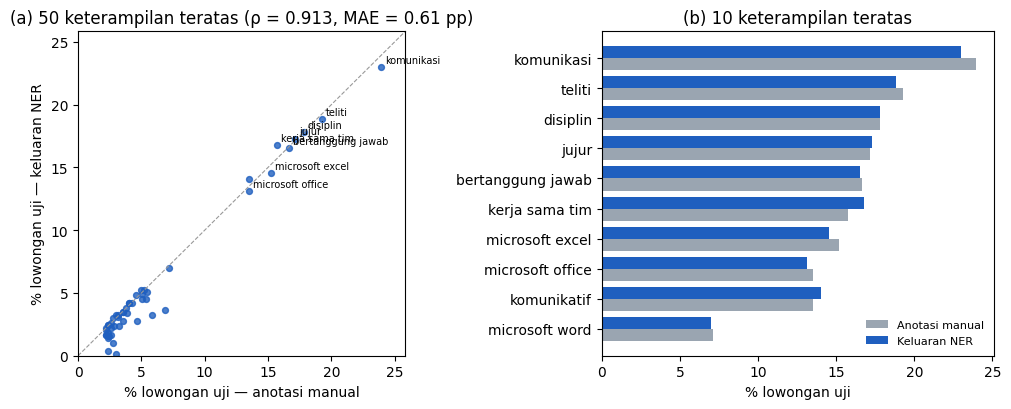

Grafik: outputs/figures/V1_validasi_indikator.png


In [37]:
# ===========================================================================
# (v21) VALIDASI INDIKATOR DASHBOARD: NER vs ANOTASI MANUAL (DATA UJI)
# ---------------------------------------------------------------------------
# Indikator dashboard yang utama adalah "persentase lowongan yang menyebut
# keterampilan s". Pada dokumen uji, indikator ini dihitung dua kali: dari span
# gold dan dari span model. Kedekatan keduanya menunjukkan apakah dashboard yang
# dibangun dari keluaran model dapat dipercaya.
# ===========================================================================
from scipy.stats import spearmanr, pearsonr

SKILL_LABS = {"SKILL", "SOFT_SKILL", "TOOL", "PROGRAMMING_LANGUAGE"}

def _skill_docs(docs, ids):
    c = Counter()
    for d in docs:
        if d["id"] not in ids: continue
        c.update({normalize_skill(s["text"]) for s in d["spans"] if s["label"] in SKILL_LABS})
    return c

def _esc_share(docs, ids):
    c = Counter()
    for d in docs:
        if d["id"] not in ids: continue
        for s in d["spans"]:
            if s["label"] in SKILL_LABS:
                sub, *_ = escudero_tagger.classify(s["text"])
                # keterampilan yang tidak cocok dengan kamus mana pun -> sub = None
                c[ESCUDERO_SUB_TO_BROAD.get(sub, "Tidak terklasifikasi") if sub else "Tidak terklasifikasi"] += 1
    tot = sum(c.values()) or 1
    return {k: v / tot for k, v in c.items()}

def _label_docs(docs, ids, lab):
    return sum(1 for d in docs if d["id"] in ids and any(s["label"] == lab for s in d["spans"]))

n_uji = len(test_ids)
G, P = _skill_docs(DOCS, test_ids), _skill_docs(DOCS_PRED, test_ids)
top_g = [s for s, _ in G.most_common(50)]
gp = np.array([G[s] / n_uji * 100 for s in top_g]); pp = np.array([P[s] / n_uji * 100 for s in top_g])
rho, _ = spearmanr(gp, pp); r, _ = pearsonr(gp, pp)
mae = float(np.mean(np.abs(gp - pp)))
top20_g = set(top_g[:20]); top20_p = {s for s, _ in P.most_common(20)}
eg, ep = _esc_share(DOCS, test_ids), _esc_share(DOCS_PRED, test_ids)
cak = {lab: (_label_docs(DOCS, test_ids, lab) / n_uji, _label_docs(DOCS_PRED, test_ids, lab) / n_uji)
       for lab in ["EDUCATION_LEVEL", "DEGREE_FIELD", "EXPERIENCE_YEARS", "SALARY"]}

VAL = {
    "n_dokumen_uji": n_uji,
    "spearman_top50": round(float(rho), 4), "pearson_top50": round(float(r), 4),
    "mae_persen_top50": round(mae, 3), "maks_selisih_top50": round(float(np.max(np.abs(gp - pp))), 3),
    "irisan_top20": len(top20_g & top20_p),
    "escudero_gold": {k: round(v, 4) for k, v in eg.items()},
    "escudero_model": {k: round(v, 4) for k, v in ep.items()},
    "cakupan_dokumen_gold_vs_model": {k: [round(a, 4), round(b, 4)] for k, (a, b) in cak.items()},
    "top10": [{"skill": s, "gold_pct": round(G[s] / n_uji * 100, 2), "model_pct": round(P[s] / n_uji * 100, 2)} for s in top_g[:10]],
}
json.dump(VAL, open(f"{CONFIG.OUTPUT_DIR}/validasi_indikator.json", "w"), ensure_ascii=False, indent=2)
print(json.dumps({k: v for k, v in VAL.items() if k != "top10"}, indent=2, ensure_ascii=False))
display(pd.DataFrame(VAL["top10"]))

# --- V1: persentase lowongan per keterampilan, gold vs model (50 teratas) ---
FIG_DIR = f"{CONFIG.OUTPUT_DIR}/figures"; os.makedirs(FIG_DIR, exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
lim = max(gp.max(), pp.max()) * 1.08
ax[0].plot([0, lim], [0, lim], ls="--", color="#999", lw=.8)
ax[0].scatter(gp, pp, s=18, color="#1f5fbf", alpha=.8)
for s, x, y in list(zip(top_g, gp, pp))[:8]: ax[0].annotate(s, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[0].set_xlim(0, lim); ax[0].set_ylim(0, lim)
ax[0].set_xlabel("% lowongan uji — anotasi manual"); ax[0].set_ylabel("% lowongan uji — keluaran NER")
ax[0].set_title(f"(a) 50 keterampilan teratas (ρ = {rho:.3f}, MAE = {mae:.2f} pp)")
t10 = pd.DataFrame(VAL["top10"]).iloc[::-1]; yy = np.arange(len(t10))
ax[1].barh(yy - .2, t10["gold_pct"], .4, color="#9aa5b1", label="Anotasi manual")
ax[1].barh(yy + .2, t10["model_pct"], .4, color="#1f5fbf", label="Keluaran NER")
ax[1].set_yticks(yy, t10["skill"]); ax[1].set_xlabel("% lowongan uji"); ax[1].legend(frameon=False, fontsize=8)
ax[1].set_title("(b) 10 keterampilan teratas")
plt.tight_layout(); fig.savefig(f"{FIG_DIR}/V1_validasi_indikator.png", dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)
print("Grafik:", f"{FIG_DIR}/V1_validasi_indikator.png")


## 9 · Penyimpanan ke Basis Data SQLite (III.11)
Skema relasional: `jobs`, `companies`, `locations`, `skills`, dan tabel relasi `job_skills`
beserta atribut Layer 2. Sumber data = **keluaran model NER** (Bagian 8f) + hasil pengayaan; set `SUMBER_DASHBOARD = "gold"` untuk memakai anotasi manual.

In [ ]:
def build_database(docs, db_path=CONFIG.DB_PATH):
    # --- Guard: pastikan semua dokumen sudah melalui enrich_document() ---
    # Ini mengatasi kasus DOCS dibangun ulang (mis. re-run sel loader data)
    # setelah sel enrichment sempat dijalankan, sehingga field
    # "enriched_skills" hilang lagi dari dict dokumen.
    n_diperbaiki = 0
    for d in docs:
        if "enriched_skills" not in d:
            d["enriched_skills"] = enrich_document(d)
            n_diperbaiki += 1
    if n_diperbaiki:
        print(f"[guard] {n_diperbaiki} dokumen belum ter-enrich -> dijalankan ulang otomatis.")

    # --- Guard: pastikan setiap skill sudah punya klasifikasi Escudero (5b) ---
    n_esc_diperbaiki = 0
    for d in docs:
        for s in d["enriched_skills"]:
            if "escudero_subcategory" not in s:
                sub, method, score = escudero_tagger.classify(s["text"])
                s["escudero_subcategory"] = sub
                s["escudero_broad_category"] = ESCUDERO_SUB_TO_BROAD[sub]
                s["escudero_method"] = method
                s["escudero_confidence"] = round(float(score), 3)
                n_esc_diperbaiki += 1
    if n_esc_diperbaiki:
        print(f"[guard] {n_esc_diperbaiki} skill belum diklasifikasi Escudero -> dijalankan ulang otomatis.")

    # --- Guard: pastikan setiap dokumen sudah punya klasifikasi KBJI (8d) ---
    n_kbji_diperbaiki = 0
    for d in docs:
        if "kbji_kode" not in d:
            canon = normalize_title(d["title"]) if d["title"].strip() else None
            if canon:
                g, method, conf, _ = kbji_tagger.classify(canon)
                d["kbji_kode"], d["kbji_nama"], d["kbji_confidence"] = g, GOLONGAN_POKOK_NAMA[g], round(float(conf), 3)
            else:
                d["kbji_kode"], d["kbji_nama"], d["kbji_confidence"] = None, None, None
            n_kbji_diperbaiki += 1
    if n_kbji_diperbaiki:
        print(f"[guard] {n_kbji_diperbaiki} dokumen belum diklasifikasi KBJI -> dijalankan ulang otomatis.")

    if os.path.exists(db_path): os.remove(db_path)
    con = sqlite3.connect(db_path); cur = con.cursor()
    cur.executescript("""
    CREATE TABLE companies(id INTEGER PRIMARY KEY, name TEXT UNIQUE);
    CREATE TABLE locations(id INTEGER PRIMARY KEY, name TEXT UNIQUE);
    -- (v11) title menyimpan versi KANONIK; title_raw menyimpan judul ASLI
    -- sebelum dinormalisasi, untuk transparansi/audit.
    -- (v12) + klasifikasi Golongan Pokok KBJI 2014 (lihat Bagian 8d)
    CREATE TABLE jobs(id INTEGER PRIMARY KEY, doc_id TEXT, title TEXT, title_raw TEXT,
                      url TEXT, batch TEXT, company_id INT, location_id INT,
                      industry TEXT, posted_date TEXT,
                      kbji_golongan_pokok_kode INTEGER, kbji_golongan_pokok_nama TEXT,
                      kbji_confidence REAL);
    -- (v11) provenance varian judul mentah -> kanonik (pola sama seperti skill_aliases)
    CREATE TABLE job_title_aliases(title_canonical TEXT, raw_text TEXT, n INT);
    -- (v12) + klasifikasi taksonomi Escudero et al. 2025 (lihat Bagian 5b)
    CREATE TABLE skills(id INTEGER PRIMARY KEY, name TEXT, label TEXT,
                        skill_type TEXT, skill_domain TEXT, skill_function TEXT,
                        transferability TEXT,
                        escudero_broad_category TEXT, escudero_subcategory TEXT,
                        UNIQUE(name,label));
    CREATE TABLE job_skills(job_id INT, skill_id INT, importance TEXT, proficiency TEXT);
    CREATE TABLE entities(job_id INT, label TEXT, text TEXT, start INT, end INT);
    """)
    def get_or_create(table, name):
        if not name: return None
        cur.execute(f"INSERT OR IGNORE INTO {table}(name) VALUES(?)", (name,))
        cur.execute(f"SELECT id FROM {table} WHERE name=?", (name,))
        return cur.fetchone()[0]

    # (v11) tulis provenance job_title_aliases sekali di awal (bukan per-dokumen)
    for row in _title_alias_rows:
        cur.execute("INSERT INTO job_title_aliases(title_canonical,raw_text,n) VALUES(?,?,?)",
                    (row["judul_kanonik"], row["judul_mentah"], row["n"]))

    for d in docs:
        meta = d["meta"]
        cid = get_or_create("companies", meta.get("company"))
        lid = get_or_create("locations", meta.get("location"))
        title_canonical = normalize_title(d["title"])   # (v11)
        cur.execute("""INSERT INTO jobs(doc_id,title,title_raw,url,batch,company_id,
                       location_id,industry,posted_date,
                       kbji_golongan_pokok_kode,kbji_golongan_pokok_nama,kbji_confidence)
                       VALUES(?,?,?,?,?,?,?,?,?,?,?,?)""",
                    (str(d["id"]), title_canonical, d["title"], d["url"], d["batch"],
                     cid, lid, meta.get("industry",""), meta.get("posted_date",""),
                     d.get("kbji_kode"), d.get("kbji_nama"), d.get("kbji_confidence")))
        job_id = cur.lastrowid
        # semua entitas
        for sp in d["spans"]:
            cur.execute("INSERT INTO entities(job_id,label,text,start,end) VALUES(?,?,?,?,?)",
                        (job_id, sp["label"], sp["text"], sp["start"], sp["end"]))
        # keterampilan + atribut
        for s in d["enriched_skills"]:
            cur.execute("""INSERT OR IGNORE INTO skills(name,label,skill_type,skill_domain,
                           skill_function,transferability,escudero_broad_category,escudero_subcategory)
                           VALUES(?,?,?,?,?,?,?,?)""",
                        (normalize_skill(s["text"]), s["label"], s["skill_type"], s["skill_domain"],
                         s["skill_function"], s["transferability"],
                         s["escudero_broad_category"], s["escudero_subcategory"]))
            cur.execute("SELECT id FROM skills WHERE name=? AND label=?", (normalize_skill(s["text"]), s["label"]))
            sid = cur.fetchone()[0]
            cur.execute("INSERT INTO job_skills(job_id,skill_id,importance,proficiency) VALUES(?,?,?,?)",
                        (job_id, sid, s["importance"], s["proficiency"]))
    con.commit()
    # ringkasan
    for tbl in ["jobs","companies","locations","skills","job_skills","entities","job_title_aliases"]:
        n = cur.execute(f"SELECT COUNT(*) FROM {tbl}").fetchone()[0]
        print(f"  {tbl}: {n:,} baris")

    # --- (v11) verifikasi cepat: title unik harus turun dibanding title_raw unik ---
    n_raw = cur.execute("SELECT COUNT(DISTINCT title_raw) FROM jobs").fetchone()[0]
    n_canon = cur.execute("SELECT COUNT(DISTINCT title) FROM jobs").fetchone()[0]
    print(f"\nVerifikasi: title_raw unik={n_raw:,} -> title (kanonik) unik={n_canon:,}")
    assert n_canon <= n_raw, "Normalisasi title seharusnya TIDAK menambah jumlah judul unik!"

    contoh = cur.execute("""SELECT DISTINCT title FROM jobs
                            WHERE title IN ('Host Live Streaming','Accounting Staff')""").fetchall()
    print("Contoh judul kanonik yang seharusnya ada:", contoh)

    # --- (v12) ringkasan klasifikasi Escudero & KBJI ---
    print("\nDistribusi kategori luas Escudero (tabel skills):")
    for row in cur.execute("""SELECT escudero_broad_category, COUNT(*) n FROM skills
                              GROUP BY escudero_broad_category ORDER BY n DESC"""):
        print(f"  {row[0]}: {row[1]:,}")
    print("\nDistribusi Golongan Pokok KBJI (tabel jobs):")
    for row in cur.execute("""SELECT kbji_golongan_pokok_nama, COUNT(*) n FROM jobs
                              GROUP BY kbji_golongan_pokok_nama ORDER BY n DESC"""):
        print(f"  {row[0]}: {row[1]:,}")

    con.close()
    print(f"\nBasis data tersimpan: {db_path}")

# (v21) Sumber data dashboard: keluaran model NER (Bagian 8f) atau anotasi manual
_sumber = globals().get("SUMBER_DASHBOARD", "gold")
DOCS_DASHBOARD = DOCS_PRED if (_sumber == "prediksi" and "DOCS_PRED" in globals()) else DOCS
print(f"Sumber data dashboard: {'keluaran model NER' if DOCS_DASHBOARD is not DOCS else 'anotasi manual (gold)'}"
      f" — {sum(len(d['spans']) for d in DOCS_DASHBOARD):,} span")
build_database(DOCS_DASHBOARD)


Sumber data dashboard: keluaran model NER — 90,704 span


In [ ]:
# ===========================================================================
# ACCURACY PER ENTITAS (Tabel 14) + ACCURACY BASELINE (Tabel 13)
# Dijalankan SETELAH cell evaluasi utama (y_true, y_pred, ys_t, ys_p, bt, bp
# harus sudah ada di memori dari run yang sama — tidak perlu training ulang)
# ===========================================================================
from seqeval.metrics import accuracy_score as seq_acc

print("=== Accuracy per entitas — IndoBERT (Tabel 14) ===")
acc_per_entity = {}
for lab in CONFIG.ENTITY_LABELS:
    yt = [[t if t.endswith(lab) else "O" for t in s] for s in y_true]
    yp = [[t if t.endswith(lab) else "O" for t in s] for s in y_pred]
    a = seq_acc(yt, yp)
    acc_per_entity[lab] = a
    print(f"  {lab:24s} {a:.4f}")

acc_all   = seq_acc(y_true, y_pred)          # accuracy Micro average (semua entitas)
acc_skill = seq_acc(ys_t, ys_p)              # accuracy khusus 4 label skill
print(f"\n  {'Micro average':24s} {acc_all:.4f}")
print(f"  {'(skill-only, info)':24s} {acc_skill:.4f}")

# --- Simpan sebagai CSV siap tempel ke Tabel 14 ---
rows14 = [{"entity_type": lab, "accuracy": acc_per_entity[lab]} for lab in CONFIG.ENTITY_LABELS]
rows14.append({"entity_type": "Micro average", "accuracy": acc_all})
df_acc14 = pd.DataFrame(rows14)
df_acc14.to_csv(f"{CONFIG.OUTPUT_DIR}/table14_accuracy.csv", index=False)
print("\nDisimpan -> outputs/table14_accuracy.csv")
display(df_acc14.round(4))

# ===========================================================================
# ACCURACY DICTIONARY BASELINE (Tabel 13) — pakai bt, bp dari cell baseline (32)
# ===========================================================================
acc_baseline = seq_acc(bt, bp)
print(f"\n=== Accuracy Dictionary baseline (Tabel 13): {acc_baseline:.4f} ===")

df_acc13 = pd.DataFrame([
    {"model": "Dictionary baseline", "accuracy": acc_baseline},
    {"model": "IndoBERT",            "accuracy": acc_all},
])
df_acc13.to_csv(f"{CONFIG.OUTPUT_DIR}/table13_accuracy.csv", index=False)
print("Disimpan -> outputs/table13_accuracy.csv")
display(df_acc13.round(4))

In [ ]:
# ===========================================================================
# TABEL 17 · Contoh Representatif Kesalahan NER
# ---------------------------------------------------------------------------
# Jalankan sel ini SETELAH sel 38 (prediksi test set) dan sel 39 (analisis
# kesalahan), dalam sesi yang sama, karena sel ini memakai variabel
# `test_data`, `pred_out`, `y_true`, dan `y_pred` yang dibuat di sana.
#
# Sel ini MEMANEN contoh kesalahan yang benar-benar dibuat model pada test set,
# lalu mencetaknya sebagai tabel LaTeX dan menyimpannya ke CSV. Tidak ada satu
# pun contoh yang dikarang.
#
# Kolom "Interpretation" diisi kalimat dugaan otomatis berdasarkan jenis
# kesalahan dan pasangan labelnya. WAJIB DIBACA DAN DIEDIT SENDIRI sebelum
# masuk naskah -- interpretasi adalah penalaran peneliti, bukan keluaran kode.
# ===========================================================================
import re
import random
from collections import Counter, defaultdict

import pandas as pd

random.seed(42)

JUMLAH_PER_JENIS = 3          # contoh yang dipanen per jenis kesalahan
MAKS_KATA_SPAN = 6            # span lebih panjang dari ini dilewati agar tabel muat
KATA_KONTEKS = 4              # kata di kiri/kanan span sebagai konteks


# --- 1. Susun ulang token test agar sejajar dengan y_true / y_pred ----------
# Sel 38 melewati chunk yang seluruh labelnya -100 (`continue`), jadi indeks
# test_data dan y_true bisa bergeser. Perulangan di bawah meniru persis logika
# pelewatan itu, sekaligus memotong token sesuai panjang yang benar-benar
# dievaluasi (akibat truncation pada MAX_LEN).
test_tokens = []
for chunk, la in zip(test_data, pred_out.label_ids):
    keep = la != -100
    n = int(keep.sum())
    if n == 0:
        continue
    test_tokens.append(chunk["tokens"][:n])

assert len(test_tokens) == len(y_true), (
    f"Token ({len(test_tokens)}) tidak sejajar dengan y_true ({len(y_true)}). "
    "Pastikan sel 38 dijalankan tepat sebelum sel ini, tanpa menjalankan ulang "
    "trainer.predict di antaranya."
)


def span_teks(toks, s, e):
    return " ".join(toks[s:e + 1])


def konteks(toks, s, e, n=KATA_KONTEKS):
    kiri = " ".join(toks[max(0, s - n):s])
    kanan = " ".join(toks[e + 1:e + 1 + n])
    inti = span_teks(toks, s, e)
    hasil = f"...{kiri} [{inti}] {kanan}...".strip()
    return re.sub(r"\s+", " ", hasil)


# --- 2. Panen kesalahan per jenis -------------------------------------------
kandidat = defaultdict(list)

for idx, (gt, pt) in enumerate(zip(y_true, y_pred)):
    toks = test_tokens[idx]
    ge, pe = extract_entities(gt), extract_entities(pt)
    gset = {(s, e): lab for lab, s, e in ge}
    pset = {(s, e): lab for lab, s, e in pe}
    gspans, pspans = set(gset), set(pset)

    # (a) Label salah -- batas span tepat, jenis entitas keliru
    for sp in gspans & pspans:
        if gset[sp] != pset[sp]:
            s, e = sp
            if e - s + 1 <= MAKS_KATA_SPAN:
                kandidat["wrong_label"].append({
                    "konteks": konteks(toks, s, e),
                    "span": span_teks(toks, s, e),
                    "gold": gset[sp], "pred": pset[sp],
                    "jenis": "Label error",
                    "pasangan": f"{gset[sp]} -> {pset[sp]}",
                })

    # (b) Batas span salah / entitas terlewat
    for sp in gspans - pspans:
        s, e = sp
        tumpang = [(pl, ps, pe_) for pl, ps, pe_ in pe if not (pe_ < s or ps > e)]
        if e - s + 1 > MAKS_KATA_SPAN:
            continue
        if tumpang:
            pl, ps, pe_ = tumpang[0]
            kandidat["boundary_error"].append({
                "konteks": konteks(toks, min(s, ps), max(e, pe_)),
                "span": span_teks(toks, s, e),
                "gold": f"{gset[sp]} [{span_teks(toks, s, e)}]",
                "pred": f"{pl} [{span_teks(toks, ps, pe_)}]",
                "jenis": "Boundary error",
                "pasangan": f"{gset[sp]} -> {pl}",
            })
        else:
            kandidat["missed_entity"].append({
                "konteks": konteks(toks, s, e),
                "span": span_teks(toks, s, e),
                "gold": gset[sp], "pred": "(tidak terdeteksi)",
                "jenis": "Missed entity",
                "pasangan": f"{gset[sp]} -> -",
            })

    # (c) Entitas palsu -- model menandai sesuatu yang tidak ada di gold
    for sp in pspans - gspans:
        s, e = sp
        if any(not (ge_ < s or gs > e) for _, gs, ge_ in ge):
            continue
        if e - s + 1 <= MAKS_KATA_SPAN:
            kandidat["spurious_entity"].append({
                "konteks": konteks(toks, s, e),
                "span": span_teks(toks, s, e),
                "gold": "(bukan entitas)", "pred": pset[sp],
                "jenis": "False positive",
                "pasangan": f"- -> {pset[sp]}",
            })

print("Kandidat contoh yang terkumpul:")
for k, v in kandidat.items():
    print(f"  {k}: {len(v):,}")


# --- 3. Pilih yang paling representatif -------------------------------------
# "Representatif" di sini = berasal dari pasangan label yang PALING SERING
# muncul pada jenis kesalahan tersebut, bukan diambil acak. Dengan begitu
# contoh di tabel benar-benar mewakili pola kesalahan dominan.
terpilih = []
for jenis in ["boundary_error", "wrong_label", "missed_entity", "spurious_entity"]:
    baris = kandidat.get(jenis, [])
    if not baris:
        continue
    sering = [p for p, _ in Counter(r["pasangan"] for r in baris).most_common()]
    diambil, dipakai = [], set()
    for pasangan in sering:                       # satu contoh per pasangan teratas
        for r in baris:
            if r["pasangan"] == pasangan and r["span"].lower() not in dipakai:
                diambil.append(r)
                dipakai.add(r["span"].lower())
                break
        if len(diambil) >= JUMLAH_PER_JENIS:
            break
    terpilih.extend(diambil)

df17 = pd.DataFrame(terpilih)


# --- 4. Kalimat interpretasi awal (WAJIB DIEDIT SENDIRI) --------------------
def tafsir(r):
    g, p = r["gold"].split(" [")[0], r["pred"].split(" [")[0]
    if r["jenis"] == "Boundary error":
        return (f"Model mengenali entitas {g} tetapi menetapkan batas span yang "
                "berbeda dari anotasi acuan.")
    if r["jenis"] == "Label error":
        return (f"Batas span tepat, namun {g} tertukar menjadi {p}; kedua jenis "
                "entitas ini berbagi konteks leksikal yang mirip.")
    if r["jenis"] == "Missed entity":
        return (f"Entitas {g} tidak terdeteksi sama sekali, kemungkinan karena "
                "frasa ini jarang muncul pada data latih.")
    return (f"Model menandai frasa yang tidak dianotasi sebagai entitas {p}; "
            "pola permukaannya menyerupai entitas sebenarnya.")


df17["interpretasi"] = df17.apply(tafsir, axis=1)

kolom = ["konteks", "gold", "pred", "jenis", "interpretasi"]
df17 = df17[kolom]
df17.columns = ["Text span/context", "Gold", "Prediction", "Error type",
                "Interpretation"]

df17.to_csv("outputs/tabel17_contoh_kesalahan.csv", index=False)
print(f"\nTersimpan: outputs/tabel17_contoh_kesalahan.csv ({len(df17)} baris)")
display(df17)


# --- 5. Cetak LaTeX siap tempel ---------------------------------------------
def esc(t):
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"),
                 ("$", r"\$"), ("#", r"\#"), ("_", r"\_"), ("{", r"\{"),
                 ("}", r"\}"), ("~", r"\textasciitilde{}"),
                 ("^", r"\textasciicircum{}")]:
        t = str(t).replace(a, b)
    return t


baris_tex = []
for r in df17.itertuples(index=False):
    baris_tex.append(
        "\\texttt{" + esc(r[0]) + "} & " + esc(r[1]) + " & " + esc(r[2])
        + " & " + esc(r[3]) + " & " + esc(r[4]) + r" \\")

tex = r"""\begin{table}[htbp]
\centering
\caption{Representative NER errors in Indonesian job advertisements.}
\label{tab:ner-errors}
\footnotesize
\renewcommand{\arraystretch}{1.25}
\begin{tabular}{p{4.2cm} p{2.2cm} p{2.2cm} p{1.8cm} p{4.0cm}}
\hline
\textbf{Text span/context} & \textbf{Gold} & \textbf{Prediction} &
\textbf{Error type} & \textbf{Interpretation} \\
\hline
""" + "\n".join(baris_tex) + r"""
\hline
\end{tabular}
\end{table}"""

print("\n" + "=" * 78)
print("LaTeX siap tempel:")
print("=" * 78)
print(tex)

with open("outputs/tabel17.tex", "w", encoding="utf-8") as f:
    f.write(tex)
print("\nTersimpan juga ke: outputs/tabel17.tex")
print("\nPERIKSA kolom Interpretation sebelum dipakai -- kalimatnya dibangkitkan "
      "otomatis dan perlu disesuaikan dengan penalaran Anda sendiri.")

## 10 · Analisis & Visualisasi (III.12)
Contoh analisis kebutuhan keterampilan: top skills, distribusi per label, co-occurrence, dan
skill per jabatan. Output ini menjadi basis untuk dashboard Streamlit.

In [ ]:
import matplotlib.pyplot as plt

con = sqlite3.connect(CONFIG.DB_PATH)

# Top 20 keterampilan
top_skills = pd.read_sql("""
    SELECT s.name, s.label, COUNT(*) as freq FROM job_skills js
    JOIN skills s ON s.id=js.skill_id
    GROUP BY s.name,s.label ORDER BY freq DESC LIMIT 20""", con)
print("Top 20 keterampilan paling diminta:")
display(top_skills)

fig, ax = plt.subplots(figsize=(9,6))
ax.barh(top_skills["name"][::-1], top_skills["freq"][::-1], color="#1565c0")
ax.set_title("Top 20 Keterampilan Paling Diminta"); ax.set_xlabel("Frekuensi")
plt.tight_layout(); plt.show()

In [ ]:
# Distribusi entitas per label
ent_dist = pd.read_sql("SELECT label, COUNT(*) n FROM entities GROUP BY label ORDER BY n DESC", con)
fig, ax = plt.subplots(figsize=(9,5))
ax.bar(ent_dist["label"], ent_dist["n"], color="#6a1b9a")
ax.set_title("Distribusi Entitas per Label"); plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

# Skill domain distribution (Layer 2)
dom = pd.read_sql("SELECT skill_domain, COUNT(*) n FROM skills GROUP BY skill_domain ORDER BY n DESC", con)
print("Distribusi skill_domain (Layer 2):"); display(dom)

In [ ]:
# Co-occurrence keterampilan (pasangan skill yang sering muncul bersama dlm 1 lowongan)
from itertools import combinations
pair = Counter()
rows = pd.read_sql("""SELECT js.job_id, s.name FROM job_skills js
                      JOIN skills s ON s.id=js.skill_id""", con)
for jid, grp in rows.groupby("job_id"):
    uniq = sorted(set(grp["name"]))
    for a,b in combinations(uniq, 2):
        pair[(a,b)] += 1
top_pairs = pd.DataFrame([(a,b,c) for (a,b),c in pair.most_common(20)],
                         columns=["skill_1","skill_2","co_occurrence"])
print("Top 20 pasangan keterampilan (co-occurrence):")
display(top_pairs)
con.close()

### 10b · Klasifikasi Escudero & KBJI (v12)


In [ ]:
# --- (v12) Visualisasi klasifikasi Escudero & KBJI ---
con = sqlite3.connect(CONFIG.DB_PATH)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

esc_broad = pd.read_sql("""SELECT escudero_broad_category, COUNT(*) n FROM skills
                           GROUP BY escudero_broad_category ORDER BY n DESC""", con)
axes[0].bar(esc_broad["escudero_broad_category"], esc_broad["n"], color=["#6366f1","#f59e0b","#10b981"])
axes[0].set_title("Distribusi Kategori Luas Escudero (skills)")
axes[0].tick_params(axis="x", rotation=15)

kbji_dist = pd.read_sql("""SELECT kbji_golongan_pokok_nama, COUNT(*) n FROM jobs
                           WHERE kbji_golongan_pokok_nama IS NOT NULL
                           GROUP BY kbji_golongan_pokok_nama ORDER BY n DESC""", con)
axes[1].barh(kbji_dist["kbji_golongan_pokok_nama"][::-1], kbji_dist["n"][::-1], color="#8b5cf6")
axes[1].set_title("Distribusi Golongan Pokok KBJI 2014 (jobs)")

plt.tight_layout(); plt.show()

print("\nSubkategori Escudero (14 kategori, top 14):")
esc_sub = pd.read_sql("""SELECT escudero_subcategory, COUNT(*) n FROM skills
                         GROUP BY escudero_subcategory ORDER BY n DESC""", con)
display(esc_sub)


---
## 10c · Grafik untuk Artikel (v20)

Semua grafik yang dibutuhkan naskah artikel/skripsi dibuat di sini dan disimpan ke
`outputs/figures/` (PNG, 300 dpi). Setiap grafik dibungkus `aman()`: kalau variabel yang
diperlukan belum ada (misalnya sel training belum dijalankan), grafik itu dilewati dengan
pesan, bukan menghentikan notebook.

| Kelompok | Grafik | Butuh sel |
|---|---|---|
| A · Data | distribusi entitas, cakupan dokumen, panjang span, distribusi split | Sel data/split |
| B · Pelatihan | loss train/val, P/R/F1 per epoch, laju pembelajaran, grad norm, selisih overfitting | Training (`trainer`) |
| C · Evaluasi | P/R/F1 per entitas, strict vs partial, baseline vs IndoBERT, argmax vs Viterbi, F1 vs support | Evaluasi + baseline |
| D · Kesalahan | jenis kesalahan, confusion matrix token (ternormalisasi), kebingungan label span | Analisis kesalahan |
| E · Pasar kerja | top skill, Escudero 3 & 14 subkategori, KBJI, co-occurrence | SQLite |
| F · Pembanding | benchmark multi-model, sebaran multi-seed | `hasil_benchmark.json`, `hasil_multiseed*.csv` (opsional) |


In [ ]:
# ===========================================================================
# (v20) Utilitas grafik artikel
# ===========================================================================
import os, glob, json, traceback
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

FIG_DIR = f"{CONFIG.OUTPUT_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .25, "grid.linestyle": "-",
})
WARNA = {"utama": "#1f5fbf", "kedua": "#e8833a", "ketiga": "#2a9d8f",
         "abu": "#9aa5b1", "merah": "#c0392b"}
ENT_ORDER = ["JOB_TITLE","COMPANY","LOCATION","EDUCATION_LEVEL","DEGREE_FIELD",
             "EXPERIENCE_YEARS","SKILL","SOFT_SKILL","TOOL","PROGRAMMING_LANGUAGE",
             "INDUSTRY","SALARY","EMPLOYMENT_TYPE","RESPONSIBILITY"]
DAFTAR_GRAFIK = []

def simpan(fig, nama, judul=None):
    path = f"{FIG_DIR}/{nama}.png"
    fig.savefig(path); plt.show(); plt.close(fig)
    DAFTAR_GRAFIK.append((nama, judul or nama))
    print(f"  ✓ {path}")

def aman(fn):
    """Jalankan fungsi grafik; kalau gagal, cetak alasannya lalu lanjut."""
    try:
        fn()
    except NameError as e:
        print(f"  – {fn.__name__} dilewati: variabel belum ada ({e}). Jalankan sel terkait dulu.")
    except Exception as e:
        print(f"  ✗ {fn.__name__} gagal: {type(e).__name__}: {e}")
        traceback.print_exc(limit=1)
    return fn

def spans_iob(tags):
    """(label, awal, akhir) dari satu urutan IOB2."""
    out, cur = [], None
    for i, t in enumerate(tags):
        if t.startswith("B-"):
            if cur: out.append(tuple(cur))
            cur = [t[2:], i, i]
        elif t.startswith("I-") and cur and cur[0] == t[2:]:
            cur[2] = i
        else:
            if cur: out.append(tuple(cur)); cur = None
    if cur: out.append(tuple(cur))
    return out
print("Folder grafik:", FIG_DIR)


### A · Karakteristik data

In [ ]:
@aman
def grafik_distribusi_entitas():
    n_span = Counter(s["label"] for d in DOCS for s in d["spans"])
    n_dok  = Counter(l for d in DOCS for l in {s["label"] for s in d["spans"]})
    labs = [l for l in ENT_ORDER if l in n_span] + [l for l in n_span if l not in ENT_ORDER]
    labs = sorted(labs, key=lambda l: n_span[l])
    fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    ax[0].barh(labs, [n_span[l] for l in labs], color=WARNA["utama"])
    for i, l in enumerate(labs): ax[0].text(n_span[l], i, f" {n_span[l]:,}", va="center", fontsize=8)
    ax[0].set_title("(a) Jumlah span per entitas"); ax[0].set_xlabel("Jumlah span")
    pct = [100*n_dok[l]/len(DOCS) for l in labs]
    ax[1].barh(labs, pct, color=WARNA["ketiga"])
    for i, p in enumerate(pct): ax[1].text(p, i, f" {p:.1f}%", va="center", fontsize=8)
    ax[1].set_title("(b) Cakupan dokumen"); ax[1].set_xlabel("% dokumen yang memuat entitas")
    simpan(fig, "A1_distribusi_entitas", "Distribusi entitas dan cakupan dokumen")

@aman
def grafik_panjang_span():
    rows = [(s["label"], len(s["text"].split())) for d in DOCS for s in d["spans"]]
    df = pd.DataFrame(rows, columns=["label", "kata"])
    urut = df.groupby("label")["kata"].median().sort_values().index.tolist()
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.boxplot([df.loc[df.label == l, "kata"] for l in urut], tick_labels=urut,
               orientation="horizontal", showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#dbe7f8", color=WARNA["utama"]),
               medianprops=dict(color=WARNA["merah"]))
    ax.set_xlabel("Panjang span (kata), tanpa pencilan")
    ax.set_title("Distribusi panjang span per entitas")
    simpan(fig, "A2_panjang_span", "Panjang span per entitas")

@aman
def grafik_split():
    data = {"Train": train_ids, "Validasi": val_ids, "Uji": test_ids}
    dok = {k: len(v) for k, v in data.items()}
    ent = {k: Counter(s["label"] for d in DOCS if d["id"] in v for s in d["spans"]) for k, v in data.items()}
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 2.4]})
    ax[0].bar(dok.keys(), dok.values(), color=[WARNA["utama"], WARNA["kedua"], WARNA["ketiga"]])
    for i, v in enumerate(dok.values()): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
    ax[0].set_title("(a) Jumlah dokumen per split")
    labs = [l for l in ENT_ORDER if l in ent["Train"]]
    x = np.arange(len(labs)); w = .27
    for j, (k, c) in enumerate(ent.items()):
        tot = sum(c.values())
        ax[1].bar(x + (j-1)*w, [100*c[l]/tot for l in labs], w, label=k,
                  color=[WARNA["utama"], WARNA["kedua"], WARNA["ketiga"]][j])
    ax[1].set_xticks(x, labs, rotation=60, ha="right", fontsize=8)
    ax[1].set_ylabel("% span dalam split"); ax[1].legend(frameon=False)
    ax[1].set_title("(b) Proporsi entitas per split (stratifikasi)")
    simpan(fig, "A3_distribusi_split", "Pembagian data latih/validasi/uji")


### B · Dinamika pelatihan

In [ ]:
def _riwayat():
    h = pd.DataFrame(trainer.state.log_history)
    tr = h[h["loss"].notna()][["epoch", "step", "loss"] + [c for c in ("learning_rate", "grad_norm") if c in h]]
    ev = h[h["eval_loss"].notna()].copy() if "eval_loss" in h else pd.DataFrame()
    tr_ep = tr.groupby(tr["epoch"].apply(np.ceil))["loss"].mean()
    return h, tr, ev, tr_ep

@aman
def grafik_kurva_loss():
    h, tr, ev, tr_ep = _riwayat()
    best = trainer.state.best_metric
    ep_best = ev.loc[ev["eval_f1"].idxmax(), "epoch"] if "eval_f1" in ev else None
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.plot(tr_ep.index, tr_ep.values, "o-", ms=3, color=WARNA["utama"], label="Loss latih (rerata per epoch)")
    ax.plot(ev["epoch"], ev["eval_loss"], "s-", ms=3, color=WARNA["kedua"], label="Loss validasi")
    if ep_best is not None:
        ax.axvline(ep_best, ls="--", color=WARNA["abu"]); ax.text(ep_best, ax.get_ylim()[1]*.95, f" epoch terbaik={ep_best:.0f}", fontsize=8)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy"); ax.legend(frameon=False)
    ax.set_title("Kurva loss pelatihan dan validasi")
    simpan(fig, "B1_kurva_loss", "Loss latih vs validasi per epoch")

@aman
def grafik_metrik_validasi():
    h, tr, ev, _ = _riwayat()
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    for k, c, m in [("eval_precision", WARNA["utama"], "o"), ("eval_recall", WARNA["kedua"], "s"), ("eval_f1", WARNA["ketiga"], "^")]:
        if k in ev: ax.plot(ev["epoch"], ev[k], marker=m, ms=3, color=c, label=k.replace("eval_", "").capitalize())
    i = ev["eval_f1"].idxmax()
    ax.annotate(f"F1 maks {ev.loc[i,'eval_f1']:.3f}", (ev.loc[i, "epoch"], ev.loc[i, "eval_f1"]),
                xytext=(10, -25), textcoords="offset points", arrowprops=dict(arrowstyle="->"), fontsize=8)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Skor (strict, validasi)"); ax.legend(frameon=False)
    ax.set_title("Presisi, recall, dan F1 validasi per epoch")
    simpan(fig, "B2_metrik_validasi", "P/R/F1 validasi per epoch")

@aman
def grafik_learning_rate():
    h, tr, ev, _ = _riwayat()
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    ax.plot(tr["step"], tr["learning_rate"], color=WARNA["utama"])
    ax.set_xlabel("Langkah optimisasi"); ax.set_ylabel("Laju pembelajaran")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.set_title("Jadwal laju pembelajaran (warm-up linear lalu menurun linear)")
    simpan(fig, "B3_learning_rate", "Jadwal laju pembelajaran")

@aman
def grafik_grad_norm():
    h, tr, ev, _ = _riwayat()
    if "grad_norm" not in tr: print("  – grad_norm tidak tercatat di log_history"); return
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    ax.plot(tr["step"], tr["grad_norm"], color=WARNA["abu"], lw=.8, label="per log")
    ax.plot(tr["step"], tr["grad_norm"].rolling(10, min_periods=1).mean(), color=WARNA["merah"], label="rerata bergerak (10)")
    ax.set_xlabel("Langkah optimisasi"); ax.set_ylabel("‖g‖₂"); ax.legend(frameon=False)
    ax.set_title("Norma gradien selama pelatihan")
    simpan(fig, "B4_grad_norm", "Norma gradien")

@aman
def grafik_celah_overfitting():
    h, tr, ev, tr_ep = _riwayat()
    e = ev.set_index(ev["epoch"].round())["eval_loss"]
    common = tr_ep.index.intersection(e.index)
    gap = e.loc[common] - tr_ep.loc[common]
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    ax.bar(common, gap, color=np.where(gap > 0, WARNA["kedua"], WARNA["ketiga"]))
    ax.axhline(0, color="k", lw=.6)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss validasi − loss latih")
    ax.set_title("Celah generalisasi per epoch (positif = mulai overfitting)")
    simpan(fig, "B5_celah_overfitting", "Celah loss validasi−latih")


### C · Evaluasi model pada data uji

In [ ]:
from seqeval.metrics import classification_report as _seq_cr

def _per_entitas(yt, yp):
    rep = _seq_cr(yt, yp, output_dict=True, zero_division=0)
    return pd.DataFrame({k: v for k, v in rep.items() if "avg" not in k}).T

@aman
def grafik_prf_per_entitas():
    df = _per_entitas(y_true, y_pred).sort_values("f1-score")
    y = np.arange(len(df)); w = .27
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.barh(y - w, df["precision"], w, label="Presisi", color=WARNA["utama"])
    ax.barh(y,     df["recall"],    w, label="Recall",  color=WARNA["kedua"])
    ax.barh(y + w, df["f1-score"],  w, label="F1",      color=WARNA["ketiga"])
    ax.set_yticks(y, df.index); ax.set_xlim(0, 1); ax.legend(frameon=False, loc="lower right")
    ax.axvline(seq_f1(y_true, y_pred), ls="--", color=WARNA["abu"]);
    ax.set_title("Presisi, recall, F1 per entitas (strict, data uji)")
    simpan(fig, "C1_prf_per_entitas", "P/R/F1 per entitas")

@aman
def grafik_strict_vs_partial():
    s = _per_entitas(y_true, y_pred)["f1-score"]
    p = pm_df.set_index("label")["f1"].drop("micro avg", errors="ignore")
    labs = s.sort_values().index.tolist()
    fig, ax = plt.subplots(figsize=(8, 6.5))
    for i, l in enumerate(labs):
        ax.plot([s[l], p.get(l, np.nan)], [i, i], color=WARNA["abu"], lw=2, zorder=1)
    ax.scatter(s[labs], range(len(labs)), color=WARNA["utama"], label="Strict", zorder=2)
    ax.scatter([p.get(l, np.nan) for l in labs], range(len(labs)), color=WARNA["kedua"], label="Partial", zorder=2)
    ax.set_yticks(range(len(labs)), labs); ax.set_xlabel("F1"); ax.legend(frameon=False)
    ax.set_title(f"Strict vs partial match (mikro: {seq_f1(y_true,y_pred):.3f} → {pm_f1:.3f})")
    simpan(fig, "C2_strict_vs_partial", "F1 strict vs partial per entitas")

@aman
def grafik_baseline_vs_indobert():
    b = _per_entitas(bt, bp)["f1-score"]; m = _per_entitas(y_true, y_pred)["f1-score"]
    labs = m.sort_values().index.tolist(); y = np.arange(len(labs)); w = .38
    fig, ax = plt.subplots(figsize=(8, 6.5))
    ax.barh(y - w/2, [b.get(l, 0) for l in labs], w, color=WARNA["abu"], label=f"Baseline kamus (F1={seq_f1(bt,bp):.3f})")
    ax.barh(y + w/2, m[labs], w, color=WARNA["utama"], label=f"IndoBERT (F1={seq_f1(y_true,y_pred):.3f})")
    ax.set_yticks(y, labs); ax.set_xlim(0, 1); ax.set_xlabel("F1 strict"); ax.legend(frameon=False, loc="lower right")
    ax.set_title("Baseline pencocokan kamus vs IndoBERT per entitas")
    simpan(fig, "C3_baseline_vs_indobert", "Baseline vs IndoBERT")

@aman
def grafik_argmax_vs_viterbi():
    a = _per_entitas(y_true, y_pred_argmax)["f1-score"]; v = _per_entitas(y_true, y_pred)["f1-score"]
    d = (v - a).sort_values()
    fig, ax = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 2]})
    tot = [seq_f1(y_true, y_pred_argmax), seq_f1(y_true, y_pred)]
    ax[0].bar(["Argmax", "Viterbi\nberkendala"], tot, color=[WARNA["abu"], WARNA["utama"]])
    for i, t in enumerate(tot): ax[0].text(i, t, f"{t:.3f}", ha="center", va="bottom")
    ax[0].set_ylim(min(tot) - .05, max(tot) + .03); ax[0].set_title("(a) F1 mikro")
    ax[1].barh(d.index, d.values, color=np.where(d > 0, WARNA["ketiga"], WARNA["merah"]))
    ax[1].axvline(0, color="k", lw=.6); ax[1].set_xlabel("ΔF1 (Viterbi − argmax)")
    ax[1].set_title("(b) Perubahan F1 per entitas")
    # jumlah transisi ilegal yang diperbaiki
    ileg = sum(1 for s in y_pred_argmax for a_, b_ in zip(["O"] + s[:-1], s)
               if b_.startswith("I-") and a_ not in (f"B-{b_[2:]}", f"I-{b_[2:]}"))
    fig.suptitle(f"Dekode argmax vs Viterbi — {ileg:,} transisi IOB2 ilegal pada argmax", fontsize=10)
    simpan(fig, "C4_argmax_vs_viterbi", "Argmax vs Viterbi")

@aman
def grafik_f1_vs_support():
    df = _per_entitas(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(7.5, 5))
    ax.scatter(df["support"], df["f1-score"], s=40, color=WARNA["utama"])
    for l, r in df.iterrows(): ax.annotate(l, (r["support"], r["f1-score"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("Support data uji (skala log)"); ax.set_ylabel("F1 strict")
    rho = pd.Series(df["support"]).rank().corr(pd.Series(df["f1-score"]).rank())
    ax.set_title(f"F1 vs jumlah contoh per entitas (Spearman ρ = {rho:.2f})")
    simpan(fig, "C5_f1_vs_support", "F1 vs support")

@aman
def grafik_ringkasan_metrik():
    from seqeval.metrics import precision_score as _p, recall_score as _r, accuracy_score as _a
    rows = {"Baseline": (_p(bt, bp), _r(bt, bp), seq_f1(bt, bp)),
            "IndoBERT\n(argmax)": (_p(y_true, y_pred_argmax), _r(y_true, y_pred_argmax), seq_f1(y_true, y_pred_argmax)),
            "IndoBERT\n(Viterbi)": (_p(y_true, y_pred), _r(y_true, y_pred), seq_f1(y_true, y_pred))}
    x = np.arange(3); w = .26
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for j, (k, c) in enumerate(zip(["Presisi", "Recall", "F1"], [WARNA["utama"], WARNA["kedua"], WARNA["ketiga"]])):
        vals = [v[j] for v in rows.values()]
        ax.bar(x + (j-1)*w, vals, w, label=k, color=c)
        for xi, v in zip(x + (j-1)*w, vals): ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x, rows.keys()); ax.set_ylim(0, 1); ax.legend(frameon=False, ncol=3)
    ax.set_title(f"Ringkasan metrik mikro data uji (akurasi token IndoBERT = {_a(y_true, y_pred):.3f})")
    simpan(fig, "C6_ringkasan_metrik", "Ringkasan metrik mikro")


### D · Analisis kesalahan

In [ ]:
@aman
def grafik_jenis_kesalahan():
    nama = {"correct": "Benar", "boundary_error": "Batas span", "wrong_label": "Label salah",
            "missed_entity": "Entitas terlewat", "spurious_entity": "Entitas palsu"}
    e = pd.Series({nama.get(k, k): v for k, v in err.items()}).sort_values()
    salah = e.drop("Benar", errors="ignore")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].barh(salah.index, salah.values, color=WARNA["kedua"])
    for i, v in enumerate(salah.values): ax[0].text(v, i, f" {v:,} ({100*v/salah.sum():.1f}%)", va="center", fontsize=8)
    ax[0].set_title("(a) Komposisi kesalahan"); ax[0].set_xlabel("Jumlah span")
    top = pd.Series({f"{g}→{p}": c for (g, p), c in confusion.most_common(12)}).sort_values()
    ax[1].barh(top.index, top.values, color=WARNA["utama"]); ax[1].set_xlabel("Jumlah span")
    ax[1].set_title("(b) Kebingungan label (acuan→prediksi, batas sama)")
    simpan(fig, "D1_jenis_kesalahan", "Jenis kesalahan dan kebingungan label")

@aman
def grafik_confusion_token():
    from sklearn.metrics import confusion_matrix
    # dipadatkan ke jenis entitas (B-/I- digabung) agar terbaca; O ikut sebagai kelas
    f = lambda t: t if t == "O" else t[2:]
    yt = [f(t) for s in y_true for t in s]; yp = [f(t) for s in y_pred for t in s]
    labs = [l for l in ENT_ORDER if l in set(yt)] + ["O"]
    cm = confusion_matrix(yt, yp, labels=labs).astype(float)
    cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(10, 8.5))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labs)), labs, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(labs)), labs, fontsize=8)
    for i in range(len(labs)):
        for j in range(len(labs)):
            if cmn[i, j] >= .01:
                ax.text(j, i, f"{cmn[i,j]:.2f}", ha="center", va="center", fontsize=6,
                        color="white" if cmn[i, j] > .5 else "black")
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Acuan"); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=.04, label="Proporsi baris (recall token)")
    ax.set_title("Confusion matrix tingkat token (ternormalisasi per baris)")
    simpan(fig, "D2_confusion_token", "Confusion matrix token")

@aman
def grafik_confusion_span():
    labs = [l for l in ENT_ORDER]
    M = pd.DataFrame(0, index=labs + ["(tanpa acuan)"], columns=labs + ["(tak terprediksi)"])
    for gt, pt in zip(y_true, y_pred):
        ge = {(s, e): l for l, s, e in spans_iob(gt)}; pe = {(s, e): l for l, s, e in spans_iob(pt)}
        for k, l in ge.items():
            if k in pe: M.at[l, pe[k]] += 1      # batas sama: label benar atau tertukar
            else:       M.at[l, "(tak terprediksi)"] += 1  # acuan tanpa prediksi berbatas sama
        for k, l in pe.items():
            if k not in ge and l in labs: M.at["(tanpa acuan)", l] += 1  # prediksi tanpa acuan berbatas sama
    M = M.loc[(M.sum(axis=1) > 0), (M.sum(axis=0) > 0)]
    fig, ax = plt.subplots(figsize=(10, 8))
    Mn = M.div(M.sum(axis=1).replace(0, 1), axis=0)
    im = ax.imshow(Mn.values, cmap="Oranges", vmin=0, vmax=1)
    ax.set_xticks(range(M.shape[1]), M.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0]), M.index, fontsize=8); ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if M.values[i, j]: ax.text(j, i, int(M.values[i, j]), ha="center", va="center", fontsize=6,
                                       color="white" if Mn.values[i, j] > .5 else "black")
    ax.set_xlabel("Prediksi (batas span sama)"); ax.set_ylabel("Acuan")
    fig.colorbar(im, ax=ax, fraction=.04, label="Proporsi baris")
    ax.set_title("Matriks kebingungan tingkat span")
    simpan(fig, "D3_confusion_span", "Matriks kebingungan span")


### E · Analisis pasar kerja (dari SQLite)

In [ ]:
con = sqlite3.connect(CONFIG.DB_PATH)
_SKILL_LABS = "('SKILL','SOFT_SKILL','TOOL','PROGRAMMING_LANGUAGE')"

@aman
def grafik_top_skill():
    df = pd.read_sql(f"""SELECT s.name, s.label, COUNT(DISTINCT js.job_id) n FROM job_skills js
        JOIN skills s ON s.id=js.skill_id WHERE s.label IN {_SKILL_LABS}
        GROUP BY s.name, s.label ORDER BY n DESC LIMIT 20""", con)
    n_job = pd.read_sql("SELECT COUNT(*) n FROM jobs", con)["n"][0]
    warna = {"SKILL": WARNA["utama"], "SOFT_SKILL": WARNA["kedua"], "TOOL": WARNA["ketiga"], "PROGRAMMING_LANGUAGE": WARNA["merah"]}
    df = df.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8.5, 7))
    ax.barh(df["name"], 100*df["n"]/n_job, color=[warna[l] for l in df["label"]])
    for i, (n, p) in enumerate(zip(df["n"], 100*df["n"]/n_job)): ax.text(p, i, f" {n:,}", va="center", fontsize=7)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=c, label=l) for l, c in warna.items()], frameon=False, loc="lower right")
    ax.set_xlabel("% lowongan yang menyebut"); ax.set_title("20 keterampilan paling banyak diminta")
    simpan(fig, "E1_top_skill", "Top 20 keterampilan")

@aman
def grafik_escudero():
    br = pd.read_sql(f"""SELECT s.escudero_broad_category k, COUNT(DISTINCT js.job_id) n FROM job_skills js
        JOIN skills s ON s.id=js.skill_id WHERE s.escudero_broad_category IS NOT NULL
        GROUP BY k ORDER BY n DESC""", con)
    sb = pd.read_sql(f"""SELECT s.escudero_broad_category k, s.escudero_subcategory sub,
        COUNT(DISTINCT js.job_id) n FROM job_skills js JOIN skills s ON s.id=js.skill_id
        WHERE s.escudero_subcategory IS NOT NULL GROUP BY k, sub ORDER BY n""", con)
    n_job = pd.read_sql("SELECT COUNT(*) n FROM jobs", con)["n"][0]
    cmap = dict(zip(br["k"], [WARNA["utama"], WARNA["kedua"], WARNA["ketiga"], WARNA["abu"]]))
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 2.2], "wspace": .55})
    ax[0].pie(br["n"], autopct="%1.1f%%", pctdistance=.78, colors=[cmap[k] for k in br["k"]],
              wedgeprops=dict(width=.45, edgecolor="white"), textprops=dict(fontsize=8, color="white"))
    ax[0].legend(br["k"], loc="upper center", bbox_to_anchor=(.5, 0), frameon=False, fontsize=8)
    ax[0].set_title("(a) 3 kategori luas"); ax[0].axis("equal")
    ax[1].barh(sb["sub"].str.slice(0, 62), 100*sb["n"]/n_job, color=[cmap.get(k, WARNA["abu"]) for k in sb["k"]])
    ax[1].set_xlabel("% lowongan"); ax[1].tick_params(axis="y", labelsize=8)
    ax[1].set_title("(b) 14 subkategori Escudero dkk. (2024)")
    simpan(fig, "E2_escudero", "Taksonomi Escudero")

@aman
def grafik_kbji():
    df = pd.read_sql("""SELECT kbji_golongan_pokok_kode kode, kbji_golongan_pokok_nama nama, COUNT(*) n
        FROM jobs WHERE kbji_golongan_pokok_kode IS NOT NULL GROUP BY kode, nama ORDER BY n""", con)
    fig, ax = plt.subplots(figsize=(9, 5))
    lab = df["kode"].astype(str) + ". " + df["nama"].str.slice(0, 50)
    ax.barh(lab, df["n"], color=WARNA["utama"])
    for i, v in enumerate(df["n"]): ax.text(v, i, f" {v:,} ({100*v/df['n'].sum():.1f}%)", va="center", fontsize=8)
    ax.set_xlabel("Jumlah lowongan"); ax.tick_params(axis="y", labelsize=8)
    ax.set_title("Distribusi lowongan per golongan pokok KBJI 2014 (1 digit)")
    simpan(fig, "E3_kbji", "Distribusi KBJI 1 digit")

@aman
def grafik_cooccurrence():
    from itertools import combinations
    rows = pd.read_sql(f"""SELECT js.job_id, s.name FROM job_skills js JOIN skills s ON s.id=js.skill_id
                           WHERE s.label IN {_SKILL_LABS}""", con)
    top = rows["name"].value_counts().head(15).index.tolist()
    M = pd.DataFrame(0, index=top, columns=top)
    for _, g in rows[rows["name"].isin(top)].groupby("job_id"):
        u = sorted(set(g["name"]))
        for a, b in combinations(u, 2): M.at[a, b] += 1; M.at[b, a] += 1
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(M.values, cmap="Blues"); ax.grid(False)
    ax.set_xticks(range(len(top)), top, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(top)), top, fontsize=8)
    for i in range(len(top)):
        for j in range(len(top)):
            if i != j: ax.text(j, i, M.values[i, j], ha="center", va="center", fontsize=6,
                               color="white" if M.values[i, j] > M.values.max()*.6 else "black")
    fig.colorbar(im, ax=ax, fraction=.04, label="Jumlah lowongan")
    ax.set_title("Kemunculan bersama 15 keterampilan teratas")
    simpan(fig, "E4_cooccurrence", "Co-occurrence keterampilan")


### F · Pembanding model & kestabilan (opsional)

In [ ]:
def _cari(pola):
    hasil = []
    for p in pola: hasil += glob.glob(p, recursive=True)
    return sorted(set(hasil))

@aman
def grafik_benchmark():
    f = _cari([f"{CONFIG.OUTPUT_DIR}/**/hasil_benchmark*.json", "/kaggle/input/**/hasil_benchmark*.json", "hasil_benchmark*.json"])
    if not f: print("  – hasil_benchmark.json belum ada (jalankan notebook benchmark terpisah)"); return
    data = json.load(open(f[0]))
    df = pd.DataFrame(data).sort_values("f1_viterbi")
    nama = df["model"].str.split("/").str[-1]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].barh(nama, df["f1_viterbi"], color=WARNA["utama"])
    for i, v in enumerate(df["f1_viterbi"]): ax[0].text(v, i, f" {v:.3f}", va="center", fontsize=8)
    ax[0].set_xlim(df["f1_viterbi"].min() - .05, df["f1_viterbi"].max() + .03)
    ax[0].set_xlabel("F1 strict (uji)"); ax[0].set_title("(a) F1 per model")
    ax[1].scatter(df["menit"], df["f1_viterbi"], s=df["parameter_juta"]*1.2, alpha=.6, color=WARNA["kedua"])
    for n, x, y in zip(nama, df["menit"], df["f1_viterbi"]): ax[1].annotate(n, (x, y), fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax[1].set_xlabel("Waktu latih (menit)"); ax[1].set_ylabel("F1"); ax[1].set_title("(b) Akurasi vs biaya (ukuran = parameter)")
    simpan(fig, "F1_benchmark_model", "Perbandingan model pra-latih")
    # per entitas
    per = pd.DataFrame({n: {k: v["f1"] for k, v in r["per_entitas"].items()} for n, r in zip(nama, df.to_dict("records"))})
    fig, ax = plt.subplots(figsize=(10, 7))
    im = ax.imshow(per.values, cmap="YlGnBu", vmin=0, vmax=1, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(per.shape[1]), per.columns, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(per.shape[0]), per.index, fontsize=8)
    for i in range(per.shape[0]):
        for j in range(per.shape[1]): ax.text(j, i, f"{per.values[i,j]:.2f}", ha="center", va="center", fontsize=7)
    fig.colorbar(im, ax=ax, fraction=.04, label="F1"); ax.set_title("F1 per entitas untuk setiap model")
    simpan(fig, "F2_benchmark_per_entitas", "F1 per entitas tiap model")

@aman
def grafik_multiseed():
    f = _cari([f"{CONFIG.OUTPUT_DIR}/**/hasil_multiseed*.csv", "/kaggle/input/**/hasil_multiseed*.csv"])
    if not f:
        print("  – hasil_multiseed*.csv belum ada. Format yang diharapkan: kolom model, seed, f1"); return
    df = pd.concat(pd.read_csv(x) for x in f)
    urut = df.groupby("model")["f1"].mean().sort_values().index.tolist()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.boxplot([df.loc[df.model == m, "f1"] for m in urut], tick_labels=urut, orientation="horizontal")
    for i, m in enumerate(urut, 1):
        v = df.loc[df.model == m, "f1"]; ax.scatter(v, np.full(len(v), i), s=12, color=WARNA["utama"], zorder=3)
    ax.set_xlabel("F1 strict (uji)"); ax.set_title("Sebaran F1 antar-seed")
    simpan(fig, "F3_multiseed", "Kestabilan antar-seed")


In [ ]:
# Daftar grafik yang berhasil dibuat (untuk dicocokkan dengan naskah)
print(f"{len(DAFTAR_GRAFIK)} grafik tersimpan di {FIG_DIR}/")
display(pd.DataFrame(DAFTAR_GRAFIK, columns=["berkas", "keterangan"]))
# Bundel untuk diunduh dari Kaggle
import shutil
shutil.make_archive(f"{CONFIG.OUTPUT_DIR}/grafik_artikel", "zip", FIG_DIR)
print(f"Zip: {CONFIG.OUTPUT_DIR}/grafik_artikel.zip")


## 11 · Menambah Data Baru & Ekspor Dashboard
**Menambah batch baru:** taruh file gold JSON baru dengan struktur sama, gabungkan ke
`ALL_batches_gold_annotations.json`, lalu jalankan ulang dari Sel 2. Seluruh pipeline
(IOB2, enrichment, split, training, DB, viz) otomatis mengikuti.

Cuplikan penggabungan gold JSON baru:

In [ ]:
def merge_new_gold(existing_path, new_paths, out_path):
    data = json.load(open(existing_path, encoding="utf-8"))
    seen = {d["url"] for d in data}
    for p in new_paths:
        for d in json.load(open(p, encoding="utf-8")):
            if d["url"] not in seen:
                data.append(d); seen.add(d["url"])
    json.dump(data, open(out_path,"w",encoding="utf-8"), ensure_ascii=False, indent=2)
    print(f"Gabungan: {len(data)} dokumen -> {out_path}")

# Contoh:
# merge_new_gold("ALL_batches_gold_annotations.json",
#                ["batch5_gold_annotations.json"],
#                "ALL_batches_gold_annotations.json")
print("Fungsi merge_new_gold siap dipakai untuk data yang akan berkembang.")

In [ ]:
# Ekspor tabel ringkas untuk dashboard Streamlit
con = sqlite3.connect(CONFIG.DB_PATH)
export = {
    "top_skills": pd.read_sql("""SELECT s.name,s.label,COUNT(*) freq FROM job_skills js
        JOIN skills s ON s.id=js.skill_id GROUP BY s.name,s.label ORDER BY freq DESC""", con),
    "skill_by_domain": pd.read_sql("SELECT skill_domain,COUNT(*) n FROM skills GROUP BY skill_domain", con),
    "entity_dist": pd.read_sql("SELECT label,COUNT(*) n FROM entities GROUP BY label", con),
}
for name, df in export.items():
    df.to_csv(f"{CONFIG.OUTPUT_DIR}/dash_{name}.csv", index=False)
    print(f"  outputs/dash_{name}.csv ({len(df)} baris)")
con.close()
print("\nSiap dihubungkan ke dashboard Streamlit (III.12).")

In [ ]:
"""
Koreksi Manual Klasifikasi KBJI 2014  (v15)
===========================================
Berisi koreksi yang diberikan pembimbing (Bu Tri) atas hasil klasifikasi
otomatis lexicon -> fuzzy -> k-NN embedding.

Setiap koreksi WAJIB disertai alasan, karena daftar ini akan dilampirkan di
bab metodologi skripsi sebagai "human-in-the-loop validation".

CARA PAKAI
----------
    python kbji_override.py outputs/ner_jobposting.sqlite

Skrip ini idempoten -- aman dijalankan berkali-kali, dan wajib dijalankan
ulang setiap kali notebook membuat DB baru.

Kolom `kbji_confidence` untuk baris yang dikoreksi manual diset ke 1.0 dan
kolom baru `kbji_source` diisi 'manual_review' supaya bisa dibedakan dari
hasil otomatis saat pelaporan.
"""
import sys
import sqlite3
import re

# ---------------------------------------------------------------------------
# 9 Golongan Pokok KBJI 2014 (TNI/POLRI kode 0 dikecualikan)
# ---------------------------------------------------------------------------
GOLONGAN = {
    1: "Manajer",
    2: "Profesional",
    3: "Teknisi dan Asisten Profesional",
    4: "Tenaga Tata Usaha",
    5: "Tenaga Usaha Jasa dan Tenaga Penjualan",
    6: "Pekerja Terampil Pertanian, Kehutanan dan Perikanan",
    7: "Pekerja Pengolahan, Kerajinan, dan Ybdi",
    8: "Operator dan Perakit Mesin",
    9: "Pekerja Kasar",
}

# ---------------------------------------------------------------------------
# A. KOREKSI EKSAK -- dicocokkan dengan judul jabatan persis (case-insensitive)
#    Sumber: catatan pembimbing 30 Agustus 2026, poin 1.
# ---------------------------------------------------------------------------
KOREKSI_EKSAK = {
    # judul (lowercase)          : (kode_baru, alasan)
    "admin operasional": (
        4, "Tugas administratif klerikal, bukan fungsi manajerial. Salah "
           "terklasifikasi karena token 'Operasional' cocok dengan 'Manajer Operasi'."),
    "telesales": (
        5, "Penjualan langsung ke konsumen (KBJI 5244 Penjual melalui telepon), "
           "bukan pekerjaan tata usaha."),
}

# ---------------------------------------------------------------------------
# B. KOREKSI POLA -- untuk keluarga judul yang variannya banyak.
#    Regex diuji pada judul yang sudah di-lowercase.
# ---------------------------------------------------------------------------
KOREKSI_POLA = [
    (r"^asisten rumah tangga\b|^art\b|\basisten rumah tangga\b", 9,
     "Pekerjaan kerumahtanggaan (KBJI 9111 Pembersih dan pembantu rumah tangga). "
     "Salah terklasifikasi karena kata 'Asisten' cocok dengan 'Asisten Profesional'."),

    # Pola turunan dari akar masalah yang sama dengan 'Admin Operasional':
    # token 'Operasional' menarik judul non-manajerial ke Golongan 1.
    (r"^staf+ operasional$", 4,
     "Pelaksana administratif operasional, bukan manajer. Akar masalah sama "
     "dengan 'Admin Operasional'."),
    (r"^driver operasional$", 8,
     "Pengemudi kendaraan (KBJI 8322), bukan manajer."),

    # -----------------------------------------------------------------------
    # PUTARAN 2 -- keputusan pembimbing, 30 Agustus 2026
    # -----------------------------------------------------------------------
    # (a) Seluruh varian Kasir yang berkaitan dengan penjualan ritel & jasa.
    #     'Kepala Divisi Kasir' SENGAJA dikecualikan karena memang jabatan
    #     manajerial (dipastikan lewat negative lookahead di bawah).
    (r"^(?!kepala)(?=.*\bkasir\b)", 5,
     "Keputusan pembimbing: kasir yang berhubungan dengan penjualan dikelompokkan "
     "dalam Tenaga Usaha Jasa dan Tenaga Penjualan (KBJI 5230 Kasir dan penjual "
     "karcis). Golongan Tenaga Tata Usaha hanya untuk teller bank (4211)."),

    # (b) Asisten juru masak / roti.
    (r"^asisten (koki|chef|baker)|^assistant baker", 5,
     "Keputusan pembimbing: juru masak dan sejenisnya termasuk Tenaga Usaha Jasa "
     "dan Tenaga Penjualan (KBJI 5120), bukan asisten profesional."),

    # (c) Penerapan ATURAN UMUM pembimbing untuk judul berawalan 'Asisten':
    #     tetap di Teknisi dan Asisten Profesional HANYA bila profesi induknya
    #     menuntut pendidikan formal khusus (apoteker, perawat, guru, analis
    #     laboratorium, perancang, pelatih). Selain itu diklasifikasikan menurut
    #     hakikat pekerjaannya.
    (r"^asisten penjualan$", 5,
     "Aturan pembimbing: penjualan bukan profesi berpendidikan khusus, sehingga "
     "mengikuti hakikat pekerjaannya yaitu penjualan."),
    (r"^assistant head store$|^assistant store lead", 5,
     "Aturan pembimbing: pekerjaan toko ritel, bukan profesi berpendidikan khusus."),
    (r"^asisten pimpinan umum$", 4,
     "Aturan pembimbing: fungsi kesekretariatan/asisten eksekutif (KBJI 3341/4120), "
     "bukan profesi berpendidikan khusus."),

    # -----------------------------------------------------------------------
    # PUTARAN 3 -- keputusan pembimbing: cleaning service masuk Pekerja Kasar.
    #
    # Koreksi ini diperluas ke seluruh keluarga pekerjaan kebersihan dan
    # kerumahtanggaan (KBJI 9112 Pembersih dan pembantu di kantor, hotel, dan
    # tempat kerja lain), karena judul yang sama tersebar ke empat jabatan
    # berbeda akibat kata pengiring pada judulnya: "Operation" menariknya ke
    # Manajer, "Warehouse"/"Kurir"/"Driver" ke Operator dan Perakit Mesin, dan
    # "Officer"/"Facility Support" ke Teknisi dan Asisten Profesional.
    #
    # Awalan (?<!customer ) memastikan Customer Service TIDAK ikut tertangkap;
    # sudah diuji terhadap seluruh judul di korpus dan tidak ada salah tangkap.
    # -----------------------------------------------------------------------
    (r"(?<!customer )\bcleaning service\b|petugas kebersihan", 9,
     "Keputusan pembimbing: cleaning service termasuk Pekerja Kasar "
     "(KBJI 9112 Pembersih dan pembantu di kantor, hotel, dan tempat kerja lain)."),
    (r"\boffice boy\b|\boffice girl\b|office boy/girl|^ob\b|^ob &|\bob kantor\b", 9,
     "Keluarga pekerjaan yang sama dengan cleaning service; sebelumnya tersebar "
     "ke Manajer dan Operator dan Perakit Mesin karena kata pengiring pada judul."),
    (r"^housekeeping$|housekeeping attendant|housekeeping hotel|"
     r"housekeeping part time|restaurant housekeeping|^doorman", 9,
     "Petugas kerumahtanggaan pelaksana (KBJI 9112), bukan tenaga jasa penjualan. "
     "Judul penyeliaan seperti Housekeeping Coordinator TIDAK termasuk."),
]

# Judul yang DIKECUALIKAN dari KOREKSI_POLA meski pola-nya cocok, karena
# fungsinya penyeliaan/administratif dan masih menunggu keputusan pembimbing.
KECUALI_POLA = {
    "supervisor cleaning service",
    "tl cleaning service",
    "cleaning service officer",
    "facility support/office boy",
    "housekeeping coordinator",
    "admin housekeeping / operation",
}


# ---------------------------------------------------------------------------
# C. TETAP di Teknisi dan Asisten Profesional -- didokumentasikan agar terlihat
#    bahwa judul-judul ini sudah ditelaah, bukan sekadar terlewat.
#    Dasar: aturan pembimbing, profesi induknya menuntut pendidikan formal khusus.
# ---------------------------------------------------------------------------
DITELAAH_TETAP_GOLONGAN_3 = {
    "Asisten Apoteker (4 varian judul)": "Apoteker menuntut pendidikan farmasi dan STR.",
    "Asisten Perawat": "Perawat menuntut pendidikan keperawatan dan STR.",
    "Asisten Guru Tk / Asisten Guru Slb": "Guru menuntut pendidikan keguruan (FKIP).",
    "Asisten Laboratorium": "Analis laboratorium menuntut pendidikan analis/sains.",
    "Assistant Fashion Designer (2 varian judul)": "Perancang busana menuntut pendidikan desain.",
    "Asisten Pelatih": "Pelatih olahraga tergolong profesi terlatih (KBJI 342).",
    "Asisten HR": "Fungsi asisten profesional bidang SDM (KBJI 3333).",
}

# ---------------------------------------------------------------------------
# D. MASIH MENUNGGU KEPUTUSAN PEMBIMBING -- sengaja TIDAK dikoreksi otomatis
#    karena judulnya terlalu ambigu untuk dinilai tanpa membaca isi lowongan.
# ---------------------------------------------------------------------------
MENUNGGU_KEPUTUSAN = {
    "Asisten Mandarin": "Bisa penerjemah (Profesional) atau staf umum berbahasa Mandarin.",
    "Asisten Desain Dan Pemasaran": "Menggabungkan dua fungsi berbeda golongan.",
    "Asisten Petugas Lapangan": "Jenis pekerjaan lapangannya tidak disebut di judul.",
    "Asisten Supervisor": "Bidang penyeliaannya tidak disebut di judul.",
    "Supervisor Cleaning Service (2 lowongan, kini Manajer)":
        "Fungsi penyeliaan kebersihan. KBJI 5151 menempatkan penyelia kerumahtanggaan "
        "di Tenaga Usaha Jasa; bukan Pekerja Kasar dan mungkin bukan Manajer.",
    "Housekeeping Coordinator (1 lowongan, kini Manajer)":
        "Sama dengan di atas: penyeliaan, bukan pelaksana kebersihan.",
    "Cleaning Service Officer (1 lowongan, kini Teknisi)":
        "Kata 'Officer' menyiratkan penyeliaan, tetapi bisa juga sekadar penamaan "
        "perusahaan untuk petugas biasa.",
    "Facility Support/Office Boy (1 lowongan, kini Teknisi)":
        "Menggabungkan fungsi dukungan fasilitas dan office boy.",
}


# ---------------------------------------------------------------------------
# E. DITANGGUHKAN -- baris tetap ada di database (agar total korpus utuh),
#    tetapi tidak ditampilkan pada halaman Klasifikasi Jabatan.
# ---------------------------------------------------------------------------
DITANGGUHKAN = {
    "https://glints.com/id/opportunities/jobs/shopee-express-daily-warker/"
    "172d24d6-4ae6-419a-9257-91d3a9f1186f":
        "Keputusan pembimbing: tautan lowongan sudah mati (HALAMAN TIDAK DITEMUKAN) "
        "sehingga jabatannya tidak dapat dipastikan. Disembunyikan sementara.",
}


def apply_overrides(db_path, verbose=True):
    conn = sqlite3.connect(db_path)
    cur = conn.cursor()

    # kolom penanda sumber klasifikasi (dibuat sekali saja)
    cols = [r[1] for r in cur.execute("PRAGMA table_info(jobs)")]
    if "kbji_source" not in cols:
        cur.execute("ALTER TABLE jobs ADD COLUMN kbji_source TEXT DEFAULT 'otomatis'")
        cur.execute("UPDATE jobs SET kbji_source='otomatis' WHERE kbji_source IS NULL")

    total = 0
    log = []

    # -----------------------------------------------------------------------
    # Telaah manual pembimbing atas lowongan yang tidak terklasifikasi.
    # Dijalankan PALING AWAL, dicocokkan per URL lowongan (bukan judul).
    # -----------------------------------------------------------------------
    n_telaah = 0
    tak_ketemu = []

    # Kolom penangguhan: lowongan yang tautannya sudah mati sehingga jabatannya
    # tidak dapat dipastikan. Barisnya TETAP disimpan agar total korpus tidak
    # berubah (5.121 dokumen; angka ini dipakai di Tabel 7-10 dan 18), hanya
    # disembunyikan dari halaman Klasifikasi Jabatan di dashboard.
    if "kbji_ditangguhkan" not in cols:
        cur.execute("ALTER TABLE jobs ADD COLUMN kbji_ditangguhkan INTEGER DEFAULT 0")
        cur.execute("UPDATE jobs SET kbji_ditangguhkan=0 WHERE kbji_ditangguhkan IS NULL")

    for url, sebab in DITANGGUHKAN.items():
        cur.execute("UPDATE jobs SET kbji_ditangguhkan=1 WHERE url = ?", (url,))
        if cur.rowcount:
            log.append((f"[ditangguhkan] {url[:58]}...", "disembunyikan dari dashboard",
                        cur.rowcount, sebab))
    try:
        from kbji_telaah_pembimbing import TELAAH_PEMBIMBING
    except ImportError:
        TELAAH_PEMBIMBING = []
        if verbose:
            print("PERINGATAN: kbji_telaah_pembimbing.py tidak ditemukan; "
                  "76 klasifikasi manual pembimbing TIDAK diterapkan.")
    for kode, url in TELAAH_PEMBIMBING:
        cur.execute(
            """UPDATE jobs SET kbji_golongan_pokok_kode=?, kbji_golongan_pokok_nama=?,
                               kbji_confidence=1.0, kbji_source='telaah_pembimbing'
               WHERE url = ?""",
            (kode, GOLONGAN[kode], url))
        if cur.rowcount == 0:
            tak_ketemu.append(url)
        n_telaah += cur.rowcount
    if TELAAH_PEMBIMBING:
        log.append((f"[telaah pembimbing] {len(TELAAH_PEMBIMBING)} lowongan",
                    "berbagai jabatan", n_telaah,
                    "Klasifikasi manual pembimbing atas lowongan yang tidak dapat "
                    "diklasifikasikan otomatis."))
        total += n_telaah

    for judul, (kode, alasan) in KOREKSI_EKSAK.items():
        cur.execute(
            """UPDATE jobs SET kbji_golongan_pokok_kode=?, kbji_golongan_pokok_nama=?,
                               kbji_confidence=1.0, kbji_source='manual_review'
               WHERE LOWER(TRIM(title)) = ?""",
            (kode, GOLONGAN[kode], judul))
        n = cur.rowcount
        total += n
        log.append((judul, GOLONGAN[kode], n, alasan))

    # pola: ambil judul unik dulu supaya bisa dilaporkan satu per satu
    judul_semua = [r[0] for r in cur.execute(
        "SELECT DISTINCT title FROM jobs WHERE title != ''")]
    for pola, kode, alasan in KOREKSI_POLA:
        rx = re.compile(pola, re.IGNORECASE)
        cocok = [t for t in judul_semua
                 if rx.search(t.lower()) and t.lower().strip() not in KECUALI_POLA]
        if not cocok:
            continue
        ph = ",".join("?" * len(cocok))
        cur.execute(
            f"""UPDATE jobs SET kbji_golongan_pokok_kode=?, kbji_golongan_pokok_nama=?,
                                kbji_confidence=1.0, kbji_source='manual_review'
                WHERE title IN ({ph})""",
            (kode, GOLONGAN[kode], *cocok))
        n = cur.rowcount
        total += n
        log.append((f"[pola] {pola}  ->  {len(cocok)} judul", GOLONGAN[kode], n, alasan))

    conn.commit()

    if verbose:
        print(f"\nKoreksi manual KBJI diterapkan pada: {db_path}")
        print("=" * 78)
        for judul, gol, n, alasan in log:
            print(f"  {judul}")
            print(f"      -> {gol}   ({n} lowongan)")
            print(f"      alasan: {alasan}")
        print("=" * 78)
        print(f"Total baris lowongan yang dikoreksi: {total}\n")

        print("Sudah ditelaah, TETAP di Teknisi dan Asisten Profesional")
        print("(profesi induknya menuntut pendidikan formal khusus):")
        for judul, alasan in DITELAAH_TETAP_GOLONGAN_3.items():
            print(f"  - {judul}: {alasan}")
        print()

        print("MASIH MENUNGGU KEPUTUSAN PEMBIMBING (tidak dikoreksi otomatis):")
        for judul, alasan in MENUNGGU_KEPUTUSAN.items():
            print(f"  - {judul}: {alasan}")
        print()

        if tak_ketemu:
            print(f"PERINGATAN: {len(tak_ketemu)} URL dari telaah pembimbing tidak "
                  "ditemukan di database:")
            for u in tak_ketemu:
                print(f"  - {u}")
            print()

        sisa = cur.execute(
            "SELECT COUNT(*) FROM jobs WHERE kbji_golongan_pokok_nama='Tidak Terklasifikasi'"
        ).fetchone()[0]
        print(f"Lowongan yang masih Tidak Terklasifikasi: {sisa}\n")

        print("Distribusi setelah koreksi:")
        for nama, n in cur.execute(
                """SELECT kbji_golongan_pokok_nama, COUNT(*) FROM jobs
                   GROUP BY 1 ORDER BY 2 DESC"""):
            print(f"  {n:>5}  {nama}")
        print()

    conn.close()
    return total


if __name__ == "__main__":
    path = sys.argv[1] if len(sys.argv) > 1 else "outputs/ner_jobposting.sqlite"
    apply_overrides(path)

---
### Ringkasan Alur
`gold JSON → quality check → IOB2 → split → enrichment (Layer 2) → baseline → IndoBERT →
evaluasi + error analysis → SQLite → visualisasi → ekspor dashboard`

Notebook ini **idempoten & extensible**: menjalankan ulang dengan data yang lebih banyak akan
memperbarui seluruh hasil secara otomatis. Untuk reproduksibilitas, seluruh seed diatur ke 42
dan parameter terpusat di `CONFIG`.

---

## 12 · Verifikasi Seed (jalankan SEBELUM training panjang)

Sel ini membuktikan bug seed v5 sudah benar-benar teratasi — bukan sekadar
mengklaim. Caranya: buat model dua kali dengan seed yang sama, lalu
bandingkan bobot lapisan klasifikasinya (`classifier.weight`) yang
diinisialisasi acak. Kalau seed sudah terkunci, kedua bobot harus **identik**.

Hanya butuh beberapa detik — jalankan ini dulu sebelum training 40 epoch,
supaya kalau ada masalah, ketahuan sebelum membakar waktu GPU.


In [ ]:
# ===========================================================================
# (v8) VERIFIKASI: apakah seed benar-benar mengunci inisialisasi model?
# ===========================================================================
def cek_seed_bekerja(seed=42):
    hasil = []
    for i in range(2):
        set_seed_all(seed, deterministic=True, verbose=False)
        m = AutoModelForTokenClassification.from_pretrained(
            CONFIG.MODEL_NAME, num_labels=len(IOB_LABELS),
            id2label=ID2LABEL, label2id=LABEL2ID)
        w = m.classifier.weight.detach().cpu().numpy()
        hasil.append(float(w.sum()))
        print(f"  percobaan {i+1}: jumlah bobot classifier = {w.sum():.10f}")
        del m

    print()
    if abs(hasil[0] - hasil[1]) < 1e-9:
        print("  LULUS - seed mengunci inisialisasi model classifier.")
        print("  Bug v5 (seed dipanggil setelah model dibuat) sudah teratasi.")
    else:
        print("  GAGAL - bobot masih berbeda meski seed sama.")
        print("  Periksa: set_seed_all() harus dipanggil SEBELUM from_pretrained().")
    return abs(hasil[0] - hasil[1]) < 1e-9

_seed_ok = cek_seed_bekerja(CONFIG.SEED)
assert _seed_ok, "Seed belum terkunci dengan benar -- perbaiki sebelum training panjang."
